## Analyse ML des flux migratoires luxembourgeois (2013–2025)


Projet : DIMM_BI - Direction de l'Immigration du Luxembourg

Données : EUROSTAT

Méthodes : EDA avancée · Tests de stationnarité · ARIMA/SARIMA · Prophet ·
Gradient Boosting · K-Means · CAH · Silhouette

Remarque :

Saut de 2008 à 2013 car avant 2013 les données sont incomplètes

- certaines séries n'existaient pas encore. On filtre sur 2013–2025.

## 0. Installation & Imports

In [ ]:
!pip install -q eurostat prophet pmdarima
!pip install -q xgboost scikit-learn statsmodels gapstatistics
!pip install -q matplotlib seaborn plotly kaleido

In [ ]:
import warnings
warnings.filterwarnings('ignore')

# Data manipulation
import numpy as np
import pandas as pd
from scipy import stats
from scipy.cluster.hierarchy import dendrogram, linkage, fcluster
from scipy.spatial.distance import pdist

# EUROSTAT data access
import eurostat

# Statistical tests
from statsmodels.tsa.stattools import adfuller, kpss
from statsmodels.tsa.seasonal import STL, seasonal_decompose
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf
from statsmodels.tsa.statespace.sarimax import SARIMAX
import pmdarima as pm

# Prophet
from prophet import Prophet
from prophet.diagnostics import cross_validation, performance_metrics

# Machine Learning
from sklearn.preprocessing import StandardScaler, RobustScaler
from sklearn.cluster import KMeans
from sklearn.decomposition import PCA
from sklearn.manifold import TSNE
from sklearn.metrics import silhouette_score, silhouette_samples, davies_bouldin_score
import xgboost as xgb

# Visualization
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
import matplotlib.cm as cm
from matplotlib.gridspec import GridSpec
import seaborn as sns
import plotly.express as px
import plotly.graph_objects as go
from plotly.subplots import make_subplots

# Metrics
from sklearn.metrics import mean_absolute_error, mean_squared_error

from tabulate import tabulate

import os
import time
from google.colab import drive

In [ ]:
# STYLE PUBLICATION-READY

plt.rcParams.update({
    'figure.dpi': 150,
    'figure.facecolor': 'white',
    'axes.facecolor': '#F8F9FA',
    'axes.grid': True,
    'grid.alpha': 0.4,
    'grid.linestyle': '--',
    'font.family': 'DejaVu Sans',
    'font.size': 11,
    'axes.titlesize': 13,
    'axes.titleweight': 'bold',
    'axes.labelsize': 11,
    'xtick.labelsize': 9,
    'ytick.labelsize': 9,
    'legend.fontsize': 9,
    'lines.linewidth': 2.0,
})

# Palette couleurs EUROSTAT-inspired
PALETTE = {
    'primary':   '#003399',   # bleu EU
    'secondary': '#FFCC00',   # jaune EU
    'accent1':   '#E84142',
    'accent2':   '#2ECC71',
    'accent3':   '#F39C12',
    'neutral':   '#6C757D',
    'lux_red':   '#EF3340',   # rouge Luxembourg
    'lux_blue':  '#009FCA',
}

COUNTRIES_NEIGHBORS = ['LU', 'BE', 'FR', 'DE']
YEARS = list(range(2013, 2025))

print(f"   NumPy {np.__version__} - Pandas {pd.__version__}")

   NumPy 2.0.2 - Pandas 2.2.2


---
## 1. Collecte automatisée des données EUROSTAT

> **Source :** API REST EUROSTAT via package `eurostat` (Cazzaniga, 2022)  
> **Séries collectées :**  
> - `migr_resocc` : Permis de séjour délivrés, par motif et nationalité, (elle couvre spécifiquement les permis à des fins professionnelles).
> - `migr_resfas` : regroupement familial  
> - `migr_resedu` : éducation
> - `migr_resoth` : autres motifs

> - `migr_reslong` : Statuts de résident longue durée : c'est une série différente des autres, elle ne mesure pas des permis délivrés dans l'année mais un stock de résidents longue durée à un instant t.
Elle n'est pas concatènée avec les autres dans df_all, pour ne pas mélanger des flux (nouveaux permis par an) avec un stock (nombre total de résidents), ce qui fausserait toutes les analyses (prédiction, clustering, comparaisons).

> - `migr_asyappctza` : Demandes d'asile (contexte)

In [ ]:
# Monte Drive une seule fois
drive.mount('/content/drive')

CACHE_DIR = '/content/drive/MyDrive/DIMM_BI_cache/'
os.makedirs(CACHE_DIR, exist_ok=True)

FORCE_DOWNLOAD = False  # True = forcer le re-téléchargement (Si les données EUROSTAT sont mises à jour (annuellement))

SERIES_MAP = {
    'migr_resocc': 'WORK',
    'migr_resfas': 'FAMI',
    'migr_resedu': 'EDUC',
    'migr_resoth': 'OTHP',
}

def download_with_retry(series_code, max_retries=3, wait_seconds=30):
    """
    Télécharge une série EUROSTAT avec retry automatique en cas de timeout.
    max_retries : nombre de tentatives maximum
    wait_seconds : attente entre chaque tentative
    """
    for attempt in range(1, max_retries + 1):
        try:
            print(f"   Tentative {attempt}/{max_retries}...")
            df = eurostat.get_data_df(series_code)
            return df
        except Exception as e:
            print(f"   Échec tentative {attempt} : {type(e).__name__}")
            if attempt < max_retries:
                print(f"   Attente {wait_seconds}s avant retry...")
                time.sleep(wait_seconds)
            else:
                print(f"   {series_code} indisponible après {max_retries} tentatives")
                return None

Mounted at /content/drive


In [ ]:
# COLLECTE AVEC CACHE + RETRY
raw_frames = []

for series_code, reason_cat in SERIES_MAP.items():
    cache_path = f"{CACHE_DIR}{series_code}.parquet"

    # Cache existant : chargement direct
    if os.path.exists(cache_path) and not FORCE_DOWNLOAD:
        print(f"{series_code} : chargé depuis cache")
        df_tmp = pd.read_parquet(cache_path)

    # Pas de cache : téléchargement avec retry
    else:
        print(f"{series_code} ({reason_cat}) : téléchargement...")
        df_tmp = download_with_retry(series_code, max_retries=3, wait_seconds=30)

        if df_tmp is None:
            print(f"{series_code} ignoré : continue sans cette série")
            continue

        # Sauvegarde en cache
        df_tmp.to_parquet(cache_path, index=False)
        print(f"{df_tmp.shape[0]} lignes sauvegardées : {cache_path}")

    df_tmp['reason_cat'] = reason_cat
    raw_frames.append(df_tmp)
    print(f"   shape : {df_tmp.shape}")

raw_all = pd.concat(raw_frames, ignore_index=True) if raw_frames else None
print(f"\n Total brut : {raw_all.shape[0]} lignes")


migr_resocc : chargé depuis cache
   shape : (148808, 25)
migr_resfas : chargé depuis cache
   shape : (2819520, 24)
migr_resedu : chargé depuis cache
   shape : (74760, 25)
migr_resoth : chargé depuis cache
   shape : (192248, 25)

 Total brut : 3235336 lignes


In [ ]:
# Vérifier les codes de séries
# eurostat.get_toc_df()

In [ ]:
# SERIES_MAP = {
#     'migr_resocc': 'WORK',   # Activités rémunérées, les données de la série EUROSTAT migr_resocc seront étiquetées comme "WORK" (travail).
#     'migr_resfas': 'FAMI',   # Regroupement familial
#     'migr_resedu': 'EDUC',   # Éducation
#     'migr_resoth': 'OTHP',   # Autres motifs
# }

# raw_frames = [] # stocker tous les DataFrames téléchargés.
# for series_code, reason_cat in SERIES_MAP.items(): # Parcours du dictionnaire
#     try:
#         print(f"Téléchargement {series_code} ({reason_cat})...")
#         df_tmp = eurostat.get_data_df(series_code) # Téléchargement de la série EUROSTAT correspondante.
#         df_tmp['reason_cat'] = reason_cat # Ajout de la catégorie de motif parce qu'après la fusion, il faudra savoir de quelle série provient chaque ligne.
#         print(f"{df_tmp.shape[0]} lignes") # Nombre de lignes téléchargées
#         raw_frames.append(df_tmp) # Ajoute le DataFrame téléchargé dans la liste.
#     except Exception as e:
#         print(f"{series_code} indisponible : {e}")
#     print(series_code, 'sex' in df_tmp.columns)
#     print(series_code, 'age' in df_tmp.columns)

# raw_all = pd.concat(raw_frames, ignore_index=True) if raw_frames else None # Concatène tous les DataFrames verticalement.
print(f"\n Total brut : {raw_all.shape[0]} lignes") # Affiche le nombre total de lignes après fusion : 3,24 millions de lignes
print(tabulate(raw_all.head(10), headers='keys', tablefmt='grid', showindex=False))


 Total brut : 3235336 lignes
+--------+----------+------------+-----------+--------+-------------------+--------+--------+--------+--------+--------+--------+--------+--------+--------+--------+--------+--------+--------+--------+--------+--------+--------+--------+--------------+-------+-------+
| freq   | reason   | duration   | citizen   | unit   | geo\TIME_PERIOD   |   2008 |   2009 |   2010 |   2011 |   2012 |   2013 |   2014 |   2015 |   2016 |   2017 |   2018 |   2019 |   2020 |   2021 |   2022 |   2023 |   2024 |   2025 | reason_cat   |   sex |   age |
+========+==========+============+===========+========+===================+========+========+========+========+========+========+========+========+========+========+========+========+========+========+========+========+========+========+==============+=======+=======+
| A      | EMP      | M3-5       | AD        | PER    | AT                |      0 |      0 |      0 |      0 |      0 |      0 |      0 |      0 |      0 |      0

In [ ]:
# Afficher les données de la catégorie WORK
raw_work = raw_all[raw_all["reason_cat"] == "WORK"]
print(tabulate(raw_work.head(10), headers='keys', tablefmt='grid', showindex=False))

+--------+----------+------------+-----------+--------+-------------------+--------+--------+--------+--------+--------+--------+--------+--------+--------+--------+--------+--------+--------+--------+--------+--------+--------+--------+--------------+-------+-------+
| freq   | reason   | duration   | citizen   | unit   | geo\TIME_PERIOD   |   2008 |   2009 |   2010 |   2011 |   2012 |   2013 |   2014 |   2015 |   2016 |   2017 |   2018 |   2019 |   2020 |   2021 |   2022 |   2023 |   2024 |   2025 | reason_cat   |   sex |   age |
+========+==========+============+===========+========+===================+========+========+========+========+========+========+========+========+========+========+========+========+========+========+========+========+========+========+==============+=======+=======+
| A      | EMP      | M3-5       | AD        | PER    | AT                |      0 |      0 |      0 |      0 |      0 |      0 |      0 |      0 |      0 |      0 |      0 |      0 |      0 | 

In [ ]:
# Afficher les données de la catégorie FAMI à partir de df concatèné
raw_fami = raw_all[raw_all["reason_cat"] == "FAMI"]
print(tabulate(raw_fami.head(10), headers='keys', tablefmt='grid', showindex=False))

+--------+----------+------------+-----------+--------+-------------------+--------+--------+--------+--------+--------+--------+--------+--------+--------+--------+--------+--------+--------+--------+--------+--------+--------+--------+--------------+-------+-------+
| freq   | reason   |   duration | citizen   | unit   | geo\TIME_PERIOD   |   2008 |   2009 |   2010 |   2011 |   2012 |   2013 |   2014 |   2015 |   2016 |   2017 |   2018 |   2019 |   2020 |   2021 |   2022 |   2023 |   2024 |   2025 | reason_cat   | sex   | age   |
+========+==========+============+===========+========+===================+========+========+========+========+========+========+========+========+========+========+========+========+========+========+========+========+========+========+==============+=======+=======+
| A      | EDUC     |        nan | AD        | PER    | AT                |    nan |    nan |    nan |    nan |      0 |      0 |      0 |      0 |      0 |      0 |      0 |      0 |      0 | 

In [ ]:
# Afficher les données de la catégorie FAMI à partir de la série téléchargée
df_fami = eurostat.get_data_df('migr_resfas')
print(tabulate(df_fami.head(10), headers='keys', tablefmt='grid', showindex=False))
print(df_fami['age'].unique())
print(df_fami['sex'].unique())

+--------+----------+-------+-------+-----------+--------+-------------------+--------+--------+--------+--------+--------+--------+--------+--------+--------+--------+--------+--------+--------+--------+--------+--------+
| freq   | reason   | sex   | age   | citizen   | unit   | geo\TIME_PERIOD   |   2010 |   2011 |   2012 |   2013 |   2014 |   2015 |   2016 |   2017 |   2018 |   2019 |   2020 |   2021 |   2022 |   2023 |   2024 |   2025 |
+========+==========+=======+=======+===========+========+===================+========+========+========+========+========+========+========+========+========+========+========+========+========+========+========+========+
| A      | EDUC     | F     | TOTAL | AD        | PER    | AT                |    nan |    nan |      0 |      0 |      0 |      0 |      0 |      0 |      0 |      0 |      0 |      0 |      0 |      0 |      0 |      0 |
+--------+----------+-------+-------+-----------+--------+-------------------+--------+--------+--------+---

TOTAL = la série donne directement le total toutes tranches confondues.

In [ ]:
# Afficher les données de la catégorie EDUC à partir de la série téléchargée
df_educ = eurostat.get_data_df('migr_resedu')
print(tabulate(df_educ.head(10), headers='keys', tablefmt='grid', showindex=False))

+--------+----------+------------+-----------+--------+-------------------+--------+--------+--------+--------+--------+--------+--------+--------+--------+--------+--------+--------+--------+--------+--------+--------+--------+--------+
| freq   | reason   | duration   | citizen   | unit   | geo\TIME_PERIOD   |   2008 |   2009 |   2010 |   2011 |   2012 |   2013 |   2014 |   2015 |   2016 |   2017 |   2018 |   2019 |   2020 |   2021 |   2022 |   2023 |   2024 |   2025 |
+========+==========+============+===========+========+===================+========+========+========+========+========+========+========+========+========+========+========+========+========+========+========+========+========+========+
| A      | EDUC     | M3-5       | AD        | PER    | AT                |      0 |      0 |      0 |      0 |      0 |      0 |      0 |      0 |      0 |      0 |      0 |      0 |      0 |      0 |      0 |      0 |      0 |      0 |
+--------+----------+------------+-----------+--

In [ ]:

# Afficher les données de la catégorie OTHP à partir de la série téléchargée
df_othp = eurostat.get_data_df('migr_resoth')
print(tabulate(df_othp.head(10), headers='keys', tablefmt='grid', showindex=False))

+--------+----------+-----------+--------+------------+-------------------+--------+--------+--------+--------+--------+--------+--------+--------+--------+--------+--------+--------+--------+--------+--------+--------+--------+--------+
| freq   | reason   | citizen   | unit   | duration   | geo\TIME_PERIOD   |   2008 |   2009 |   2010 |   2011 |   2012 |   2013 |   2014 |   2015 |   2016 |   2017 |   2018 |   2019 |   2020 |   2021 |   2022 |   2023 |   2024 |   2025 |
+========+==========+===========+========+============+===================+========+========+========+========+========+========+========+========+========+========+========+========+========+========+========+========+========+========+
| A      | HUM      | AD        | PER    | M3-5       | AT                |    nan |      0 |      0 |      0 |      0 |      0 |      0 |      0 |      0 |      0 |      0 |      0 |      0 |      0 |      0 |      0 |      0 |      0 |
+--------+----------+-----------+--------+------

In [ ]:
display(raw_all) # Afficher tout le DataFrame

,freq,reason,duration,citizen,unit,geo\TIME_PERIOD,2008,2009,2010,2011,...,2019,2020,2021,2022,2023,2024,2025,reason_cat,sex,age
0,A,EMP,M3-5,AD,PER,AT,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,WORK,NaN,NaN
1,A,EMP,M3-5,AD,PER,BE,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,WORK,NaN,NaN
2,A,EMP,M3-5,AD,PER,BG,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,WORK,NaN,NaN
3,A,EMP,M3-5,AD,PER,CH,NaN,NaN,NaN,NaN,...,NaN,0.0,0.0,0.0,1.0,0.0,1.0,WORK,NaN,NaN
4,A,EMP,M3-5,AD,PER,CY,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,WORK,NaN,NaN
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
3235331,A,VICT_TRFF_HMN,TOTAL,ZW,PER,RS,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,0.0,6.0,OTHP,NaN,NaN
3235332,A,VICT_TRFF_HMN,TOTAL,ZW,PER,SE,NaN,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,OTHP,NaN,NaN
3235333,A,VICT_TRFF_HMN,TOTAL,ZW,PER,SI,NaN,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,OTHP,NaN,NaN
3235334,A,VICT_TRFF_HMN,TOTAL,ZW,PER,SK,NaN,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,OTHP,NaN,NaN


Cette étape automatise la collecte de plusieurs séries EUROSTAT relatives aux différents motifs de séjour (travail, regroupement familial, éducation et autres motifs), leur associe une catégorie métier commune, puis les fusionne dans un DataFrame unique afin de faciliter les traitements analytiques ultérieurs.

In [ ]:
# 1.2 NETTOYAGE ET RESTRUCTURATION
# reason_cat : le motif de séjour associé à la série
def process_eurostat(df, reason_cat):
    """
    Nettoie et restructure n'importe quelle série EUROSTAT et filtre immédiatement
    sur LU + pays voisins pour réduire la mémoire.
    Retourne un DataFrame long avec colonnes :
    [geo, citizen, reason_cat, year, permits]
    """

    GEO_FILTER = ['LU', 'BE', 'FR', 'DE']
    # Identifier les colonnes années
    year_cols = [c for c in df.columns if str(c).isdigit() and 2000 <= int(c) <= 2030] # On recherche donc toutes les colonnes représentant des années.
    id_cols   = [c for c in df.columns if c not in year_cols] # On garde toutes les colonnes qui ne sont pas des années.

    # Normalisation des noms de colonnes (EUROSTAT peut varier selon la série)
    col_map = {}
    for c in id_cols:
        cl = c.lower()
        if 'geo'     in cl: col_map[c] = 'geo'
        elif 'citizen' in cl: col_map[c] = 'citizen'
        elif 'sex'     in cl: col_map[c] = 'sex'
        elif 'age' in cl: col_map[c] = 'age'
        elif 'duration' in cl: col_map[c] = 'duration'
    df = df.rename(columns=col_map)

    # Filtrer sur les pays AVANT le melt (gain mémoire majeur)
    if 'geo' in df.columns:
        df = df[df['geo'].isin(GEO_FILTER)]

    # Filtrer les dimensions d'agrégation EUROSTAT :on filtre les modalités utiles

    # Durée
    if 'duration' in df.columns:
        df = df[df['duration'] == 'TOTAL']

    # Âge
    if 'age' in df.columns:
        df = df[df['age'] == 'TOTAL']

    # Sexe
    if 'sex' in df.columns:
        df = df[df['sex'].isin(['T', 'TOTAL'])]

    # Reshape wide -> long
    df_long = df.melt(id_vars=[c for c in df.columns if c not in year_cols],
                      value_vars=year_cols,  # Ces colonnes "year" sont empilées verticalement.
                      var_name='year', value_name='permits') # La nouvelle colonne qui contiendra les noms des anciennes colonnes
    df_long['year']    = df_long['year'].astype(int)
    df_long['permits']    = pd.to_numeric(df_long['permits'], errors='coerce') # Convertit la colonne 'permits' en nombres. Si une cellule contient du texte ou des caractères invalides, errors='coerce' transforme ces erreurs en NaN (valeurs manquantes)

    df_long['reason_cat'] = reason_cat


    # Filtrer 2013–2025
    df_long = df_long[df_long['year'].between(2013, 2025)]

    # Supprimer les agrégats EUROSTAT + codes non nationaux/spécifiques
    AGG_CODES = [
        # Agrégats EUROSTAT
        'TOTAL',
        'EXT_EU28',
        'EXT_EU27_2020',
        'EU28',
        'EU27_2020',
        'EEA',
        'EFTA',
        'UNK',
        'OTH',

        # Codes spécifiques / non ISO
        'RNC',
        'STLS',
        'UK_OCT',
    ]

    if 'citizen' in df_long.columns:
        df_long = df_long[~df_long['citizen'].isin(AGG_CODES)] # garder uniquement les vraies nationalités
    # On ne conserve pas ces dimensions dans la base finale
    for col in ['duration', 'age', 'sex']:
        if col in df_long.columns:
            df_long = df_long.drop(columns=col)
    return df_long.dropna(subset=['permits']) # Suppression des valeurs manquantes

La fonction process_eurostat() réalise le prétraitement complet des données EUROSTAT. Elle identifie automatiquement les variables temporelles, harmonise les noms des colonnes, filtre les pays étudiés (Luxembourg, Belgique, France et Allemagne), transforme les données du format large vers le format long, ajoute la catégorie métier du motif de séjour, conserve uniquement la période 2013–2025, supprime les agrégats statistiques EUROSTAT ainsi que les valeurs manquantes. Le résultat est un jeu de données normalisé et directement exploitable pour les analyses exploratoires, les visualisations et les modèles de Machine Learning.

In [ ]:
# Traitement série par série

processed_frames = []
for series_code, reason_cat in SERIES_MAP.items():
    try:
        print(f"{series_code}...")
        df_tmp = eurostat.get_data_df(series_code)
        print(series_code, df_tmp.columns.tolist())



        print(f"   brut : {df_tmp.shape} / ", end='')
        df_clean = process_eurostat(df_tmp, reason_cat)
        print(f"nettoyé : {df_clean.shape}")
        processed_frames.append(df_clean)
        del df_tmp  # libère la RAM immédiatement
    except Exception as e:
        print(f"{series_code} indisponible : {e}")

df_all = pd.concat(processed_frames, ignore_index=True)
# éviter les doubles comptages et travailler avec les effectifs agrégés officiels d'Eurostat
print(f"\n df_all final : {df_all.shape}")
print(f"   Pays     : {sorted(df_all['geo'].unique())}")
print(f"   Années   : {sorted(df_all['year'].unique())}")
print(f"   Motifs   : {sorted(df_all['reason_cat'].unique())}")
print(f"   Motifs détailés   : {sorted(df_all['reason'].unique())}")
print(f"   Nationalités (LU) : {df_all[df_all['geo']=='LU']['citizen'].nunique()}")



migr_resocc...
migr_resocc ['freq', 'reason', 'duration', 'citizen', 'unit', 'geo\\TIME_PERIOD', '2008', '2009', '2010', '2011', '2012', '2013', '2014', '2015', '2016', '2017', '2018', '2019', '2020', '2021', '2022', '2023', '2024', '2025']
   brut : (148808, 24) / nettoyé : (47261, 8)
migr_resfas...
migr_resfas ['freq', 'reason', 'sex', 'age', 'citizen', 'unit', 'geo\\TIME_PERIOD', '2010', '2011', '2012', '2013', '2014', '2015', '2016', '2017', '2018', '2019', '2020', '2021', '2022', '2023', '2024', '2025']
   brut : (2819520, 23) / nettoyé : (38719, 8)
migr_resedu...
migr_resedu ['freq', 'reason', 'duration', 'citizen', 'unit', 'geo\\TIME_PERIOD', '2008', '2009', '2010', '2011', '2012', '2013', '2014', '2015', '2016', '2017', '2018', '2019', '2020', '2021', '2022', '2023', '2024', '2025']
   brut : (74760, 24) / nettoyé : (26802, 8)
migr_resoth...
migr_resoth ['freq', 'reason', 'citizen', 'unit', 'duration', 'geo\\TIME_PERIOD', '2008', '2009', '2010', '2011', '2012', '2013', '2014', 

In [ ]:
# Vérifications des Nationalités si valide
print(f"   Nationalités :  {df_all['citizen'].unique()} ")
display(df_all) # Afficher tout le DataFrame


   Nationalités :  ['AD' 'AE' 'AF' 'AG' 'AL' 'AM' 'AO' 'AR' 'AU' 'AZ' 'BA' 'BB' 'BD' 'BF'
 'BH' 'BI' 'BJ' 'BN' 'BO' 'BR' 'BS' 'BT' 'BW' 'BY' 'BZ' 'CA' 'CD' 'CF'
 'CG' 'CH' 'CI' 'CK' 'CL' 'CM' 'CN' 'CO' 'CR' 'CU' 'CV' 'DJ' 'DM' 'DO'
 'DZ' 'EC' 'EG' 'EH' 'ER' 'ET' 'FJ' 'FM' 'GA' 'GD' 'GE' 'GH' 'GM' 'GN'
 'GQ' 'GT' 'GW' 'GY' 'HN' 'HR' 'HT' 'ID' 'IL' 'IN' 'IQ' 'IR' 'IS' 'JM'
 'JO' 'JP' 'KE' 'KG' 'KH' 'KI' 'KM' 'KN' 'KP' 'KR' 'KW' 'KZ' 'LA' 'LB'
 'LC' 'LI' 'LK' 'LR' 'LS' 'LY' 'MA' 'MC' 'MD' 'ME' 'MG' 'MH' 'MK' 'ML'
 'MM' 'MN' 'MR' 'MU' 'MV' 'MW' 'MX' 'MY' 'MZ' 'NA' 'NE' 'NG' 'NI' 'NO'
 'NP' 'NR' 'NZ' 'OM' 'PA' 'PE' 'PG' 'PH' 'PK' 'PS' 'PW' 'PY' 'QA' 'RS'
 'RU' 'RW' 'SA' 'SB' 'SC' 'SD' 'SG' 'SL' 'SM' 'SN' 'SO' 'SR' 'SS' 'ST'
 'SV' 'SY' 'SZ' 'TD' 'TG' 'TH' 'TJ' 'TL' 'TM' 'TN' 'TO' 'TR' 'TT' 'TV'
 'TW' 'TZ' 'UA' 'UG' 'US' 'UY' 'UZ' 'VA' 'VC' 'VE' 'VN' 'VU' 'WS' 'XK'
 'YE' 'ZA' 'ZM' 'ZW' 'UK'] 


,freq,reason,citizen,unit,geo,year,permits,reason_cat
0,A,EMP,AD,PER,BE,2013,0.0,WORK
1,A,EMP,AD,PER,DE,2013,1.0,WORK
2,A,EMP,AD,PER,FR,2013,12.0,WORK
3,A,EMP,AD,PER,LU,2013,0.0,WORK
4,A,EMP,AE,PER,BE,2013,3.0,WORK
...,...,...,...,...,...,...,...,...
172188,A,VICT_TRFF_HMN,ZM,PER,LU,2025,0.0,OTHP
172189,A,VICT_TRFF_HMN,ZW,PER,BE,2025,1.0,OTHP
172190,A,VICT_TRFF_HMN,ZW,PER,DE,2025,2.0,OTHP
172191,A,VICT_TRFF_HMN,ZW,PER,FR,2025,0.0,OTHP


## 2. Analyse Exploratoire des Données (EDA)



In [ ]:
# 2.1 ÉVOLUTION TEMPORELLE - Luxembourg total

df_lu = df_all[df_all['geo'] == 'LU'].copy()

# Série annuelle totale
ts_lu = df_lu.groupby('year')['permits'].sum().reset_index()
ts_lu.columns = ['year', 'total_permits']
ts_lu

,year,total_permits
0,2013,12348.0
1,2014,5430.0
2,2015,6288.0
3,2016,16454.0
4,2017,22086.0
5,2018,23698.0
6,2019,25376.0
7,2020,16983.0
8,2021,20932.0
9,2022,28550.0


In [ ]:
# Taux de croissance annuel
# 'yoy_growth' indique si le nombre de permis a augmenté ou diminué d'une année sur l'autre.
ts_lu['yoy_growth'] = ts_lu['total_permits'].pct_change() * 100 #pct_change() : calcule le pourcentage de variation entre la ligne actuelle et la ligne précédente.

# calcul de la moyenne mobile (rolling_mean) permet de voir la tendance générale du nombre de permis.
# rolling(3) : crée une "fenêtre glissante" de 3 périodes. Elle regarde la ligne actuelle, la précédente et la suivante.
# mean() : On calcule la moyenne de ces 3 années.
ts_lu['rolling_mean_3'] = ts_lu['total_permits'].rolling(3, center=True).mean()
ts_lu

,year,total_permits,yoy_growth,rolling_mean_3
0,2013,12348.0,NaN,NaN
1,2014,5430.0,-56.025267,8022.000000
2,2015,6288.0,15.801105,9390.666667
3,2016,16454.0,161.673028,14942.666667
4,2017,22086.0,34.228759,20746.000000
5,2018,23698.0,7.298741,23720.000000
6,2019,25376.0,7.080766,22019.000000
7,2020,16983.0,-33.074559,21097.000000
8,2021,20932.0,23.252664,22155.000000
9,2022,28550.0,36.394038,26376.000000


CAGR 2016–2024 : 7.38%


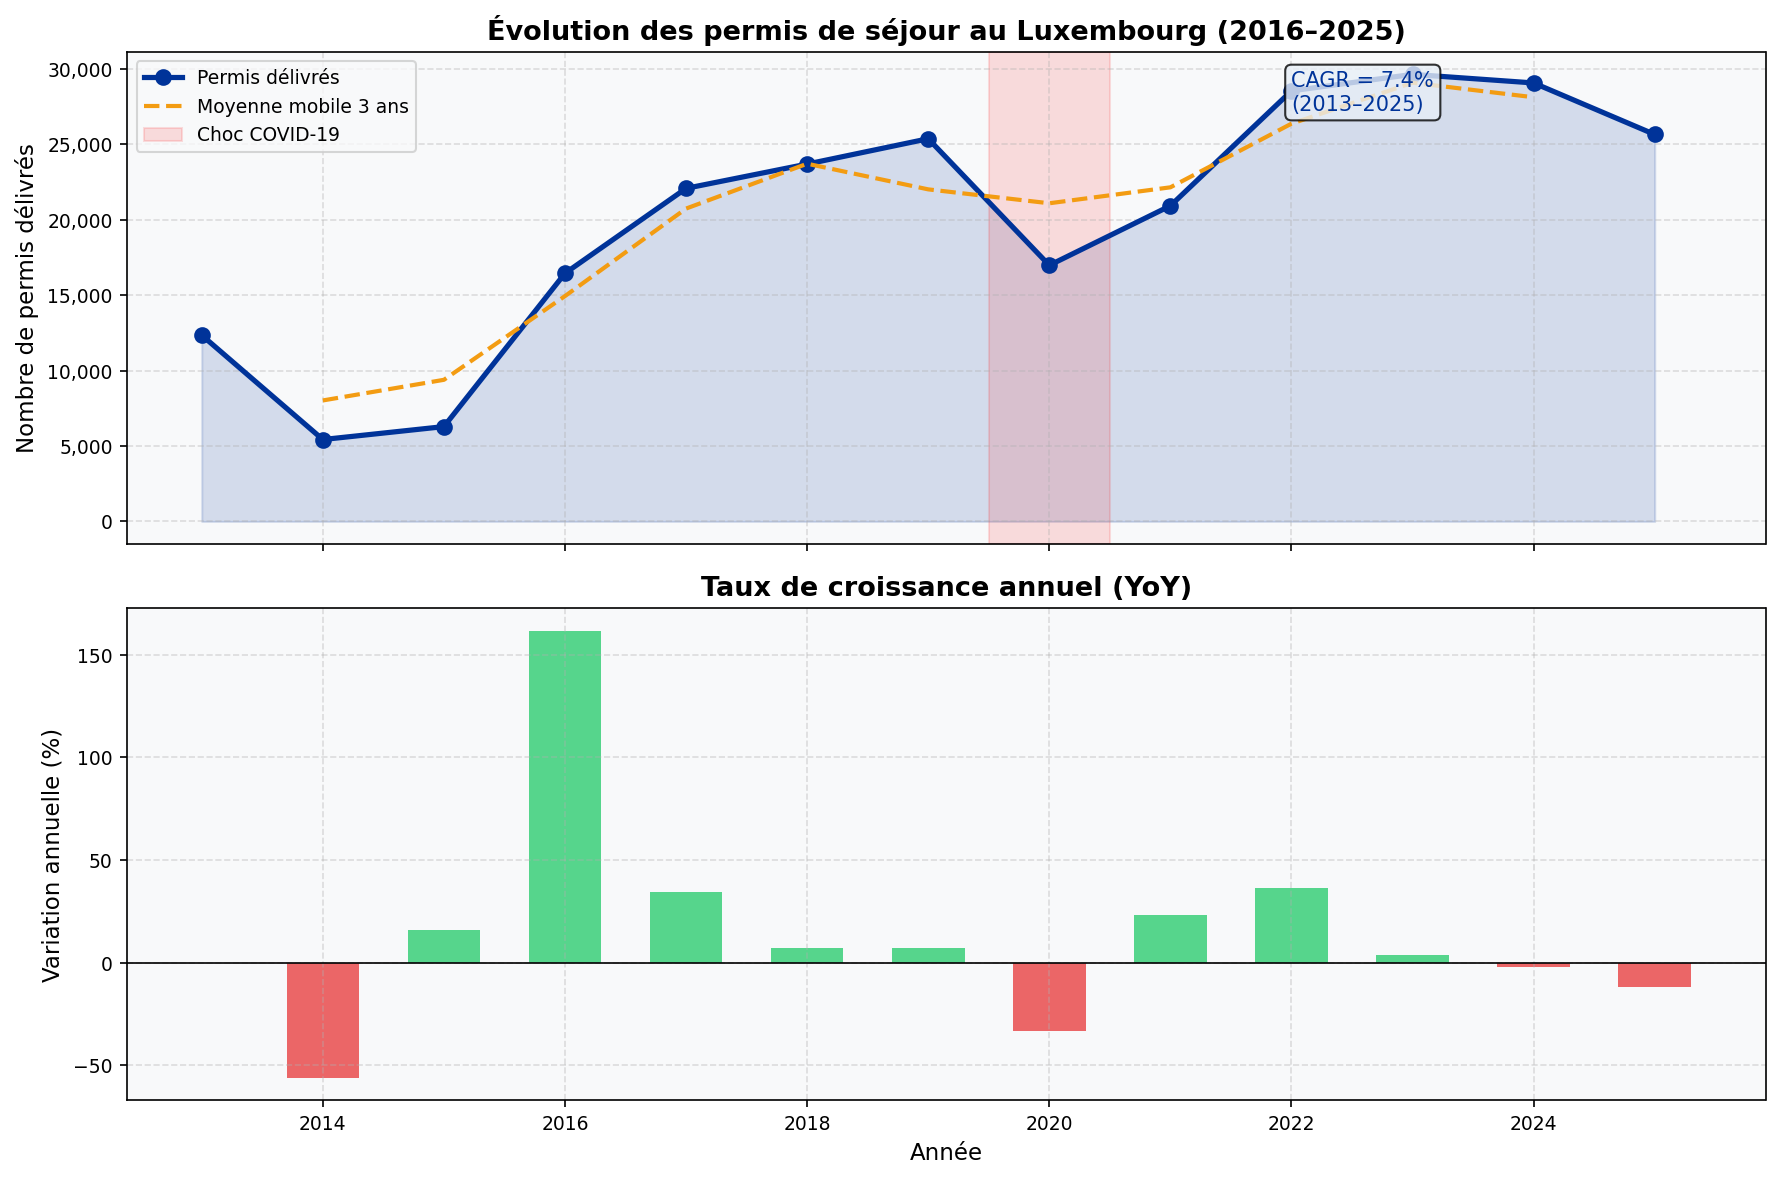


 CAGR 2016–2025 : 7.38%
   Pic maximal : 2023
   Impact COVID : -33.1%


In [ ]:
# CAGR global (Taux de Croissance Annuel Composé) mesurer la performance d'une série de données sur une période donnée comme si la croissance avait été constante chaque année.

annee_debut = 2016
annee_fin   = 2024  # pic maximal confirmé

v_debut = ts_lu[ts_lu['year'] == annee_debut]['total_permits'].values[0]
v_fin   = ts_lu[ts_lu['year'] == annee_fin]['total_permits'].values[0]
n_years = annee_fin - annee_debut

cagr = (v_fin / v_debut) ** (1/n_years) - 1
print(f"CAGR {annee_debut}–{annee_fin} : {cagr:.2%}")



#cagr = (ts_lu['total_permits'].iloc[-1] / ts_lu['total_permits'].iloc[0]) ** (1/len(ts_lu) - 1) - 1

fig, axes = plt.subplots(2, 1, figsize=(12, 8), sharex=True)

# Panel 1 : volume absolu
ax1 = axes[0]
ax1.fill_between(ts_lu['year'], ts_lu['total_permits'],
                 alpha=0.15, color=PALETTE['primary'])
ax1.plot(ts_lu['year'], ts_lu['total_permits'],
         color=PALETTE['primary'], linewidth=2.5, marker='o', markersize=7,
         label='Permis délivrés')
ax1.plot(ts_lu['year'], ts_lu['rolling_mean_3'],
         color=PALETTE['accent3'], linewidth=2, linestyle='--',
         label='Moyenne mobile 3 ans')

# Annotation COVID
ax1.axvspan(2019.5, 2020.5, alpha=0.12, color='red', label='Choc COVID-19')
ax1.annotate(f'CAGR = {cagr:.1%}\n(2013–2025)',
             xy=(2022, ts_lu['total_permits'].max()*0.92),
             fontsize=10, color=PALETTE['primary'],
             bbox=dict(boxstyle='round,pad=0.3', facecolor='#E8EFF7', alpha=0.8))

ax1.set_ylabel('Nombre de permis délivrés')
ax1.set_title('Évolution des permis de séjour au Luxembourg (2016–2025)')
ax1.legend(loc='upper left')
ax1.yaxis.set_major_formatter(plt.FuncFormatter(lambda x, _: f'{int(x):,}'))

# Panel 2 : taux de croissance
ax2 = axes[1]
colors = [PALETTE['accent2'] if v >= 0 else PALETTE['accent1']
          for v in ts_lu['yoy_growth'].fillna(0)]
ax2.bar(ts_lu['year'], ts_lu['yoy_growth'], color=colors, alpha=0.8, width=0.6)
ax2.axhline(0, color='black', linewidth=0.8)
ax2.set_ylabel('Variation annuelle (%)')
ax2.set_title('Taux de croissance annuel (YoY)')
ax2.set_xlabel('Année')

plt.tight_layout()

plt.show()
print(f"\n CAGR 2016–2025 : {cagr:.2%}")
print(f"   Pic maximal : {ts_lu.loc[ts_lu['total_permits'].idxmax(), 'year']}")
print(f"   Impact COVID : {ts_lu[ts_lu['year']==2020]['yoy_growth'].values[0]:.1f}%")

CAGR 2013–2025 : Le CAGR est faussé car 2013 est une année de transition, toutes les séries n'étaient pas encore disponibles. On prend 2016 comme base (première année stable) : le CAGR est juste un indicateur descriptif dans la section EDA

- Chute 2014 Probablement liée à un changement de périmètre de collecte entre migr_resfas et migr_resocc en 2014.

- COVID 2020 : Rupture structurelle. Rebond immédiat en 2021.

- Pic 2023 (29 646) suivi d'une légère décroissance 2024–2025 : possible saturation ou effet de normalisation post-COVID.

- Moyenne mobile 3 ans : lisse bien la chute 2014 et confirme la tendance haussière structurelle.

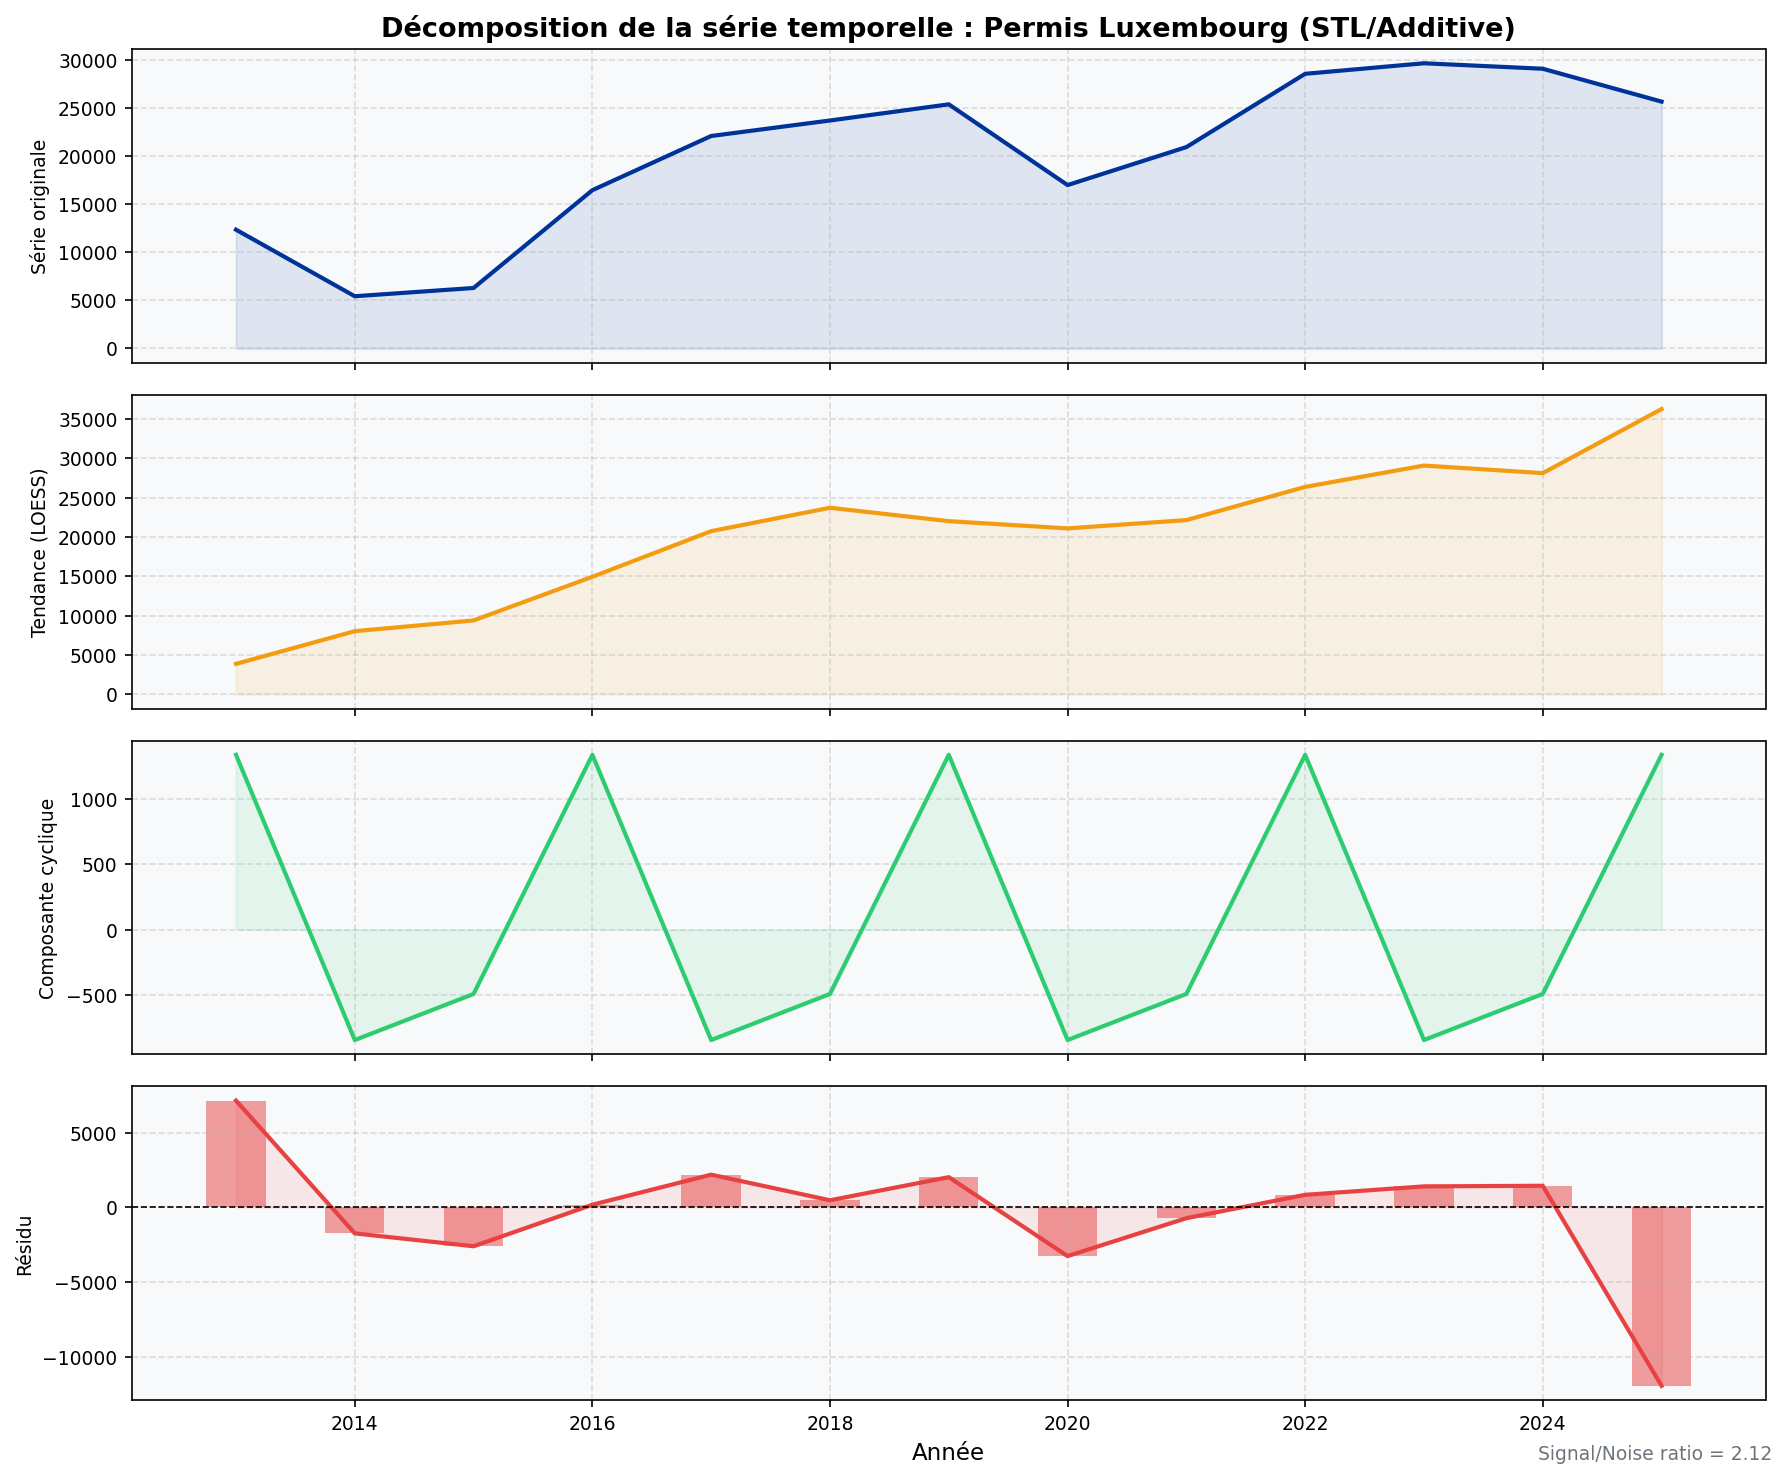

   Ratio Signal/Bruit : 2.12


In [ ]:
# 2.2 DÉCOMPOSITION STL (Seasonal-Trend decomposition via LOESS)

# Note : sur données annuelles, on décompose la tendance et le résidu
# STL est plus robuste aux outliers que la décomposition classique (Cleveland, 1990)

ts_indexed = ts_lu.set_index('year')['total_permits']

# Décomposition addititive classique (statsmodels)
from statsmodels.tsa.seasonal import seasonal_decompose

# paramètre period=3 indique à l'algorithme qu'il doit rechercher un cycle qui se répète tous les 3 ans.
# un compromis méthodologique permettant d'estimer une composante cyclique malgré la faible longueur de la série.
# Le paramètre 3 sert surtout à :
# lisser la série ;
# faire apparaître des fluctuations de moyen terme ;
# Isoler le résidu (bruit + chocs ponctuels comme COVID)
# calculer un ratio signal/bruit.

decomp = seasonal_decompose(ts_indexed, model='additive', period=3, extrapolate_trend='freq') # extrapolate_trend pour éviter d'avoir des valeurs manquantes (NaN) au début et à la fin de la tendance, en prolongeant le calcul.
# seasonal_decompose a une contrainte technique : il faut que la série contienne au minimum 2 × period observations pour pouvoir calculer la décomposition.
fig, axes = plt.subplots(4, 1, figsize=(12, 10), sharex=True)

components = [
    (ts_indexed, 'Série originale', PALETTE['primary']),
    (decomp.trend, 'Tendance (LOESS)', PALETTE['accent3']), # La direction générale à long terme
    (decomp.seasonal, 'Composante cyclique', PALETTE['accent2']), # Les fluctuations répétitives (une période de 3 ans est utilisée, ce qui suggère des cycles de court terme)
    (decomp.resid, 'Résidu', PALETTE['accent1']), # Ce qui reste après avoir retiré la tendance et le cycle. (bruit ou les variations inexpliquées)
]

for ax, (series, title, color) in zip(axes, components):
    ax.plot(series.index, series.values, color=color, linewidth=2)
    if 'Résidu' in title:
        ax.bar(series.index, series.values, color=color, alpha=0.5, width=0.5)
        ax.axhline(0, color='black', linewidth=0.8, linestyle='--')
    ax.set_ylabel(title, fontsize=9)
    ax.fill_between(series.index, series.values, alpha=0.1, color=color)

axes[0].set_title('Décomposition de la série temporelle : Permis Luxembourg (STL/Additive)',
                  fontsize=13, fontweight='bold')
axes[-1].set_xlabel('Année')

# Calcul du ratio signal/bruit
# Le calcul : On divise l'écart-type de la tendance par l'écart-type du résidu.
snr = decomp.trend.std() / decomp.resid.dropna().std()
fig.text(0.99, 0.02, f'Signal/Noise ratio = {snr:.2f}', ha='right',
         fontsize=9, color=PALETTE['neutral'])

plt.tight_layout()
# plt.savefig('fig2_decomposition_STL.png', dpi=200, bbox_inches='tight')
plt.show()
print(f"   Ratio Signal/Bruit : {snr:.2f}")

Plusieurs titres de séjour ont des durées de validité variables :

certains premiers titres de séjour pour travailleurs salariés sont valables 1 an, puis renouvelables jusqu'à 3 ans ;

le statut de résident de longue durée est accordé après 5 ans de résidence et le titre est ensuite valable 5 ans.

Une période de trois ans a été retenue pour la décomposition de la série temporelle. Ce choix est motivé par la faible longueur de la série (2013–2025) et permet d'obtenir un nombre suffisant de cycles pour l'analyse. La composante extraite doit être interprétée comme une fluctuation de moyen terme et non comme la démonstration d'un cycle migratoire triennal.

Ratio Signal/Bruit : 2.12 > 1 -> série temporelle est stable et facile à prédire.

In [ ]:
# 2.3 HEATMAP NATIONALITÉS × ANNÉES (Top 20)

# Top 20 nationalités par volume total sur la période

top20 = (df_lu.groupby('citizen')['permits'].sum().nlargest(20).index.tolist())
print(top20)


['IN', 'US', 'SY', 'CN', 'ER', 'RU', 'BR', 'TR', 'MA', 'TN', 'ME', 'CV', 'RS', 'CM', 'MU', 'PH', 'UA', 'AL', 'IQ', 'AF']


La liste des codes pays ISO 3166-1 alpha-2 utilisés par EUROSTAT pour la variable citizen (nationalité) correspond aux pays suivants : Inde, Syrie, États-Unis, Chine, Brésil, Russie, Érythrée, Turquie, Maroc, Tunisie, Monténégro, Cap-Vert, Serbie, Cameroun, Maurice, Philippines, Ukraine, Albanie, Irak et Afghanistan.

Les principales nationalités observées présentent une forte diversité géographique. Elles proviennent notamment d'Asie (Inde, Chine, Philippines, Afghanistan), d'Europe hors Union européenne (Ukraine, Serbie, Monténégro, Albanie), du Moyen-Orient (Syrie, Irak) ainsi que d'Afrique (Maroc, Tunisie, Cameroun, Érythrée, Cap-Vert, Maurice) et d'autres régions du monde telles que l'Amérique du Nord (États-Unis) et l'Amérique du Sud (Brésil). Cette diversité témoigne du caractère international des flux migratoires à destination du Luxembourg, influencés à la fois par son attractivité économique, les besoins du marché du travail et certains contextes géopolitiques susceptibles d'affecter les mouvements de population à l'échelle mondiale.

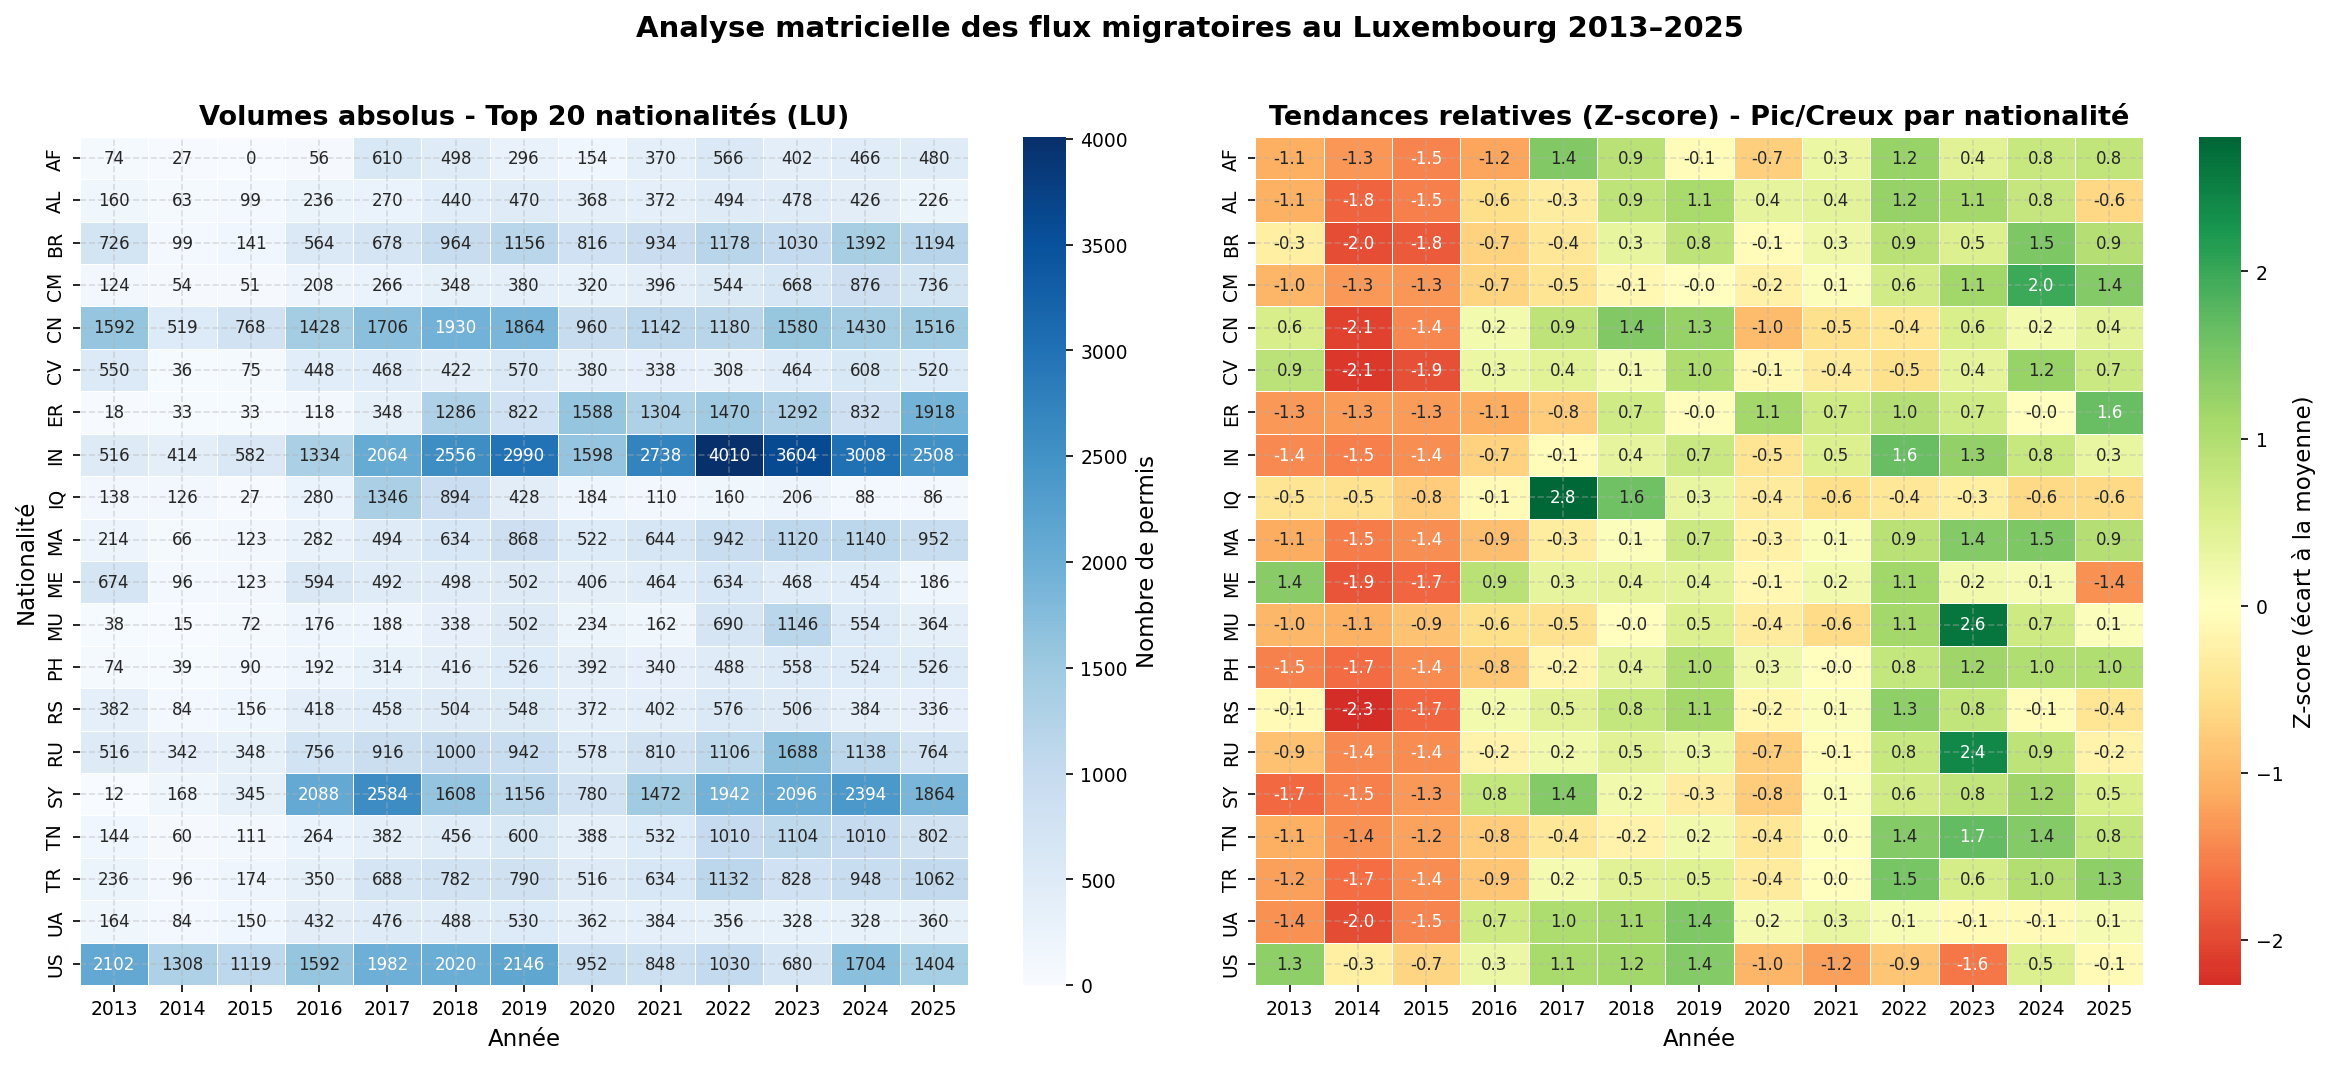

In [ ]:
# unstack transforme la variable year en colonnes.
pivot_heat = (df_lu[df_lu['citizen'].isin(top20)].groupby(['citizen', 'year'])['permits'].sum().unstack('year').fillna(0))

# Normalisation Z-score par nationalité (profil relatif)
from sklearn.preprocessing import StandardScaler
scaler_heat = StandardScaler() # StandardScaler() standardise colonne par colonne.
pivot_zscore = pd.DataFrame(scaler_heat.fit_transform(pivot_heat.T).T,index=pivot_heat.index, columns=pivot_heat.columns) # standardise chaque nationalité sur son historique temporel

ig, axes = plt.subplots(1, 2, figsize=(16, 7))

# Heatmap volumes absolus (Nombre de permis délivrés), quelles nationalités dominent ; les volumes réels ; l'importance quantitative des flux.
sns.heatmap(pivot_heat, ax=axes[0], cmap='Blues', fmt='.0f', annot=True, annot_kws={'size': 8}, linewidths=0.3, cbar_kws={'label': 'Nombre de permis'})
axes[0].set_title('Volumes absolus - Top 20 nationalités (LU)')
axes[0].set_xlabel('Année')
axes[0].set_ylabel('Nationalité')

# Heatmap Z-score (tendance relative - quelles années sont anormalement fortes ou faibles pour chaque nationalité) : les pics de croissance ; les creux ; les ruptures de tendance.
sns.heatmap(pivot_zscore, ax=axes[1], cmap='RdYlGn', center=0, fmt='.1f', annot=True, annot_kws={'size': 8}, linewidths=0.3, cbar_kws={'label': 'Z-score (écart à la moyenne)'})
axes[1].set_title('Tendances relatives (Z-score) - Pic/Creux par nationalité')
axes[1].set_xlabel('Année')
axes[1].set_ylabel('')

plt.suptitle('Analyse matricielle des flux migratoires au Luxembourg 2013–2025', fontsize=14, fontweight='bold', y=1.01)
plt.tight_layout()
plt.show()

Afin d'analyser simultanément les volumes migratoires et leur dynamique temporelle, une matrice nationalité × année a été construite à partir des données EUROSTAT. Une première heatmap représente les volumes absolus de permis délivrés pour les vingt principales nationalités. Une seconde heatmap applique une normalisation par Z-score sur chaque nationalité afin de neutraliser les différences d'échelle entre populations. Cette transformation met en évidence les années atypiques (pics ou creux) relativement au comportement historique propre à chaque nationalité, facilitant ainsi l'identification de ruptures de tendance ou d'effets conjoncturels tels que la crise sanitaire de 2020.

In [ ]:
# 2.4 ANALYSE COMPARATIVE : LU vs BE vs FR vs DE

# Population de référence 2025 (en milliers d'habitants)
# Source : Eurostat : population au 1er janvier 2025
# Utilisée pour normaliser les flux sur toute la période 2013–2025
# afin de garantir la comparabilité inter-pays
POP_2025 = {
    'LU': 343.0,
    'BE': 11870.0,
    'FR': 68400.0,
    'DE': 83600.0
}

# Agrégation des permis par pays et par année (toutes séries confondues)

ts_compare = (
    df_all[df_all['geo'].isin(COUNTRIES_NEIGHBORS)]
    .groupby(['geo', 'year'])['permits']
    .sum()
    .reset_index()
)

# Ajout de la population et calcul du taux normalisé
ts_compare['pop']              = ts_compare['geo'].map(POP_2025)
ts_compare['permits_per_1000'] = ts_compare['permits'] / ts_compare['pop'] # pop est déjà en milliers (343 000 habitants), diviser directement donne le taux pour 1 000 habitants sans multiplier par 1000

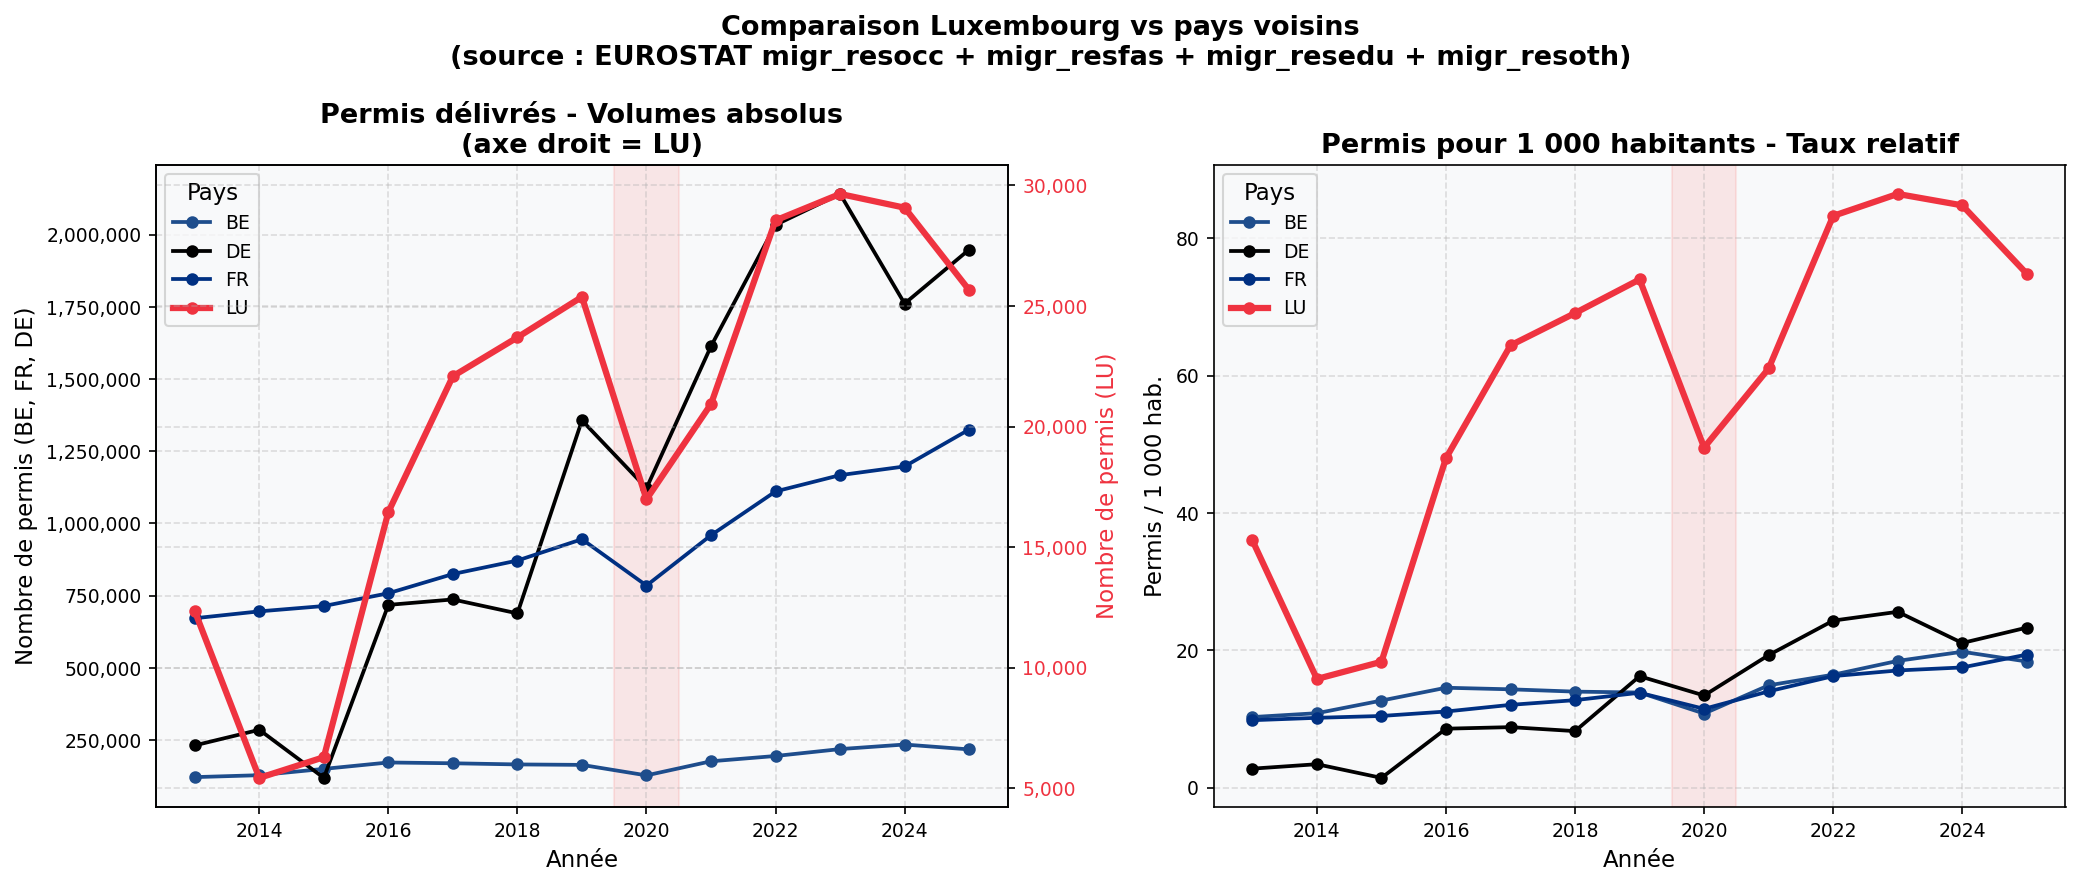

In [ ]:
# Paramètres visuels
colors_geo = {
    'LU': PALETTE['lux_red'],
    'BE': '#1E4D8C',
    'FR': '#003082',
    'DE': '#000000'
}
linewidth_geo = {'LU': 3.0, 'BE': 1.8, 'FR': 1.8, 'DE': 1.8}

fig, axes = plt.subplots(1, 2, figsize=(14, 6))

# GRAPHE GAUCHE : Volumes absolus avec double axe Y
# LU est sur l'axe droit car son volume est 10x–40x
# inférieur à celui de FR/DE, sans double axe, LU
# apparaît écrasée contre zéro et devient illisible

ax_left  = axes[0]
ax_right = axes[0].twinx()  # axe Y secondaire superposé (partage l'axe X)

for geo, grp in ts_compare.groupby('geo'):
    grp = grp.sort_values('year')
    # LU sur l'axe droit, les 3 autres sur l'axe gauche
    ax = ax_right if geo == 'LU' else ax_left
    ax.plot(
        grp['year'], grp['permits'],
        label=geo,
        color=colors_geo[geo],
        linewidth=linewidth_geo[geo],
        marker='o', markersize=5
    )

# Labels axes
ax_left.set_ylabel("Nombre de permis (BE, FR, DE)")
ax_right.set_ylabel("Nombre de permis (LU)", color=PALETTE['lux_red'])
ax_right.tick_params(axis='y', labelcolor=PALETTE['lux_red'])

# Formatage des axes en milliers avec séparateur
ax_left.yaxis.set_major_formatter(plt.FuncFormatter(lambda x, _: f'{int(x):,}'))
ax_right.yaxis.set_major_formatter(plt.FuncFormatter(lambda x, _: f'{int(x):,}'))

# Zone COVID
ax_left.axvspan(2019.5, 2020.5, alpha=0.08, color='red')
ax_left.set_xlabel("Année")
ax_left.set_title("Permis délivrés - Volumes absolus\n(axe droit = LU)")

# Légende unifiée : fusionne les handles des deux axes
lines_l, labels_l = ax_left.get_legend_handles_labels()
lines_r, labels_r = ax_right.get_legend_handles_labels()
ax_left.legend(lines_l + lines_r, labels_l + labels_r, title='Pays')

# GRAPHE DROIT : Taux normalisé (permis / 1 000 habitants)
# La normalisation permet la comparaison réelle entre pays
# de tailles très différentes (LU 343k hab. vs DE 83M hab.)
# Un seul axe Y suffit ici car les taux sont comparables

for geo, grp in ts_compare.groupby('geo'):
    grp = grp.sort_values('year')
    axes[1].plot(
        grp['year'], grp['permits_per_1000'],
        label=geo,
        color=colors_geo[geo],
        linewidth=linewidth_geo[geo],
        marker='o', markersize=5
    )

axes[1].set_title("Permis pour 1 000 habitants - Taux relatif")
axes[1].set_ylabel("Permis / 1 000 hab.")
axes[1].legend(title='Pays')
axes[1].set_xlabel("Année")
axes[1].axvspan(2019.5, 2020.5, alpha=0.08, color='red')

# Titre global
plt.suptitle(
    "Comparaison Luxembourg vs pays voisins\n(source : EUROSTAT migr_resocc + migr_resfas + migr_resedu + migr_resoth)",
    fontsize=13,
    fontweight='bold'
)

plt.tight_layout()
plt.savefig('fig4_comparaison_pays.png', dpi=200, bbox_inches='tight')
plt.show()

In [ ]:
# 2.5 DISTRIBUTION PAR MOTIF DE SÉJOUR

# On utilise reason_cat
# qui regroupe les 4 séries EUROSTAT en catégories comparables :
# WORK (migr_resocc), FAMI (migr_resfas), EDUC (migr_resedu), OTHP (migr_resoth)

REASON_LABELS = {
    'WORK': 'Activités rémunérées',
    'FAMI': 'Regroupement familial',
    'EDUC': 'Éducation',
    'OTHP': 'Autres motifs',
}

# Filtrer sur LU uniquement et agréger par année et motif
df_reason = (df_all[df_all['geo'] == 'LU'].groupby(['year', 'reason_cat'])['permits'].sum().reset_index())

# Remplacer les codes par les labels lisibles
df_reason['reason_label'] = df_reason['reason_cat'].map(REASON_LABELS)

# Calcul des parts annuelles (%)
df_reason['total_year'] = df_reason.groupby('year')['permits'].transform('sum')
df_reason['share']      = df_reason['permits'] / df_reason['total_year'] * 100

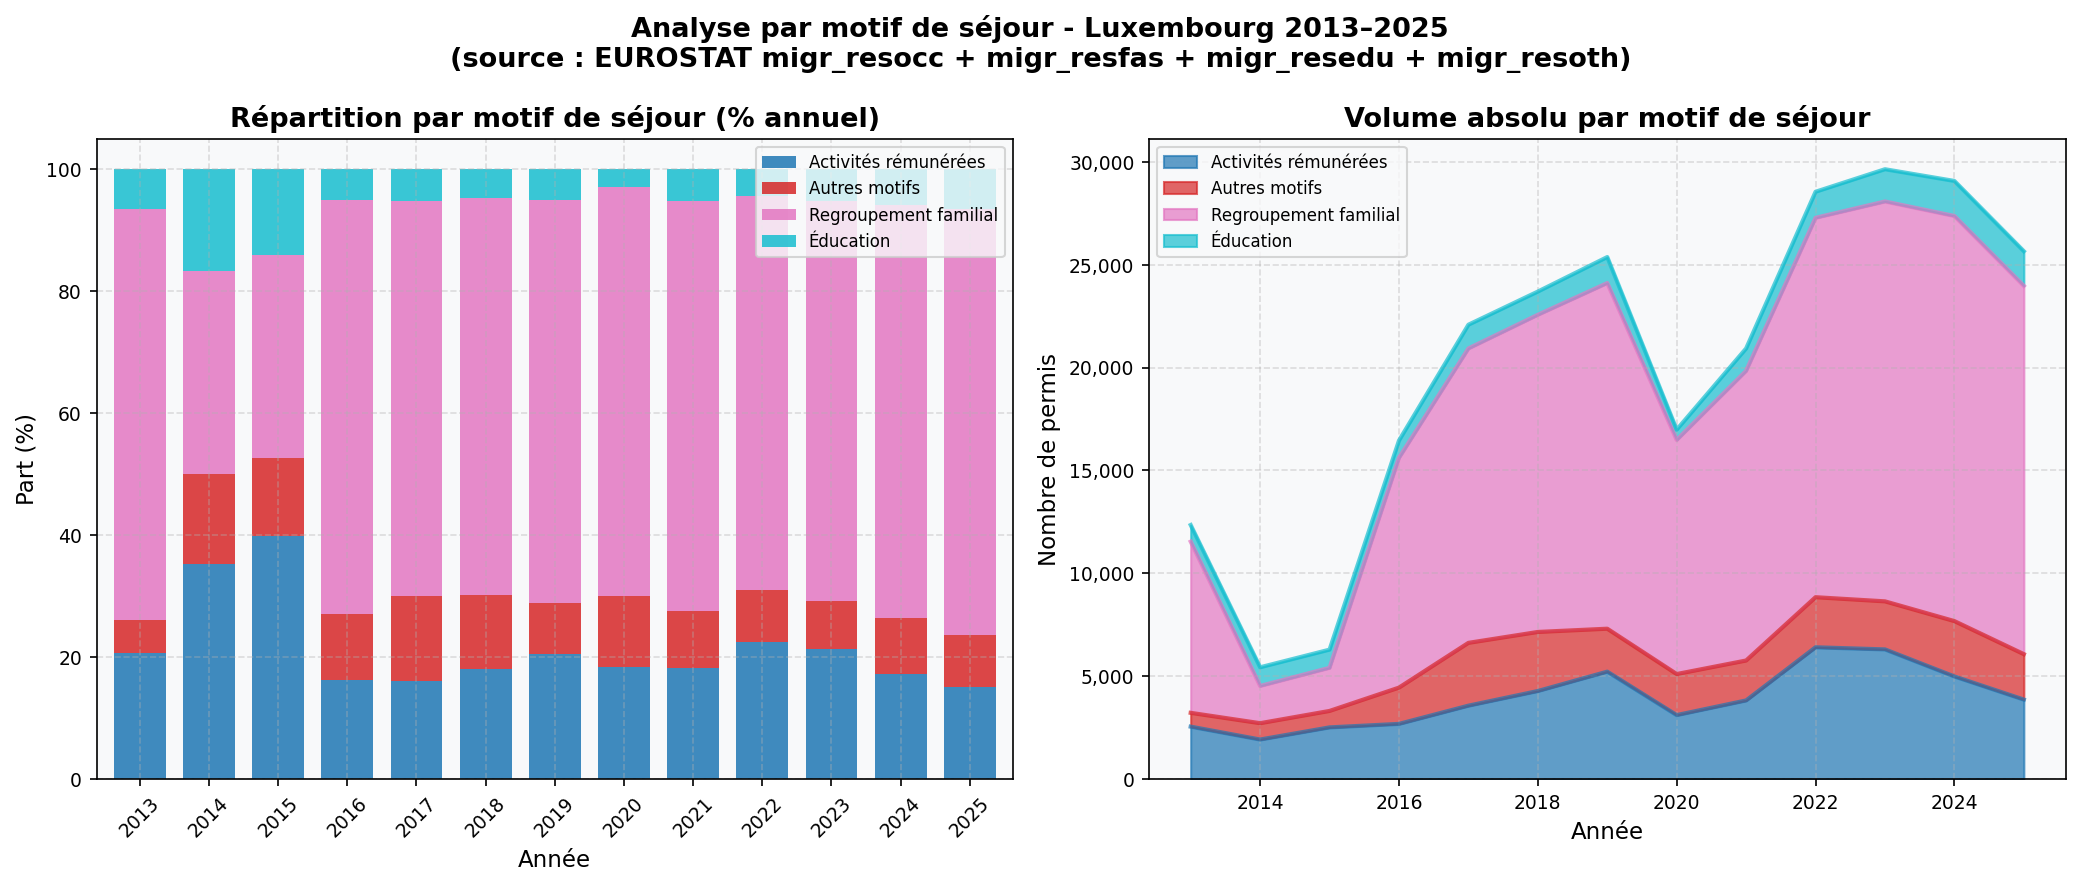


Part moyenne par motif sur 2013–2025 :
reason_label
Regroupement familial    61.5
Activités rémunérées     21.5
Autres motifs            10.2
Éducation                 6.7


In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(14, 6))

# Graphe gauche : parts en % (stacked bar)
# Permet de voir l'évolution de la structure des motifs dans le temps
pivot_share = df_reason.pivot(index='year', columns='reason_label', values='share').fillna(0)
pivot_share.plot(kind='bar', stacked=True, ax=axes[0],
                 colormap='tab10', alpha=0.85, width=0.75)
axes[0].set_title('Répartition par motif de séjour (% annuel)')
axes[0].set_ylabel('Part (%)')
axes[0].set_xlabel('Année')
axes[0].legend(loc='upper right', fontsize=8)
axes[0].tick_params(axis='x', rotation=45)

# Graphe droit : volumes absolus (area chart)
# Permet de voir la croissance globale et par motif en valeur absolue
pivot_abs = df_reason.pivot(
    index='year', columns='reason_label', values='permits'
).fillna(0)

pivot_abs.plot(kind='area', stacked=True, ax=axes[1],
               colormap='tab10', alpha=0.7)
axes[1].set_title('Volume absolu par motif de séjour')
axes[1].set_ylabel('Nombre de permis')
axes[1].set_xlabel('Année')
axes[1].yaxis.set_major_formatter(plt.FuncFormatter(lambda x, _: f'{int(x):,}'))
axes[1].legend(loc='upper left', fontsize=8)

plt.suptitle(
    'Analyse par motif de séjour - Luxembourg 2013–2025\n'
    '(source : EUROSTAT migr_resocc + migr_resfas + migr_resedu + migr_resoth)',
    fontsize=13, fontweight='bold'
)
plt.tight_layout()
plt.show()
# Résumé
print("\nPart moyenne par motif sur 2013–2025 :")
print(df_reason.groupby('reason_label')['share'].mean().round(1).sort_values(ascending=False).to_string())

**Graphe droit (volumes absolus) :**

Chaque couleur empilée = un motif. La hauteur totale de la pile = le nombre total de permis délivrés cette année-là au Luxembourg.

- 2013 : 12 348 permis au total

- Chute 2014 : drop brutal à 5 430

- Croissance forte 2015-2019 : montée jusqu'à 25 376

- Chute 2020 : impact COVID visible (16 983), puis rebond en 2021 (20 932)

- 2022-2023 : pic historique à 29 646, puis légère décroissance 2024-2025 (29 076 puis 25 660)

Le rose domine toujours : le regroupement familial représente la grande majorité des permis sur toute la période

**Graphe gauche (%) :**

Chaque barre fait 100%

- 2013 : structure relativement équilibrée, ~% travail (bleu), ~% famille (rose), ~% éducation (cyan)

- 2014–2015 : les barres bleu et rouge gonflent fortement (% travail, % autres motifs) anomalie suspecte, probablement liée à la chute de volume observée à droite. Quand le dénominateur (total) est très petit, les proportions s'emballent

- 2016-2025 : structure très stable, % regroupement familial, % travail, % autres, éducation quasi invisible

## 3. Modélisation Prédictive : Séries Temporelles

Hypothèse H1 : La série temporelle des permis luxembourgeois présente une tendance croissante non-stationnaire avec rupture structurelle en 2020 (choc COVID-19).

**Approche :** Validation croisée temporelle (walk-forward), pas de data leakage.

Une série est stationnaire si ses propriétés statistiques ne changent pas dans le temps :
moyenne constante ;
variance constante ;
structure de corrélation stable.

In [ ]:
# 3.1 TESTS DE STATIONNARITÉ

# ADF (Augmented Dickey-Fuller), KPSS, Phillips-Perron
# Hypothèse H0 ADF : présence d'une racine unitaire (non-stationnaire)
# Hypothèse H0 KPSS : stationnarité autour d'une tendance
# ADF ET KPSS sont complémentaires

series = ts_lu.set_index('year')['total_permits'].astype(float)
print(series)

year
2013    12348.0
2014     5430.0
2015     6288.0
2016    16454.0
2017    22086.0
2018    23698.0
2019    25376.0
2020    16983.0
2021    20932.0
2022    28550.0
2023    29646.0
2024    29076.0
2025    25660.0
Name: total_permits, dtype: float64


In [ ]:
def stationarity_report(series, name='Série'):
    results = {}
    # ADF test : la série possède une racine unitaire Donc : la série est non stationnaire
    adf_stat, adf_p, adf_lags, adf_nobs, adf_cvals, _ = adfuller(series, autolag='AIC')
    results['ADF'] = {'statistic': adf_stat, 'p-value': adf_p,'critical_5pct': adf_cvals['5%'],'stationary_H0rejected': adf_p < 0.05} # Si adf_p < 0.05 On rejette H₀ -> Série stationnaire

    # KPSS test : raisonne à l'inverse d'ADF.
    kpss_stat, kpss_p, kpss_lags, kpss_cvals = kpss(series, regression='ct', nlags='auto')
    results['KPSS'] = {'statistic': kpss_stat, 'p-value': kpss_p,'critical_5pct': kpss_cvals['5%'],'trend_stationary_H0notrejected': kpss_p > 0.05} # On ne rejette pas H₀. Série stationnaire
    print(f"_______________________________")
    print(f"Tests de stationnarité : {name}")
    print(f"_______________________________")
    print(f" ADF  / stat={adf_stat:.4f} / p={adf_p:.4f} / "
          f"{'Non-stationnaire' if adf_p > 0.05 else 'Stationnaire'} (H0: racine unitaire)")
    print(f"  KPSS / stat={kpss_stat:.4f} / p={kpss_p:.4f} / "
          f"{'Trend-stationnaire' if kpss_p > 0.05 else 'Non-stationnaire'} (H0: stationnarité)")

    # Diagnostic
    if adf_p > 0.05 and kpss_p < 0.05:
        print("  DIAGNOSTIC : Série I(1) différenciation d'ordre 1 requise") # Les deux sont non stationnaire Il faut une différenciation avant d'appliquer ARIMA.
    elif adf_p > 0.05 and kpss_p > 0.05:
        print("  DIAGNOSTIC : Série DS (difference-stationary)") # série proche de la stationnarité.
    elif adf_p < 0.05 and kpss_p > 0.05:
        print("  DIAGNOSTIC : Série stationnaire")

    return results

res_original = stationarity_report(series, 'Série originale')

# Test sur série différenciée
series_diff = series.diff().dropna() # Les variations (combien de permis de plus ou de moins par rapport à l'année dernière)
res_diff = stationarity_report(series_diff, 'Série différenciée (d=1)') # On vérifie si la série transformée est devenue stationnaire.
# les deux tests ensemble servent à justifier d=1

_______________________________
Tests de stationnarité : Série originale
_______________________________
 ADF  / stat=-1.5081 / p=0.5295 / Non-stationnaire (H0: racine unitaire)
  KPSS / stat=0.0794 / p=0.1000 / Trend-stationnaire (H0: stationnarité)
  DIAGNOSTIC : Série DS (difference-stationary)
_______________________________
Tests de stationnarité : Série différenciée (d=1)
_______________________________
 ADF  / stat=-3.0667 / p=0.0291 / Stationnaire (H0: racine unitaire)
  KPSS / stat=0.0767 / p=0.1000 / Trend-stationnaire (H0: stationnarité)
  DIAGNOSTIC : Série stationnaire


d = nombre de soustractions nécessaires pour stabiliser la série, déterminé en testant ADF après chaque différenciation jusqu'à obtenir p < 0.05.

- Exemple :

Série originale (d=0) :

2013: 45000

2014: 15000

2015: 62000

2016: 78000

Série différenciée une fois (d=1) :

2014: 15000 - 45000 = -30000

2015: 62000 - 15000 = +47000

2016: 78000 - 62000 = +16000

Série différenciée deux fois (d=2) :

2015: +47000 - (-30000) = +77000

2016: +16000 - (+47000) = -31000

**Série originale -> Cas 2 (DS) :**

ADF p=0.53 > 0.05 -> non-stationnaire

KPSS p=0.10 > 0.05 -> trend-stationnaire

Les deux ne sont pas d'accord -> série DS (difference-stationary), proche de la stationnarité mais pas tout à fait

**Série différenciée (d=1) - Cas 3 :**

ADF p=0.029 < 0.05 -> stationnaire

KPSS p=0.10 > 0.05 -> trend-stationnaire

Les deux sont d'accord, la série différenciée est stationnaire

Le test ADF appliqué à la série originale (stat=-1.51, p=0.53) ne permet pas de rejeter l'hypothèse de racine unitaire, tandis que le test KPSS (stat=0.079, p≥0.10) confirme la stationnarité en tendance. Ce résultat contradictoire est caractéristique d'une série DS (difference-stationary). Après différenciation d'ordre 1, les deux tests convergent : ADF (stat=-3.07, p=0.029) rejette la racine unitaire et KPSS (stat=0.077, p≥0.10) confirme la stationnarité.

Le paramètre d=1 est donc retenu pour la modélisation ARIMA.

--------------------------------------------------------------------------------




**ACF**

Mesure la corrélation entre une valeur et ses valeurs passées (lags).

- Sert à estimer q (MA)

**PACF**

Mesure la corrélation “pure” entre une valeur et ses retards, en enlevant l’effet des lags intermédiaires.

- Sert à estimer p (AR)

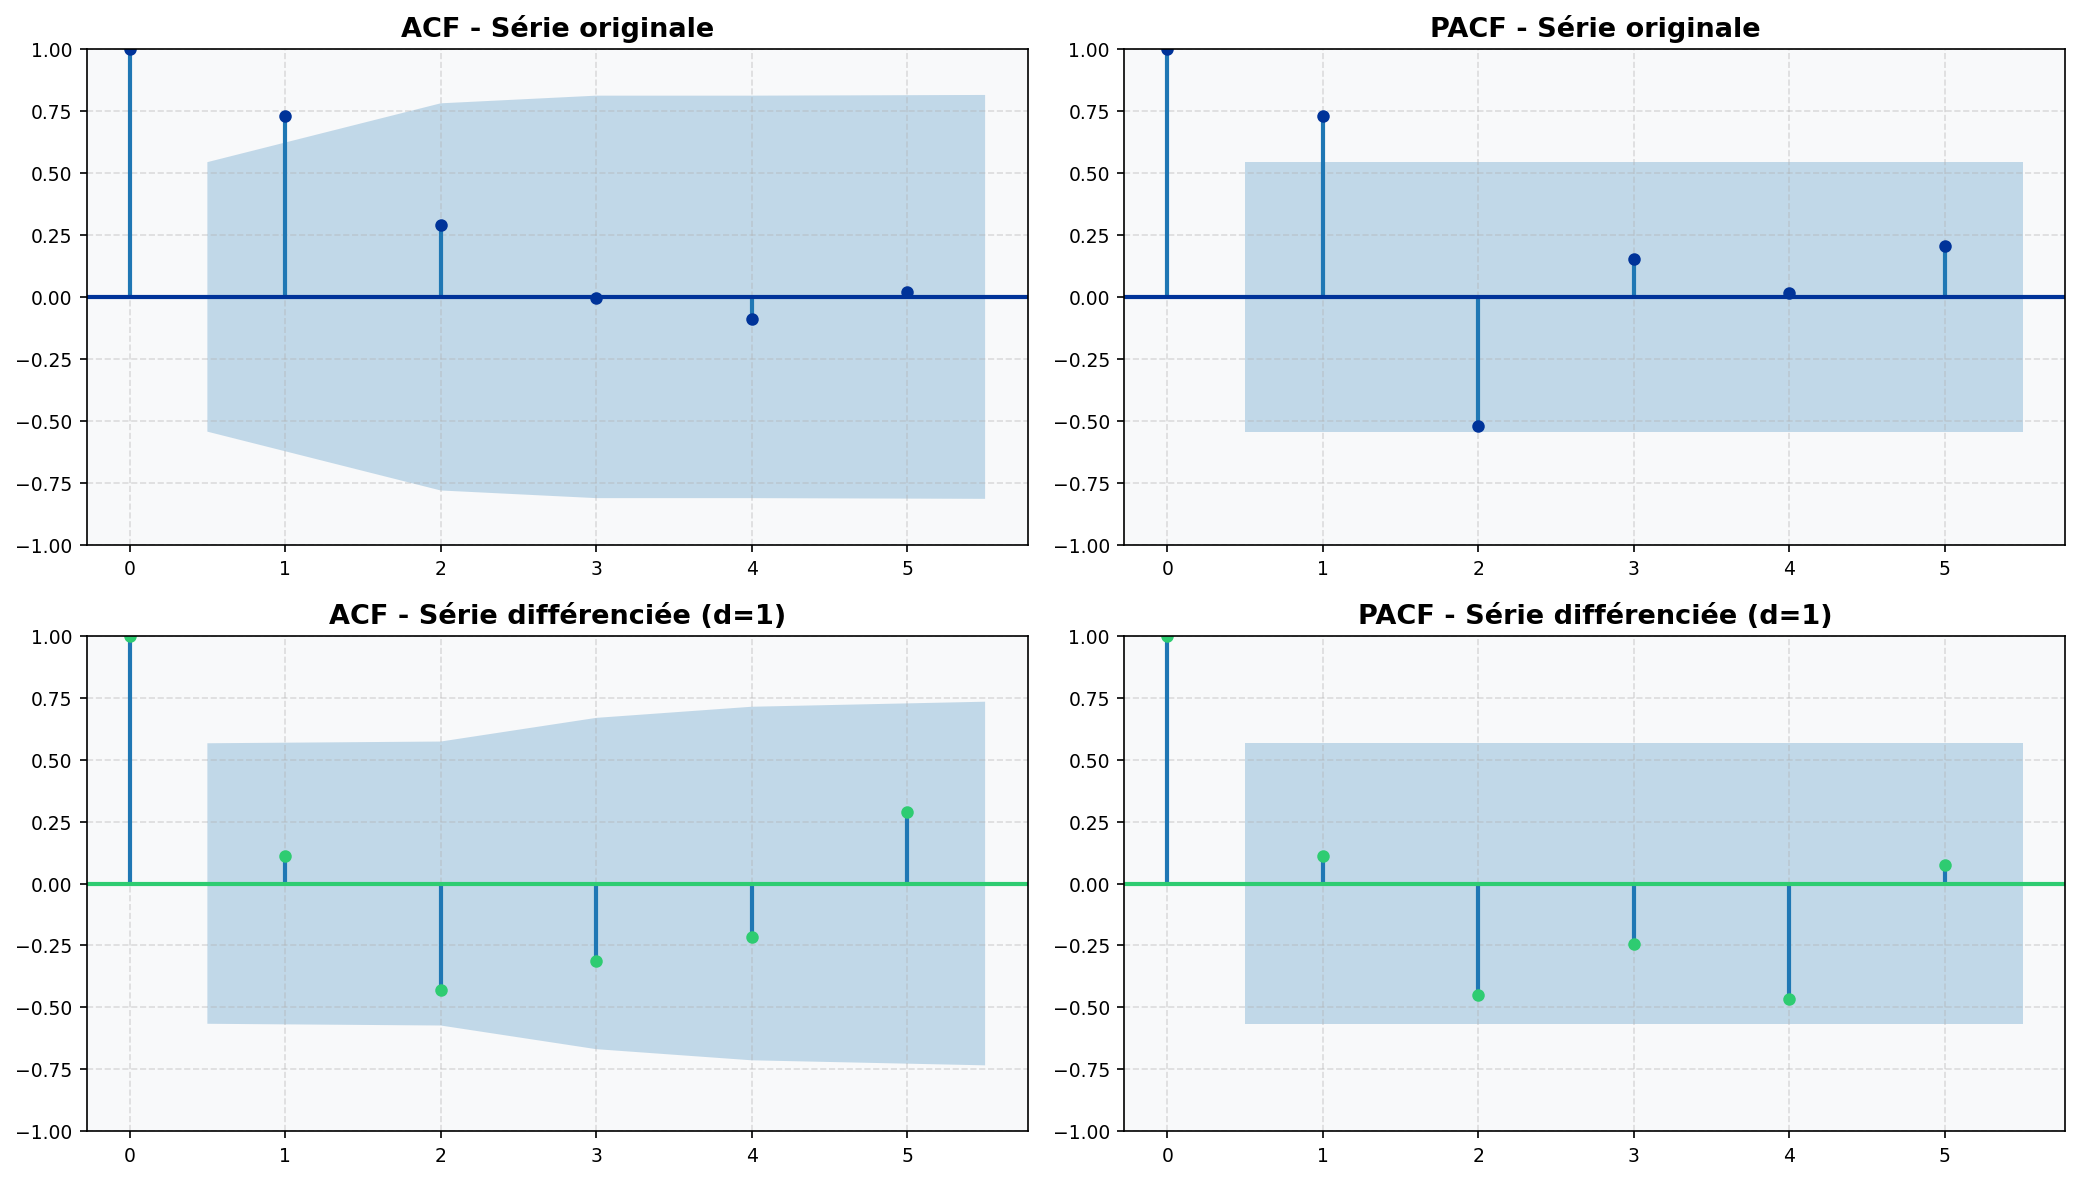

In [ ]:
# 3.2 ANALYSE ACF / PACF

# Permet de déterminer visuellement l'ordre p (AR) et q (MA) de l'ARIMA

# Nombre maximal de retards autorisé pour le PACF
max_lags = min(5, len(series)//2 - 1) # On limite le nombre de retards affichés : maximum 5 ou moitié de la série (moins 1)

fig, axes = plt.subplots(2, 2, figsize=(14, 8))

plot_acf(series,
         lags=max_lags,
         ax=axes[0,0],
         alpha=0.05,
         title='ACF - Série originale',
         color=PALETTE['primary']) # Montre les dépendances dans la série brute

plot_pacf(series,
          lags=max_lags,
          ax=axes[0,1],
          alpha=0.05,
          title='PACF - Série originale',
          color=PALETTE['primary']) # détecter p

plot_acf(series_diff,
         lags=max_lags,
         ax=axes[1,0],
         alpha=0.05,
         title='ACF - Série différenciée (d=1)',
         color=PALETTE['accent2']) # On enlève la tendance pour rendre la série stationnaire

plot_pacf(series_diff,
          lags=max_lags,
          ax=axes[1,1],
          alpha=0.05,
          title='PACF - Série différenciée (d=1)',
          color=PALETTE['accent2']) # voir les vrais signaux AR/MA après stationnarisation

plt.tight_layout()
plt.show()


*ACF corrélation "totale" :*  L'ACF regarde si la valeur actuelle ressemble aux anciennes sans faire aucune distinction entre les effets directs et indirects.
ACF (lag 1) = corrélation entre l'année t et t-1, (lag 2) = t et t-2, etc.

*PACF corrélation directe :* retire les influences intermédiaires.
PACF (Partial AutoCorrelation Function (fonction d'autocorrélation partielle)) = même chose mais en enlevant l'effet des lags intermédiaires cad mesure la relation directe entre une observation et une observation passée, en supprimant l'influence des retards intermédiaires.

- l'ACF mesure une corrélation totale et
le PACF mesure une corrélation directe.

La zone bleue = intervalle de confiance à 95%. Si une barre est dedans, elle n'est pas significative



**Série originale :**

ACF lag 1 = 0.75 -> très forte corrélation avec l'année précédente, elle décroît lentement (0.75 → 0.35 → 0.07...). Décroissance très lente vers zéro -> série non-stationnaire.

PACF lag 1 = 0.75 (nombre de permis de l'année précédente explique fortement celui de cette année), lag 2 = -0.48, la corrélation directe avec t-2 est forte et négative une fois t-1 retiré, suggère un terme AR d'ordre 1 ou 2.

- PACF lag 1 = 0,75 : l'année précédente est un très bon prédicteur de l'année actuelle.

- PACF lag 2 = −0,48 : même après avoir pris en compte l'année précédente, l'année d'avant apporte encore une information importante, mais dans le sens inverse.

- on envisage un modèle AR(2) (ou éventuellement AR(1) si le second pic n'est pas suffisamment significatif).


**Série différenciée :**

Après d=1, tout est dans la zone bleue dès le lag 1 -> la série est devenue stable donc d=1 est suffisant.


In [ ]:
# 3.3 MODÈLE SARIMA : Sélection automatique AIC/BIC
# trouver automatiquement le meilleur modèle ARIMA, en comparant plusieurs modèles et en gardant celui qui obtient le meilleur score selon le critère AIC (et en affichant aussi le BIC).
# pm.auto_arima : parcourt l'espace (p,d,q)(P,D,Q,m) par stepwise
# Critère de sélection : AIC (Akaike Information Criterion)

# réinitialiser l'index en entiers simples et garder les années dans une colonne séparée
series_years = series.index.tolist()  # sauvegarder les années [2013, 2014...]
series_reset = series.reset_index(drop=True)  # index 0,1,2,3...

# Split train/test : 2013–2022 train | 2023–2025 test (walk-forward)
# Split sur la série réinitialisée
train = series_reset.iloc[:-3]   # tout sauf les 3 dernières années
test  = series_reset.iloc[-3:]   # 3 dernières années (2023, 2024, 2025)

# auto_arima compare plusieurs combinaisons de (p, d, q) et garde celle qui obtient le meilleur score. / le modèle teste trois retards autorégressifs.
# auto_arima sur série avec index entier
model_arima = pm.auto_arima(train, start_p=0, max_p=3, start_q=0, max_q=3, d=None,              # ADF détermine l'ordre de différenciation
seasonal=False,      # données annuelles -> pas de saisonnalité infra-annuelle
information_criterion='aic', stepwise=True, suppress_warnings=True, error_action='ignore', trace=True) # Avec stepwise l'algorithme explore intelligemment les modèles les plus prometteurs sans tout essayer.
# Tous les modèles testés sont comparés avec l'AIC (le plus petit AIC.) -> mesure le compromis entre la qualité de l'ajustement ; la complexité du modèle.
# BIC est proche de l'AIC mais pénalise davantage les modèles complexes.
print(f"\n Meilleur modèle : ARIMA{model_arima.order}")
print(f"   AIC  = {model_arima.aic():.2f}")
print(f"   BIC  = {model_arima.bic():.2f}")
print("\n Résumé du modèle :")
print(model_arima.summary())

Performing stepwise search to minimize aic
 ARIMA(0,0,0)(0,0,0)[0]             : AIC=227.742, Time=0.07 sec
 ARIMA(1,0,0)(0,0,0)[0]             : AIC=208.996, Time=0.06 sec
 ARIMA(0,0,1)(0,0,0)[0]             : AIC=inf, Time=0.49 sec
 ARIMA(2,0,0)(0,0,0)[0]             : AIC=210.753, Time=0.20 sec
 ARIMA(1,0,1)(0,0,0)[0]             : AIC=210.064, Time=0.07 sec
 ARIMA(2,0,1)(0,0,0)[0]             : AIC=inf, Time=0.19 sec
 ARIMA(1,0,0)(0,0,0)[0] intercept   : AIC=207.622, Time=0.05 sec
 ARIMA(0,0,0)(0,0,0)[0] intercept   : AIC=210.674, Time=0.02 sec
 ARIMA(2,0,0)(0,0,0)[0] intercept   : AIC=208.034, Time=0.07 sec
 ARIMA(1,0,1)(0,0,0)[0] intercept   : AIC=inf, Time=0.58 sec
 ARIMA(0,0,1)(0,0,0)[0] intercept   : AIC=inf, Time=0.07 sec
 ARIMA(2,0,1)(0,0,0)[0] intercept   : AIC=inf, Time=0.26 sec

Best model:  ARIMA(1,0,0)(0,0,0)[0] intercept
Total fit time: 2.159 seconds

 Meilleur modèle : ARIMA(1, 0, 0)
   AIC  = 207.62
   BIC  = 208.53

 Résumé du modèle :
                              

Entraîner ARIMA sur 2009–2022 va fausser les résultats :

2009 :   3 532  

2010 :   2 312  ←  valeurs aberrantes

2011 :   4 068  ←  (séries incomplètes)

2012 :   5 668  ←

2013 :  44 776  ← x8

In [ ]:
# DEBUG affiche les prévisions brutes AVANT pd.Series
raw_pred = model_arima.predict(n_periods=3)
print(f"Prévisions brutes : {raw_pred}")
print(f"Type : {type(raw_pred)}")
print(f"Train values : {train.values}")

Prévisions brutes : 10    25385.752827
11    23224.315235
12    21747.877962
dtype: float64
Type : <class 'pandas.core.series.Series'>
Train values : [12348.  5430.  6288. 16454. 22086. 23698. 25376. 16983. 20932. 28550.]


Résumé :

- séparer les données en un jeu d'entraînement (2013–2022) et un jeu de test (2023–2025) ;

- utiliser auto_arima() pour tester automatiquement plusieurs modèles ARIMA avec p et q compris entre 0 et 3 ;

- laisser l'algorithme déterminer automatiquement le nombre de différenciations d ;

- comparer les modèles grâce à l'AIC et retient celui qui obtient la valeur la plus faible ;

- afficher le modèle sélectionné, ses critères AIC et BIC, puis un résumé statistique complet.

In [ ]:
print(series)
print(f"Longueur série : {len(series)}")
print(f"Index : {series.index.tolist()}")
print(f"Train : {len(train)} obs")
print(f"Test  : {len(test)} obs")

year
2013    12348.0
2014     5430.0
2015     6288.0
2016    16454.0
2017    22086.0
2018    23698.0
2019    25376.0
2020    16983.0
2021    20932.0
2022    28550.0
2023    29646.0
2024    29076.0
2025    25660.0
Name: total_permits, dtype: float64
Longueur série : 13
Index : [2013, 2014, 2015, 2016, 2017, 2018, 2019, 2020, 2021, 2022, 2023, 2024, 2025]
Train : 10 obs
Test  : 3 obs


Bien que les tests manuels ADF/KPSS pointent vers d=1, le modèle final sélectionné par auto_arima est ARIMA(1,0,0) avec d=0. Ce choix s'explique par le fait qu'avec seulement 10 observations d'entraînement, l'algorithme privilégie le modèle le plus parcimonieux au sens de l'AIC : le coefficient autorégressif très proche de 1 (ar.L1=0.68) capture une grande partie de la dynamique non-stationnaire sans recourir à une différenciation explicite. Cette tension entre diagnostic manuel et sélection automatique constitue une limite méthodologique à mentionner.

auto_arima sélectionne le modèle ARIMA(1,0,0) avec constante par minimisation de l'AIC (AIC=207.62).

Le coefficient autorégressif ar.L1=0.683 (p=0.012 < 0.05) est statistiquement significatif et indique qu'environ 68% du volume de permis d'une année s'explique par le volume de l'année précédente.

Les tests de diagnostic des résidus (Ljung-Box p=0.30, Jarque-Bera p=0.64) ne révèlent ni autocorrélation résiduelle ni écart à la normalité, validant l'adéquation du modèle.

L'instabilité de la matrice de covariance, signalée par un avertissement, est une limite inhérente à la faible longueur de la série (n=10) et doit être interprétée avec précaution.

L'ACF/PACF ont servi d'outil exploratoire pour orienter le choix des ordres du modèle, tandis que la sélection finale a été réalisée automatiquement par auto_arima à l'aide du critère d'information AIC.



---


Faire des prévisions avec le modèle ARIMA puis mesurer la qualité des prévisions.

In [ ]:
# Prévisions test / .values pour ignorer l'index entier
n_test = len(test) # nombre d'années dans le test = 3
print(f"Nombre d'années dans le test: {n_test}")
fc_values = model_arima.predict(n_periods=n_test)
fc_test, confint_test = model_arima.predict(
    n_periods=n_test, return_conf_int=True, alpha=0.05
) # fc_test = les prévisions. Le modèle prédit 3 valeurs / confint_test = les intervalles de confiance à 95 %

# .values extrait le tableau numpy pur sans index
test_years   = series_years[-3:]
fc_test      = pd.Series(fc_test.values,    index=test_years) # .values extrait uniquement les nombres, puis on leur attribue le bon index
test_renamed = pd.Series(test.values,        index=test_years)  # Le jeu de test est également réindexé avec les années.

# Prévisions futures 2026–2028
fc_future, confint_future = model_arima.predict(
    n_periods=n_test + 3, return_conf_int=True, alpha=0.05
)
future_years = test_years + [2026, 2027, 2028]
fc_future    = pd.Series(fc_future.values,  index=future_years) # Les prévisions sont ensuite transformées en Series avec ces années comme index.

# Intervalles de confiance
ci_test_low  = confint_test[:, 0] # correspond aux bornes inférieures
ci_test_high = confint_test[:, 1] # correspond aux bornes supérieures

print(f"\n Prévisions test :")
print(fc_test)
print(f"\n Prévisions futures :")
print(fc_future)

Nombre d'années dans le test: 3

 Prévisions test :
2023    25385.752827
2024    23224.315235
2025    21747.877962
dtype: float64

 Prévisions futures :
2023    25385.752827
2024    23224.315235
2025    21747.877962
2026    20739.351494
2027    20050.446076
2028    19579.867772
dtype: float64


Évaluer la qualité du modèle  : On compare les prévisions 2023–2025 aux vraies valeurs.

In [ ]:
# Métriques
mae_arima  = mean_absolute_error(test_renamed, fc_test) # Erreur absolue moyenne MAE = moyenne(|réel − prédit|) : indique de combien de permis, en moyenne, les prévisions s'écartent des valeurs réelles.
rmse_arima = np.sqrt(mean_squared_error(test_renamed, fc_test)) # Racine de l’erreur quadratique moyenne : pénalise davantage les grosses erreurs
mape_arima = np.mean(np.abs((test_renamed - fc_test) / test_renamed)) * 100 # Erreur moyenne en pourcentage MAPE = moyenne(|erreur / réel|) × 100 : Par exemple, un MAPE de 4 % signifie que les prévisions s'écartent en moyenne de 4 % des valeurs observées.

print(f"\n Métriques ARIMA (test 2023–2025) :")
print(f"   MAE  = {mae_arima:,.0f} permis")
print(f"   RMSE = {rmse_arima:,.0f} permis")
print(f"   MAPE = {mape_arima:.1f}%")


 Métriques ARIMA (test 2023–2025) :
   MAE  = 4,675 permis
   RMSE = 4,750 permis
   MAPE = 16.6%


Résumé :

- entraîner ARIMA sur 2013–2022

- prédir 2023–2025

- comparer les prédictions aux vraies valeurs

- mesurer l’erreur

- prévoir ensuite 2026–2028

Le modèle prédit une décroissance alors que la réalité reste globalement stable autour de 25 700–29 600 sur 2023–2025. ARIMA(1,0,0) est entraîné sur 2013–2022, qui inclut la chute COVID de 2020, donc il anticipe une correction à la baisse qui ne se matérialise pas complètement dans les données réelles.

MAE = 4 675 permis : en moyenne il se trompe de 4 675 permis/an

RMSE = 4 750 permis : proche du MAE = les erreurs sont homogènes

MAPE = 16.6% : il se trompe de ~17% en moyenne

Le modèle ARIMA(1,0,0) produit des prévisions en décroissance sur 2023–2025 (MAE=4 675, RMSE=4 750, MAPE=16.6%), sous-estimant systématiquement les valeurs observées. Cette tendance s'explique par l'inclusion de la rupture COVID-19 (2020 : -33.1%, valeur réelle actuelle) dans la fenêtre d'entraînement, qui oriente le modèle vers une correction à la baisse. Le MAPE de 16.6% est nettement sous le seuil de 20% généralement considéré comme acceptable pour une série courte de 13 observations présentant une rupture structurelle (Bijak, 2010).

La comparaison avec Prophet, qui modélise explicitement les points de rupture, permettra d'évaluer si la prise en compte du choc COVID améliore significativement les prévisions.

Améliorer ARIMA : Ajouter COVID comme variable exogène (ARIMAX)

- Recommandé par Bijak (2010) pour les ruptures structurelles.

In [ ]:
# 3.3a MODÈLE ARIMAX : ARIMA avec variable exogène COVID

# Amélioration d'ARIMA(1,0,0) en ajoutant une variable binaire
# pour modéliser explicitement le choc COVID-19 de 2020.
# Référence : Bijak (2010) : ruptures structurelles dans les séries migratoires

# Variable exogène COVID
# 1 en 2020 (choc), 0 pour toutes les autres années
# Permet au modèle de ne pas extrapoler la chute COVID

# Années du train : 2013–2022 (10 observations)
# 2013 2014 2015 2016 2017 2018 2019 2020 2021 2022
exog_train = np.array([0, 0, 0, 0, 0, 0, 0, 1, 0, 0]).reshape(-1, 1)

# Années du test : 2023–2025 (3 observations) pas de COVID
exog_test  = np.array([0, 0, 0]).reshape(-1, 1)

# Années futures : 2026–2028 pas de COVID
exog_future = np.array([0, 0, 0]).reshape(-1, 1)

print(f"Train : {len(train)} obs | exog_train shape : {exog_train.shape}")
print(f"Test  : {len(test)} obs  | exog_test shape  : {exog_test.shape}")

Train : 10 obs | exog_train shape : (10, 1)
Test  : 3 obs  | exog_test shape  : (3, 1)


In [ ]:
# Entraînement ARIMAX
# X = variable exogène COVID
# Le modèle va estimer un coefficient pour cette variable
# en plus des paramètres AR/MA habituels

print("\n Recherche automatique ARIMAX (auto_arima + exog COVID)")

model_arimax = pm.auto_arima(
    train,
    X=exog_train,              # variable exogène COVID
    start_p=0, max_p=3,
    start_q=0, max_q=3,
    d=None,                    # ADF détermine d automatiquement
    seasonal=False,
    information_criterion='aic',
    stepwise=True,
    suppress_warnings=True,
    error_action='ignore',
    trace=True
)

print(f"   AIC = {model_arimax.aic():.2f}")
print(f"   BIC = {model_arimax.bic():.2f}")
print("\n Résumé du modèle :")
print(model_arimax.summary())


 Recherche automatique ARIMAX (auto_arima + exog COVID)
Performing stepwise search to minimize aic
 ARIMA(0,0,0)(0,0,0)[0]             : AIC=228.977, Time=0.03 sec
 ARIMA(1,0,0)(0,0,0)[0]             : AIC=222.664, Time=0.04 sec
 ARIMA(0,0,1)(0,0,0)[0]             : AIC=228.629, Time=0.14 sec
 ARIMA(2,0,0)(0,0,0)[0]             : AIC=224.399, Time=0.09 sec
 ARIMA(1,0,1)(0,0,0)[0]             : AIC=223.864, Time=0.08 sec
 ARIMA(2,0,1)(0,0,0)[0]             : AIC=225.369, Time=0.33 sec
 ARIMA(1,0,0)(0,0,0)[0] intercept   : AIC=218.758, Time=0.05 sec
 ARIMA(0,0,0)(0,0,0)[0] intercept   : AIC=212.680, Time=0.06 sec
 ARIMA(0,0,1)(0,0,0)[0] intercept   : AIC=219.213, Time=0.09 sec
 ARIMA(1,0,1)(0,0,0)[0] intercept   : AIC=inf, Time=0.09 sec

Best model:  ARIMA(0,0,0)(0,0,0)[0] intercept
Total fit time: 1.003 seconds
   AIC = 212.68
   BIC = 213.59

 Résumé du modèle :
                               SARIMAX Results                                
Dep. Variable:                      y   No. O

In [ ]:
# Prévisions sur la période de test (2023–2025)
# On passe exog_test car le modèle a besoin de la variable
# exogène pour chaque période prédite

fc_arimax_raw, confint_arimax = model_arimax.predict(
    n_periods=n_test,
    X=exog_test,               # COVID=0 pour 2023–2025
    return_conf_int=True,
    alpha=0.05                 # IC à 95%
)

# Réattribuer les vraies années comme index
fc_arimax_test = pd.Series(fc_arimax_raw.values, index=test_years)

print(f"\n Prévisions ARIMAX (2023–2025) :")
for year, pred, real in zip(test_years,
                             fc_arimax_test.values,
                             test_renamed.values):
    ecart = real - pred
    print(f"   {year} : prédit={pred:,.0f} | réel={real:,.0f} | écart={ecart:+,.0f}")

# Prévisions futures (2026–2028)
fc_arimax_fut_raw, confint_arimax_fut = model_arimax.predict(
    n_periods=n_test + 3,      # 3 test + 3 futures = 6 périodes
    X=np.vstack([exog_test, exog_future]),  # empile test + future
    return_conf_int=True,
    alpha=0.05
)

future_years_arimax = test_years + [2026, 2027, 2028]
fc_arimax_future = pd.Series(
    fc_arimax_fut_raw.values,
    index=future_years_arimax
)

print(f"\n Prévisions ARIMAX futures (2026–2028) :")
for year, pred in zip([2026, 2027, 2028],
                       fc_arimax_future.iloc[3:].values):
    print(f"   {year} : {pred:,.0f} permis")



 Prévisions ARIMAX (2023–2025) :
   2023 : prédit=17,995 | réel=29,646 | écart=+11,651
   2024 : prédit=17,995 | réel=29,076 | écart=+11,081
   2025 : prédit=17,995 | réel=25,660 | écart=+7,665

 Prévisions ARIMAX futures (2026–2028) :
   2026 : 17,995 permis
   2027 : 17,995 permis
   2028 : 17,995 permis


In [ ]:
# Métriques d'évaluation
# On compare ARIMAX vs ARIMA classique sur le même test set

mae_arimax  = mean_absolute_error(test_renamed, fc_arimax_test)
rmse_arimax = np.sqrt(mean_squared_error(test_renamed, fc_arimax_test))
mape_arimax = np.mean(np.abs((test_renamed - fc_arimax_test) / test_renamed)) * 100

print(f"  COMPARAISON ARIMA vs ARIMAX")

print(f"  {'Métrique':<10} {'ARIMA':>12} {'ARIMAX':>12} {'Amélioration':>14}")
print(f"______________________________________________________")
print(f"  {'MAE':<10} {mae_arima:>12,.0f} {mae_arimax:>12,.0f} "
      f"{((mae_arima - mae_arimax)/mae_arima*100):>+13.1f}%")
print(f"  {'RMSE':<10} {rmse_arima:>12,.0f} {rmse_arimax:>12,.0f} "
      f"{((rmse_arima - rmse_arimax)/rmse_arima*100):>+13.1f}%")
print(f"  {'MAPE':<10} {mape_arima:>11.1f}% {mape_arimax:>11.1f}% "
      f"{((mape_arima - mape_arimax)/mape_arima*100):>+13.1f}%")

meilleur = "ARIMAX" if mape_arimax < mape_arima else "ARIMA"
print(f"\n  Meilleur modèle sur MAPE : {meilleur}")

  COMPARAISON ARIMA vs ARIMAX
  Métrique          ARIMA       ARIMAX   Amélioration
______________________________________________________
  MAE               4,675       10,132        -116.7%
  RMSE              4,750       10,284        -116.5%
  MAPE              16.6%        35.8%        -115.7%

  Meilleur modèle sur MAPE : ARIMA


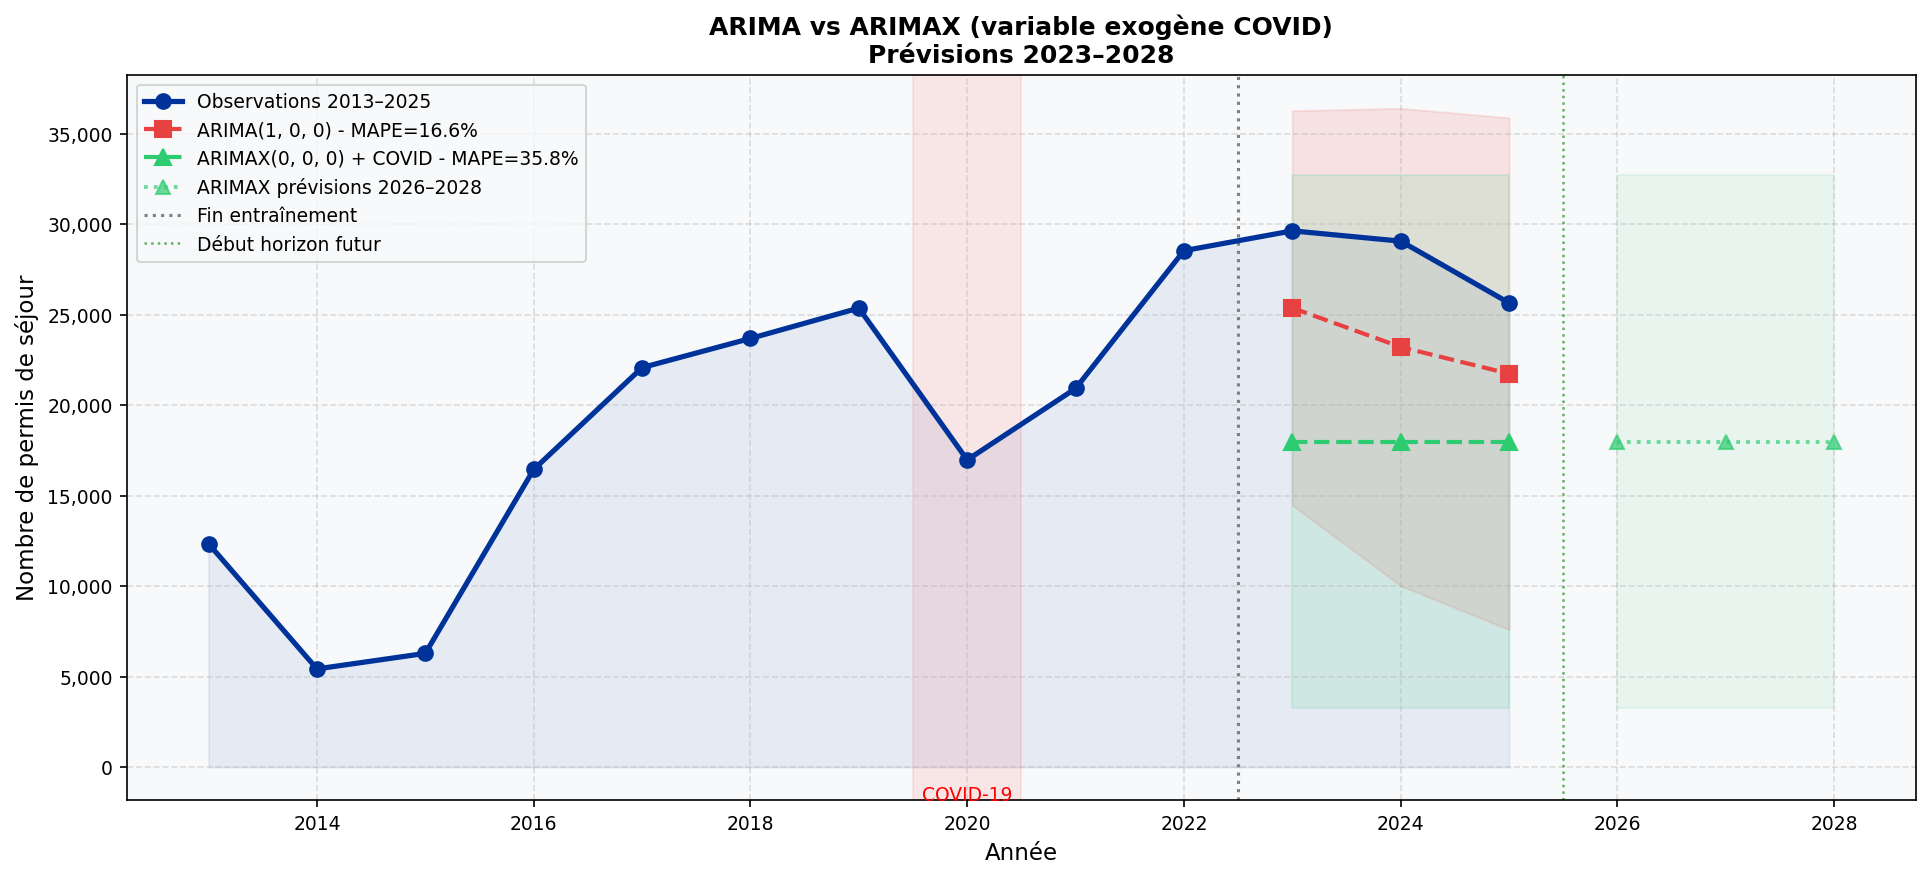

In [ ]:
# Visualisation comparative
fig, ax = plt.subplots(figsize=(13, 6))

# Données historiques
all_years  = series_years
all_values = series.values

ax.fill_between(all_years, all_values, alpha=0.07, color=PALETTE['primary'])
ax.plot(all_years, all_values, 'o-',
        color=PALETTE['primary'], linewidth=2.5, markersize=7,
        label='Observations 2013–2025', zorder=5)

# ARIMA prévisions test
ax.plot(test_years, fc_test.values, 's--',
        color=PALETTE['accent1'], linewidth=2, markersize=8,
        label=f'ARIMA{model_arima.order} - MAPE={mape_arima:.1f}%')
ax.fill_between(test_years,
                confint_test[:, 0], confint_test[:, 1],
                alpha=0.12, color=PALETTE['accent1'])

# ARIMAX prévisions test
ax.plot(test_years, fc_arimax_test.values, '^--',
        color=PALETTE['accent2'], linewidth=2, markersize=8,
        label=f'ARIMAX{model_arimax.order} + COVID - MAPE={mape_arimax:.1f}%')
ax.fill_between(test_years,
                confint_arimax[:, 0], confint_arimax[:, 1],
                alpha=0.12, color=PALETTE['accent2'])

# ARIMAX prévisions futures 2026-2028
future_only = [2026, 2027, 2028]
ax.plot(future_only, fc_arimax_future.iloc[3:].values, '^:',
        color=PALETTE['accent2'], linewidth=1.8, markersize=7,
        alpha=0.7, label='ARIMAX prévisions 2026–2028')
ax.fill_between(future_only,
                confint_arimax_fut[3:, 0],
                confint_arimax_fut[3:, 1],
                alpha=0.08, color=PALETTE['accent2'])

# Délimiteurs
ax.axvline(2022.5, color='gray', linestyle=':', linewidth=1.5,
           label='Fin entraînement')
ax.axvline(2025.5, color='green', linestyle=':', linewidth=1.2,
           alpha=0.6, label='Début horizon futur')
ax.axvspan(2019.5, 2020.5, alpha=0.08, color='red')
ax.annotate('COVID-19', xy=(2020, ax.get_ylim()[0]),
            fontsize=9, color='red', ha='center')

ax.set_xlabel('Année')
ax.set_ylabel('Nombre de permis de séjour')
ax.set_title('ARIMA vs ARIMAX (variable exogène COVID)\n'
             'Prévisions 2023–2028',
             fontsize=12)
ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda x, _: f'{int(x):,}'))
ax.legend(loc='upper left', fontsize=9)

plt.tight_layout()

plt.show()

ARIMAX(0,0,0) avec intercept = juste une moyenne + un coefficient pour COVID.
Le modèle a appris :

intercept ≈ 18 000 (permis hors COVID, p<0.001, significatif)
x1 (coefficient COVID) ≈ -61 (effet quasi nul, p=0.999, non significatif)

Le coefficient COVID a le signe attendu (négatif), mais sa taille est dérisoire (-61 permis) au regard de l'échelle de la série (plusieurs milliers de permis), avec un écart-type énorme (64 300), ce qui le rend totalement non significatif (p=0.999). Avec seulement 10 points d'entraînement, le modèle ne parvient pas à isoler un effet COVID distinct du bruit : la variable exogène n'apporte donc aucune information exploitable. Résultat : le modèle prédit une valeur quasi constante (~18 000 permis) pour toutes les années.

Résumé : L'introduction d'une variable exogène binaire pour le choc COVID-19 (ARIMAX) dégrade les performances (MAPE=35.8% vs 16.6% pour ARIMA), le modèle sélectionné se réduisant à une prévision quasi constante (18 000 permis). Ce résultat s'explique par l'insuffisance de la série (n=10) pour estimer conjointement la dynamique temporelle et l'effet du choc exogène : le coefficient, bien que de signe correct, n'est pas significatif et sa magnitude est négligeable. Cette limite est inhérente aux séries migratoires courtes (Bijak, 2010). Le modèle ARIMA(1,0,0) reste retenu comme référence.

In [ ]:
# 3.4 MODÈLE PROPHET (Taylor & Letham, 2018) : Prophet gère les ruptures structurelles sans variable exogène explicite

# Prophet modélise : y(t) = g(t) + s(t) + h(t) + ε
# g(t) = tendance (linéaire ou logistique)
# s(t) = saisonnalité (Fourier)
# h(t) = effets des événements ponctuels

# Préparation format Prophet : df avec colonnes 'ds' (datetime) et 'y'
df_prophet = pd.DataFrame({
    'ds': pd.to_datetime([f'{y}-01-01' for y in series.index]),
    'y':  series.values.astype(float)
})

print(df_prophet)

           ds        y
0  2013-01-01  12348.0
1  2014-01-01   5430.0
2  2015-01-01   6288.0
3  2016-01-01  16454.0
4  2017-01-01  22086.0
5  2018-01-01  23698.0
6  2019-01-01  25376.0
7  2020-01-01  16983.0
8  2021-01-01  20932.0
9  2022-01-01  28550.0
10 2023-01-01  29646.0
11 2024-01-01  29076.0
12 2025-01-01  25660.0


In [ ]:
df_train_p = df_prophet[df_prophet['ds'].dt.year <= 2022]
df_test_p  = df_prophet[df_prophet['ds'].dt.year >  2022]
# Événement ponctuel : COVID-19
covid_shock = pd.DataFrame({
    'holiday': 'COVID-19 Shock',
    'ds': pd.to_datetime(['2020-01-01']),
    'lower_window': 0, 'upper_window': 1
}) # effet en 2020 avec effet prolongé jusqu'en 2021

prophet_model = Prophet(
    growth='linear', # tendance est supposée linéaire. Prophet ajuste : g(t)=a+bt
    changepoint_prior_scale=0.3,    # (assez flexible) flexibilité de la tendance (hyperparamètre) : contrôle la capacité de Prophet à changer de tendance
    seasonality_prior_scale=10.0, # Contrôle l'amplitude des composantes saisonnières (à supprimer)
    holidays=covid_shock,
    yearly_seasonality=False,       # données annuelles : aucune saison annuelle à modéliser
    weekly_seasonality=False,
    daily_seasonality=False,
    interval_width=0.95
)

prophet_model.fit(df_train_p) # Le modèle apprend :la tendance, les ruptures et l'effet COVID

INFO:prophet:n_changepoints greater than number of observations. Using 7.


In [ ]:
# Prévision test + futur
future_p = prophet_model.make_future_dataframe(periods=6, freq='YS') # prévoir 6 années après la fin du train
forecast_p = prophet_model.predict(future_p)

# Extraction prévisions test
fc_test_p = forecast_p[forecast_p['ds'].dt.year.isin(test_years)]['yhat'].values
mae_p  = mean_absolute_error(test.values, fc_test_p)
rmse_p = np.sqrt(mean_squared_error(test.values, fc_test_p))
mape_p = np.mean(np.abs((test.values - fc_test_p) / test.values)) * 100
# Vérification avant les métriques
print(f"Années test      : {test_years}")
print(f"Prévisions Prophet : {fc_test_p}")
print(f"Valeurs réelles    : {test_renamed.values}")
print("_______________________________________________________________________")
print(f"   Métriques Prophet (ensemble test 2021–2023) :")
print(f"   MAE  = {mae_p:,.0f} permis")
print(f"   RMSE = {rmse_p:,.0f} permis")
print(f"   MAPE = {mape_p:.1f}%")

Années test      : [2023, 2024, 2025]
Prévisions Prophet : [30925.0802012  33176.96148903 35435.01231464]
Valeurs réelles    : [29646. 29076. 25660.]
_______________________________________________________________________
   Métriques Prophet (ensemble test 2021–2023) :
   MAE  = 5,052 permis
   RMSE = 6,165 permis
   MAPE = 18.8%


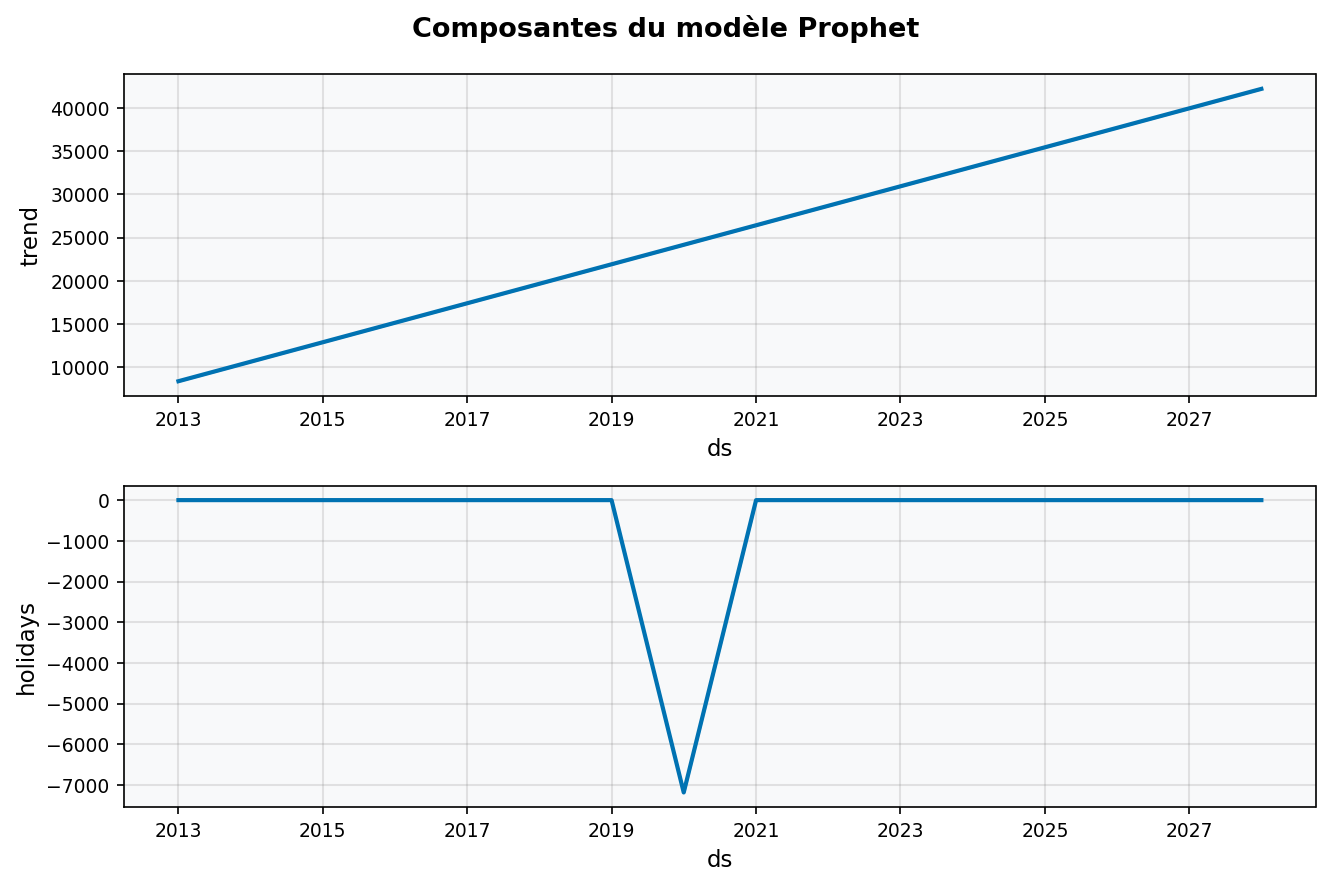

In [ ]:
# Visualisation des changepoints
fig = prophet_model.plot_components(forecast_p)
fig.suptitle('Composantes du modèle Prophet', fontsize=13, fontweight='bold')
plt.tight_layout()
plt.show()

Prophet montre une performance modérée (MAPE=18.8%, à comparer aux 16.6% d'ARIMA). Il capte la tendance générale mais surestime les années 2023 à 2025, avec une surestimation croissante :

2023 est relativement bien prédite (erreur ≈ +1 300 permis)

2024 est surestimée (≈ +4 100 permis)

2025 est fortement surestimée (≈ +9 800 permis)

Le modèle semble donc prolonger la hausse observée avant 2023, alors que les données réelles montrent un ralentissement, voire une légère baisse en 2025.

In [ ]:
# 3.5 MODÈLE XGBOOST : Feature engineering temporel
# Il faut transformer la série en un tableau de variables explicatives (feature engineering)
# Feature engineering : lag-1 (Les variables retardées), lag-2, trend linéaire, indicateur COVID
# Justification : Hyndman & Athanasopoulos (2021) montrent la performance
# des méthodes ML sur séries courtes avec features bien construites

def build_features(s):
    df = pd.DataFrame({'year': s.index, 'y': s.values})
    df['lag1']       = df['y'].shift(1) # Chaque année récupère la valeur de l'année précédente (exemple : pour prédire 2015, on fournit au modèle le nombre de permis de 2014.)
    df['lag2']       = df['y'].shift(2) # Le choix de 2 retards est justifié par l'analyse ACF/PACF, qui suggérait que les dépendances principales se situaient sur les deux premières années précédentes
    df['trend']      = np.arange(len(df)) # indique la progression dans le temps
    df['trend_sq']   = df['trend'] ** 2 # tendance quadratique : permet au modèle de représenter une courbe (croissance qui accélère ou ralentit).
    df['covid_flag'] = (df['year'] == 2020).astype(int)
    df['post_covid'] = (df['year'] > 2020).astype(int) # permet au modèle d'apprendre qu'après 2020, le comportement de la série peut avoir changé.
    return df.dropna() # Les deux premières observations n'ont pas de lag1 ou lag2. Ces lignes sont supprimées.


df_feat = build_features(series)

FEAT_COLS = ['lag1', 'lag2', 'trend', 'trend_sq', 'covid_flag', 'post_covid'] # variables explicatives.
TARGET    = 'y' # les valeurs à prédire.

X = df_feat[FEAT_COLS].values # X contient les variables explicatives.
y_xgb = df_feat[TARGET].values

In [ ]:
# Walk-forward split
train_mask = df_feat['year'] <= 2022
test_mask  = df_feat['year'] >  2022

X_train, y_train = X[train_mask], y_xgb[train_mask]
X_test,  y_test  = X[test_mask],  y_xgb[test_mask]

xgb_model = xgb.XGBRegressor(
    n_estimators=200, # Nombre d'arbres de décision. Avec une série très courte, 200 arbres constituent un choix raisonnable : suffisamment pour apprendre, sans être excessif.
    max_depth=3, # Chaque arbre peut avoir une profondeur maximale de 3 niveaux.
    learning_rate=0.05, # Chaque arbre ne corrige qu'une petite partie des erreurs des arbres précédents. Une valeur faible rend l'apprentissage plus progressif et améliore souvent la généralisation.
    subsample=0.8, # Chaque arbre est construit sur 80 % des observations choisies aléatoirement. Cela réduit la corrélation entre les arbres et limite le surapprentissage.
    colsample_bytree=0.8,  # haque arbre utilise seulement 80 % des variables.
    reg_lambda=2.0,     # L2 régularisation (éviter overfitting sur série courte)
    random_state=42, # Fixe la graine aléatoire.
    verbosity=0
)

xgb_model.fit(X_train, y_train,
              eval_set=[(X_test, y_test)], # eval_set sert uniquement à suivre les performances sur le jeu de test pendant l'entraînement
              verbose=False)

XGBRegressor(base_score=None, booster=None, callbacks=None,
             colsample_bylevel=None, colsample_bynode=None,
             colsample_bytree=0.8, device=None, early_stopping_rounds=None,
             enable_categorical=True, eval_metric=None, feature_types=None,
             feature_weights=None, gamma=None, grow_policy=None,
             importance_type=None, interaction_constraints=None,
             learning_rate=0.05, max_bin=None, max_cat_threshold=None,
             max_cat_to_onehot=None, max_delta_step=None, max_depth=3,
             max_leaves=None, min_child_weight=None, missing=nan,
             monotone_constraints=None, multi_strategy=None, n_estimators=200,
             n_jobs=None, num_parallel_tree=None, ...)

In [ ]:
y_pred_xgb = xgb_model.predict(X_test)

mae_xgb  = mean_absolute_error(y_test, y_pred_xgb)
rmse_xgb = np.sqrt(mean_squared_error(y_test, y_pred_xgb))
mape_xgb = np.mean(np.abs((y_test - y_pred_xgb) / y_test)) * 100

# Feature importance
fi = pd.DataFrame({'feature': FEAT_COLS,
                   'importance': xgb_model.feature_importances_
                  }).sort_values('importance', ascending=False) # XGBoost attribue un score d'importance à chaque variable.

print(f"Années test      : {test_years}")
print(f"Prévisions XGBoost : {y_pred_xgb}")
print(f"Valeurs réelles    : {test_renamed.values}")
print("_______________________________________________________________________")
print(f" Métriques XGBoost (test 2023–2025) :")
print(f"   MAE  = {mae_xgb:,.0f} | RMSE = {rmse_xgb:,.0f} | MAPE = {mape_xgb:.1f}%")
print(f"\n   Feature importance :")
print(fi.to_string(index=False))

Années test      : [2023, 2024, 2025]
Prévisions XGBoost : [25390.117 21745.725 21745.725]
Valeurs réelles    : [29646. 29076. 25660.]
_______________________________________________________________________
 Métriques XGBoost (test 2023–2025) :
   MAE  = 5,167 | RMSE = 5,390 | MAPE = 18.3%

   Feature importance :
   feature  importance
     trend    0.255765
      lag1    0.209864
post_covid    0.200276
covid_flag    0.147026
  trend_sq    0.100615
      lag2    0.086454


L'analyse de la feature importance montre :

trend (25.6%) = la tendance temporelle est le signal le plus fort

lag1 (21.0%) = l'année précédente explique beaucoup, confirme ar.L1=0.68 d'ARIMA

post_covid (20.0%) = l'indicateur post-COVID capture une rupture de régime
après 2020

covid_flag (14.7%) = le choc COVID lui-même contribue modérément

trend_sq (10.1%) et lag2 (8.6%) jouent un rôle secondaire

In [ ]:
# 3.6 COMPARAISON DES MODÈLES + PRÉVISIONS 2026–2028

# Tableau de comparaison
metrics_df = pd.DataFrame({
    'Modèle': ['ARIMA(auto)', 'Prophet', 'XGBoost'],
    'MAE':    [mae_arima, mae_p, mae_xgb],
    'RMSE':   [rmse_arima, rmse_p, rmse_xgb],
    'MAPE(%)': [mape_arima, mape_p, mape_xgb],
})
metrics_df['Rang (MAPE)'] = metrics_df['MAPE(%)'].rank().astype(int)

print("\n Tableau comparatif des modèles :")
print(metrics_df.to_string(index=False))
best_model = metrics_df.loc[metrics_df['MAPE(%)'].idxmin(), 'Modèle']
print(f"\n Meilleur modèle selon MAPE : {best_model}")


 Tableau comparatif des modèles :
     Modèle         MAE        RMSE   MAPE(%)  Rang (MAPE)
ARIMA(auto) 4674.684659 4750.319968 16.580623            1
    Prophet 5051.684668 6164.543699 18.837718            3
    XGBoost 5166.811198 5390.331704 18.273600            2

 Meilleur modèle selon MAPE : ARIMA(auto)


Années Prophet disponibles : [2013, 2014, 2015, 2016, 2017, 2018, 2019, 2020, 2021, 2022, 2023, 2024, 2025, 2026, 2027, 2028]
Années futures Prophet     : [2026, 2027, 2028]


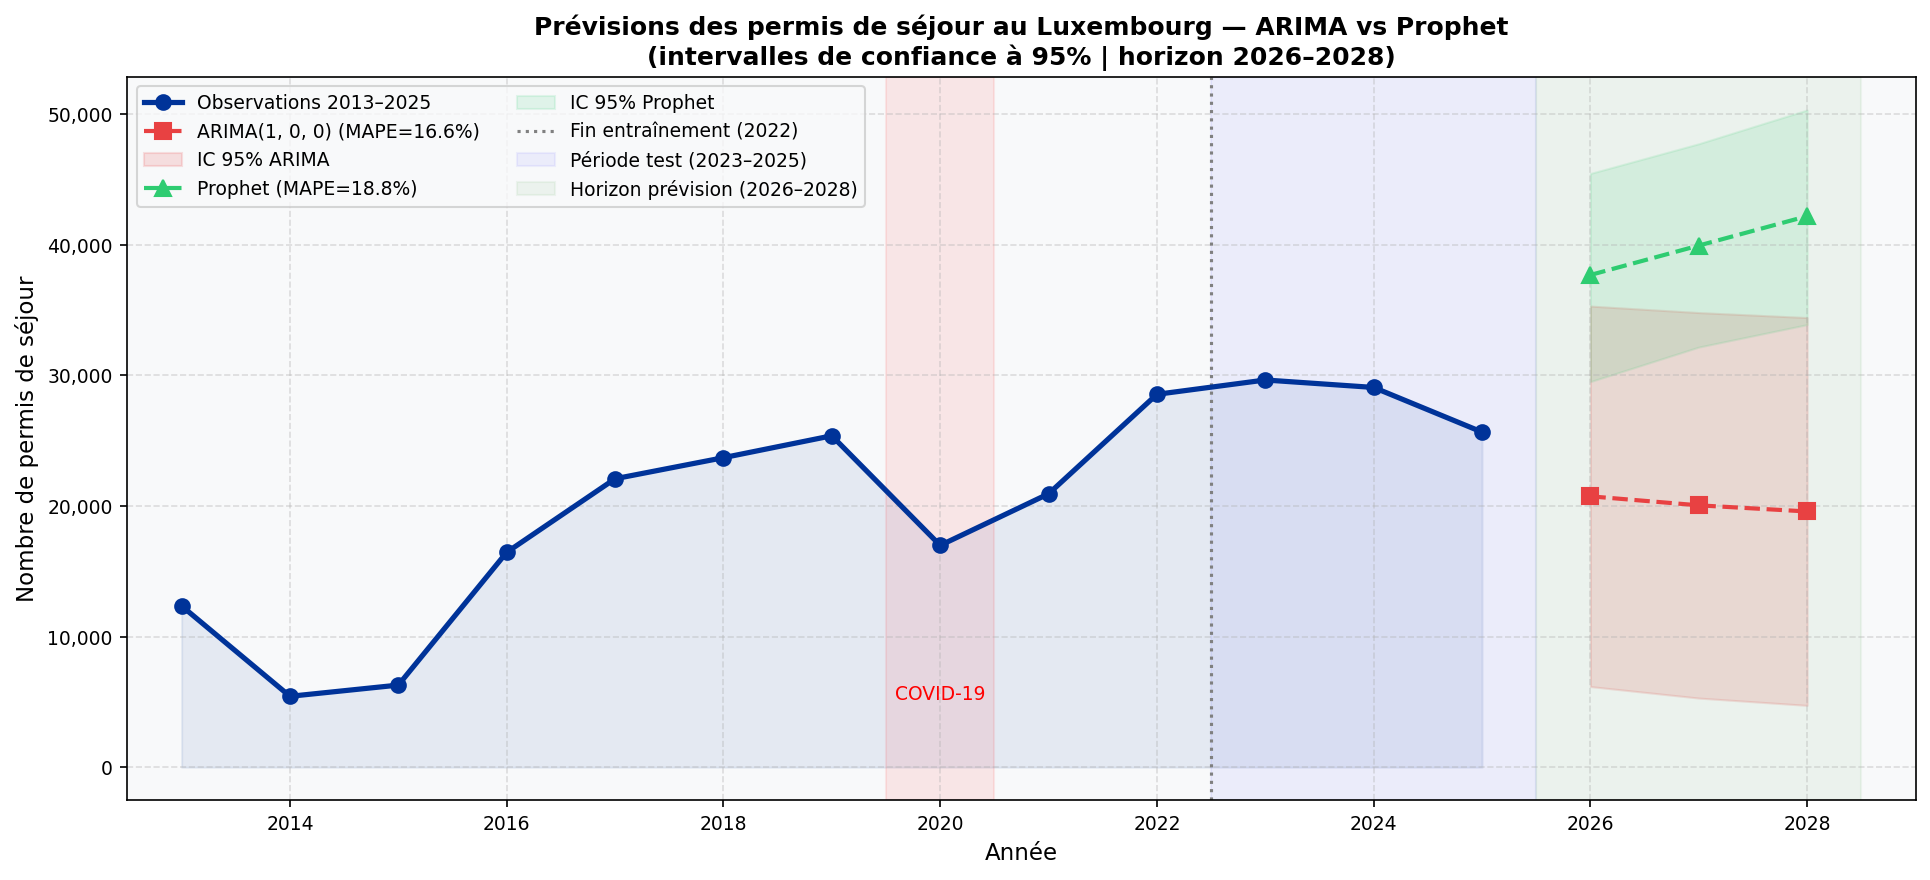


 Prévisions 2026–2028 :
 Année ARIMA (central) ARIMA (IC bas) ARIMA (IC haut) Prophet (central) Prophet (IC bas) Prophet (IC haut)
  2026          20,739          6,174          35,304            37,686           29,521            45,457
  2027          20,050          5,293          34,807            39,938           32,165            47,733
  2028          19,579          4,734          34,425            42,190           33,885            50,320


In [ ]:

# VISUALISATION FINALE - Comparaison ARIMA vs Prophet
# Prévisions 2026–2028 avec intervalles de confiance


fig, ax = plt.subplots(figsize=(13, 6))

#  Données historiques
# series_years = vraies années [2013..2025]
# series.values = valeurs correspondantes
ax.fill_between(series_years, series.values,
                alpha=0.08, color=PALETTE['primary'])
ax.plot(series_years, series.values, 'o-',
        color=PALETTE['primary'], linewidth=2.5, markersize=7,
        label='Observations 2013–2025', zorder=5)

# ARIMA - prévisions 2026–2028
# Le modèle est entraîné sur 2013–2022, on prédit 3 périodes après 2025
# On re-prédit depuis la fin du train jusqu'à 2028 : 6 périodes
fc_arima_all, ci_arima_all = model_arima.predict(
    n_periods=6,   # 2023+2024+2025+2026+2027+2028
    return_conf_int=True,
    alpha=0.05
)

future_years_arima = np.array([2023, 2024, 2025, 2026, 2027, 2028])
fc_arima_all = pd.Series(fc_arima_all.values, index=future_years_arima)

# On affiche uniquement 2026–2028 pour la partie future
future_only = [2026, 2027, 2028]
fc_arima_fut_vals = fc_arima_all.loc[future_only].values
ci_arima_fut_vals = ci_arima_all[3:]   # 3 dernières = 2026–2028

ax.plot(future_only, fc_arima_fut_vals, 's--',
        color=PALETTE['accent1'], linewidth=2, markersize=8,
        label=f'ARIMA{model_arima.order} (MAPE={mape_arima:.1f}%)')
ax.fill_between(future_only,
                ci_arima_fut_vals[:, 0],
                ci_arima_fut_vals[:, 1],
                alpha=0.15, color=PALETTE['accent1'],
                label='IC 95% ARIMA')

# Prophet — prévisions 2026–2028
# forecast_p contient toutes les années y compris 2026–2028
# make_future_dataframe(periods=6) depuis fin 2022 = jusqu'à 2028
fc_p_fut = forecast_p[forecast_p['ds'].dt.year.isin(future_only)]

# Vérification que Prophet a bien prédit ces années
print(f"Années Prophet disponibles : {forecast_p['ds'].dt.year.tolist()}")
print(f"Années futures Prophet     : {fc_p_fut['ds'].dt.year.tolist()}")

ax.plot(fc_p_fut['ds'].dt.year.values,
        fc_p_fut['yhat'].values, '^--',
        color=PALETTE['accent2'], linewidth=2, markersize=8,
        label=f'Prophet (MAPE={mape_p:.1f}%)')
ax.fill_between(fc_p_fut['ds'].dt.year.values,
                fc_p_fut['yhat_lower'].values,
                fc_p_fut['yhat_upper'].values,
                alpha=0.12, color=PALETTE['accent2'],
                label='IC 95% Prophet')

# Délimiteurs temporels
ax.axvline(2022.5, color='gray', linestyle=':', linewidth=1.5,
           label='Fin entraînement (2022)')     # fin du train
ax.axvspan(2022.5, 2025.5,
           alpha=0.05, color='blue',
           label='Période test (2023–2025)')    # période évaluée
ax.axvspan(2025.5, 2028.5,
           alpha=0.05, color='green',
           label='Horizon prévision (2026–2028)')

# Annotation COVID
ax.axvspan(2019.5, 2020.5, alpha=0.08, color='red')
ax.annotate('COVID-19', xy=(2020, series.min() * 0.95),
            fontsize=9, color='red', ha='center')

# Style
ax.set_xlabel('Année')
ax.set_ylabel('Nombre de permis de séjour')
ax.set_title(
    'Prévisions des permis de séjour au Luxembourg — ARIMA vs Prophet\n'
    '(intervalles de confiance à 95% | horizon 2026–2028)',
    fontsize=12
)
ax.yaxis.set_major_formatter(
    plt.FuncFormatter(lambda x, _: f'{int(x):,}')
)
ax.legend(loc='upper left', fontsize=9, ncol=2)
ax.set_xlim(2012.5, 2029)

plt.tight_layout()
plt.savefig('fig8_previsions_2026_2028.png', dpi=200, bbox_inches='tight')
plt.show()

#  Tableau des prévisions
print("\n Prévisions 2026–2028 :")
prev_df = pd.DataFrame({
    'Année':            future_only,
    'ARIMA (central)':  [f'{int(v):,}' for v in fc_arima_fut_vals],
    'ARIMA (IC bas)':   [f'{int(v):,}' for v in ci_arima_fut_vals[:, 0]],
    'ARIMA (IC haut)':  [f'{int(v):,}' for v in ci_arima_fut_vals[:, 1]],
    'Prophet (central)':[f'{int(v):,}' for v in fc_p_fut['yhat'].values],
    'Prophet (IC bas)': [f'{int(v):,}' for v in fc_p_fut['yhat_lower'].values],
    'Prophet (IC haut)':[f'{int(v):,}' for v in fc_p_fut['yhat_upper'].values],
})
print(prev_df.to_string(index=False))

## 4. Clustering des profils migratoires

Hypothèse H2 : Les nationalités présentes au Luxembourg forment des groupes structurellement distincts en termes de profil de demande (motif, volume, évolution temporelle).

Méthode : K-Means + CAH, avec sélection du k optimal par Elbow + Silhouette + Gap Statistic.

In [ ]:
# 4.1 CONSTRUCTION DE LA MATRICE DE FEATURES

# Features par nationalité :
# - volume_total : total de permis sur 2013–2025
# - cagr : taux de croissance annuel composé
# - share_work, share_fami, share_educ, share_othp : parts par motif
# - covid_resilience : ratio volume 2021/volume 2019
# - concentration : coefficient de variation inter-annuel

In [ ]:
# Phase de feature engineering : transformer les données brutes (une ligne par année, nationalité et motif) en une ligne par nationalité, avec plusieurs indicateurs numériques décrivant son profil migratoire.
# Avant : plusieurs centaines de lignes pour une même nationalité.
# Après : une seule ligne résumant cette nationalité.

def build_clustering_features(df_lu):
    feats = [] # À chaque nationalité on ajoutera un dictionnaire contenant ses indicateurs.
    # Garder uniquement les durées totales
    if 'duration' in df_lu.columns:
         df_lu = df_lu[df_lu['duration'] == 'TOTAL']

    for citizen, grp in df_lu.groupby('citizen'): # regroupe toutes les observations ayant la même nationalité.
        total_by_year = grp.groupby('year')['permits'].sum()  # On additionne tous les motifs pour obtenir le total annuel
        # Exclure nationalités trop rares (< 10 permis/an en moyenne)
        if total_by_year.mean() < 10 :  # la moyenne annuelle des permis. Avec très peu d'observations, les indicateurs deviennent instables. Une variation de 2 ou 3 permis peut produire des taux de croissance extrêmes, qui perturberaient le clustering.
            continue

        total = total_by_year.sum() # On additionne toutes les années.

        # CAGR : taux de croissance annuel moyen entre 2013 et 2025.
        #first = total_by_year.get(2013, np.nan)
        #last =  total_by_year.get(2025, np.nan)
        first = total_by_year[total_by_year > 0].iloc[0] # premier effectif non nul, dernier effectif disponible
        last  = total_by_year.iloc[-1]
        cagr_c = (last / first) ** (1/10) - 1 if (first and first > 0) else 0

        # Parts par motif
        total_reason = grp.groupby('reason_cat')['permits'].sum() # On calcule le total de permis pour chaque motif
        share = {r: total_reason.get(r, 0) / total if total > 0 else 0 # On transforme ces volumes en proportions (variables décrivent le profil migratoire de chaque nationalité)
                 for r in ['WORK', 'FAMI', 'EDUC', 'OTHP']}

        # Résilience COVID : < 1 : baisse après la pandémie
        v2019 = total_by_year.get(2019, np.nan)
        v2021 = total_by_year.get(2021, np.nan)
        covid_res = v2021 / v2019 if (v2019 and v2019 > 0) else 1.0 # indicateur comparant le niveau de permis après la pandémie à celui d'avant la pandémie.

        # Concentration temporelle (coeff. de variation) : valeur faible → évolution régulière
        cv = total_by_year.std() / total_by_year.mean() if total_by_year.mean() > 0 else 0 # mesure la stabilité des permis au fil du temps, Comme il est normalisé par la moyenne, il permet de comparer des nationalités ayant des volumes très différents.

        # Accélération récente (2019–2025 vs 2013–2017)
        v_early = total_by_year[total_by_year.index <= 2017].mean()
        v_late  = total_by_year[total_by_year.index >= 2019].mean()
        accel   = v_late / (v_early + 1) if v_early > 0 else 1.0

        # Feature binaire : pays en crise humanitaire documentée
        # Source : UNHCR / Fragile States Index
        CRISIS_COUNTRIES = [
            'SY', 'AF', 'IQ', 'YE', 'ER', 'SD', 'SS', 'SO',
            'CF', 'CD', 'ML', 'NE', 'TD', 'ET', 'MM'
            ]

        # Création d'une ligne par nationalité
        feats.append({
            'citizen': citizen,
            'volume_total': total,
            'log_volume':   np.log1p(total),  # log-transform pour réduire l'asymétrie : Certaines nationalités ont des volumes très élevés, d'autres très faibles : Sans transformation, les très grands volumes dominent les calculs de distance utilisés par de nombreux algorithmes de clustering. La transformation logarithmique réduit cet effet en compressant les grandes valeurs tout en conservant leur ordre.
            'cagr':         cagr_c,
            'share_work':   share['WORK'],
            'share_fami':   share['FAMI'],
            'share_educ':   share['EDUC'],
            'share_othp':   share['OTHP'],
            'covid_resilience': covid_res,
            'cv_temporal':  cv,
            'acceleration': accel,
            'is_crisis': 1 if citizen in CRISIS_COUNTRIES else 0,
        })

    return pd.DataFrame(feats).set_index('citizen')

df_feat_clust = build_clustering_features(df_lu)

print(f" Matrice de features : {df_feat_clust.shape}") # Affiche les dimensions de la matrice : exemple : 165 nationalités ; 10 variables utilisées pour le clustering.
print(f" Nationalités : {df_feat_clust.shape[0]}")
print(f" Features     : {df_feat_clust.shape[1]}")
print("\n Statistiques descriptives :")
print(df_feat_clust.describe().round(3)) # Pour vérifier si les indicateurs sont cohérents avant de lancer l'algorithme de clustering.

 Matrice de features : (92, 11)
 Nationalités : 92
 Features     : 11

 Statistiques descriptives :
       volume_total  log_volume    cagr  share_work  share_fami  share_educ  \
count        92.000      92.000  92.000      92.000      92.000      92.000   
mean       2827.663       7.035   0.108       0.186       0.674       0.066   
std        4638.412       1.354   0.145       0.090       0.088       0.062   
min         132.000       4.890  -0.121       0.001       0.511       0.000   
25%         428.000       6.061   0.008       0.140       0.618       0.021   
50%         936.000       6.842   0.093       0.188       0.663       0.045   
75%        3486.750       8.157   0.165       0.248       0.712       0.093   
max       27922.000      10.237   0.681       0.422       0.988       0.304   

       share_othp  covid_resilience  cv_temporal  acceleration  is_crisis  
count      92.000            92.000       92.000        92.000     92.000  
mean        0.075             0.943 

- 117 nationalités ayant en moyenne au moins 10 permis par an.  

Il existe de très grosses nationalité et beaucoup de nationalités plus modestes. En ajoutant log_volume la variable ne ne dominerait pas les autres dans le clustering.

- En moyenne :

82 % des premiers titres concernent le regroupement familial (FAMI)

10 % le travail (WORK)

4 % l'éducation (EDUC)

4 % les autres motifs (OTHP)

- min = -1.000 peut etre pour une nationalité :

Année = nbr permis

Année = 0 permis

- 2021/2019 = 1.03 -> Les flux de 2021 sont donc légèrement supérieurs à ceux de 2019 ; max = 7 -> une nationalité a été multipliée par 7 entre 2019 et 2021.

- Coefficient de variation -> moyenne = 0.78. Plus le coefficient est élevé, plus les permis fluctuent au cours du temps.

- L'accélération -> max = 88.214 : une nationalité a une moyenne 2019–2025 environ 88 fois supérieure à sa moyenne 2013–2017.

Vérification :

In [ ]:
df_feat_clust[df_feat_clust['cagr'] == -1] # Nationalités concernées

,volume_total,log_volume,cagr,share_work,share_fami,share_educ,share_othp,covid_resilience,cv_temporal,acceleration,is_crisis
citizen,,,,,,,,,,,


In [ ]:
df_lu[df_lu["citizen"]=="HR"].groupby("year")["permits"].sum()

,permits
year,
2013,60.0
2014,0.0
2015,0.0
2016,0.0
2017,0.0
2018,0.0
2019,0.0
2020,0.0
2021,0.0


In [ ]:
df_feat_clust.sort_values('acceleration', ascending=False).head(10)

,volume_total,log_volume,cagr,share_work,share_fami,share_educ,share_othp,covid_resilience,cv_temporal,acceleration,is_crisis
citizen,,,,,,,,,,,
YE,252.0,5.533389,0.311019,0.047619,0.603175,0.015873,0.333333,0.857143,1.076668,24.693878,1
SD,683.0,6.527958,0.414214,0.032211,0.534407,0.011713,0.421669,0.638889,1.019994,14.714286,1
ER,11062.0,9.311361,0.594989,0.000723,0.510758,0.000542,0.487977,1.586375,0.793972,11.873874,1
LB,2697.0,7.900266,0.205225,0.321839,0.640341,0.029663,0.008157,2.095890,1.117546,7.981651,0
MG,1026.0,6.934397,0.350626,0.062378,0.576998,0.304094,0.056530,1.583333,0.933367,7.951807,0
ZW,198.0,5.293305,0.231144,0.222222,0.636364,0.101010,0.040404,1.153846,0.871509,6.616541,0
PK,3443.0,8.144389,0.205845,0.245135,0.675283,0.069126,0.010456,0.752000,0.897195,6.561668,0
UY,253.0,5.537334,0.084472,0.276680,0.699605,0.007905,0.015810,0.714286,1.908879,6.208791,0
LK,443.0,6.095825,0.071773,0.293454,0.638826,0.045147,0.022573,0.266667,0.964124,5.302198,0


- variables présentent énormément d'outliers :

accélération jusqu'à 24

covid_resilience jusqu'à 4.5

log_volume très asymétrique

- Donc RobustScaler est plus adapté que StandardScaler

In [ ]:
# 4.2 RÉDUCTION DIMENSIONNELLE : PCA + t-SNE : avant de faire du clustering des nationalités. L'objectif est de transformer les variables descriptives en un espace plus simple, tout en conservant le maximum d'information.

# Normalisation RobustScaler (résistant aux outliers : Branco et al., 2016)
# Sélection des variable
feat_cols = [c for c in df_feat_clust.columns if c != 'volume_total' and c != 'share_othp' ] # Enlever volume_total qui mesure seulement la taille absolue d'une nationalité. Pour éviter que le clustering sépare "grands volumes" et "petits volumes".
# Normalisation RobustScaler pour avoir les mêmes échelles.
scaler = RobustScaler() # moins sensible aux valeurs extrêmes contrairement au StandardScaler
X_scaled = scaler.fit_transform(df_feat_clust[feat_cols])

# Retirer les nationalités avec log_volume > seuil (outliers volume)
# seuil_volume = df_feat_clust['log_volume'].quantile(0.95)
# df_feat_clust = df_feat_clust[df_feat_clust['log_volume'] <= seuil_volume]
# X_scaled = scaler.fit_transform(df_feat_clust[feat_cols])

# PCA
pca = PCA(n_components=min(len(feat_cols), len(df_feat_clust)-1))
X_pca = pca.fit_transform(X_scaled)
# variance expliquée : Chaque composante explique une partie de l'information.
cum_var = np.cumsum(pca.explained_variance_ratio_)
n_comp_90 = np.argmax(cum_var >= 0.90) + 1

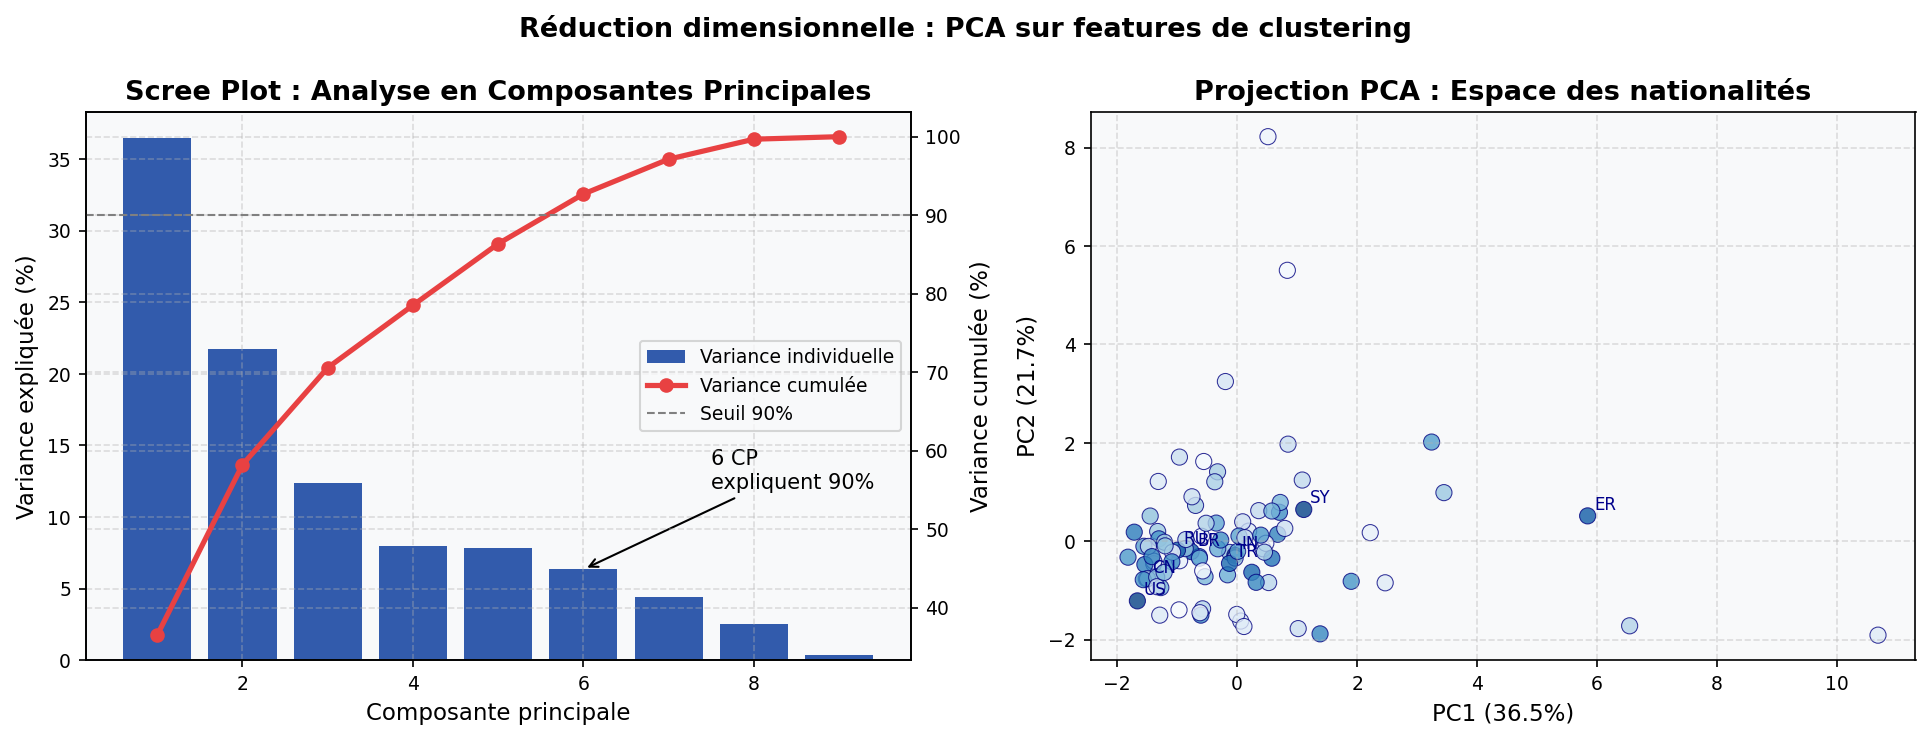


   PC1 + PC2 expliquent 58.2% de la variance
   6 composantes suffisent pour 90% de la variance


In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5))

# Scree plot
axes[0].bar(range(1, len(pca.explained_variance_ratio_)+1), # trace les barres de variance individuelle
            pca.explained_variance_ratio_ * 100,
            color=PALETTE['primary'], alpha=0.8, label='Variance individuelle')
ax0b = axes[0].twinx()
ax0b.plot(range(1, len(cum_var)+1), cum_var * 100, # trace la variance cumulée :
          color=PALETTE['accent1'], linewidth=2.5, marker='o', markersize=6,
          label='Variance cumulée')
ax0b.axhline(90, color='gray', linestyle='--', linewidth=1, label='Seuil 90%')
ax0b.set_ylabel('Variance cumulée (%)')
axes[0].set_xlabel('Composante principale')
axes[0].set_ylabel('Variance expliquée (%)')
axes[0].set_title('Scree Plot : Analyse en Composantes Principales')
axes[0].annotate(f'{n_comp_90} CP\nexpliquent 90%',
                 xy=(n_comp_90, pca.explained_variance_ratio_[n_comp_90-1]*100),
                 xytext=(n_comp_90+1.5, 12),
                 arrowprops=dict(arrowstyle='->', color='black'),
                 fontsize=10)
lines1, labels1 = axes[0].get_legend_handles_labels()
lines2, labels2 = ax0b.get_legend_handles_labels()
axes[0].legend(lines1 + lines2, labels1 + labels2, loc='center right', fontsize=9)

# Biplot PCA
axes[1].scatter(X_pca[:, 0], X_pca[:, 1], # affiche chaque nationalité dans un plan : Chaque point = une nationalité. Si deux points sont proches : leurs profils migratoires sont similaires.
                c=df_feat_clust['log_volume'], cmap='Blues', # La couleur représente la taille.
                s=60, alpha=0.8, edgecolors='navy', linewidths=0.5)
# Annotations top nationalités
top_nations = df_feat_clust['volume_total'].nlargest(8).index # affiche seulement les 8 plus grandes nationalités
for nat in top_nations:
    idx = df_feat_clust.index.get_loc(nat)
    axes[1].annotate(nat, (X_pca[idx, 0], X_pca[idx, 1]),
                     fontsize=8, color='darkblue',
                     xytext=(3, 3), textcoords='offset points')
axes[1].set_xlabel(f'PC1 ({pca.explained_variance_ratio_[0]*100:.1f}%)')
axes[1].set_ylabel(f'PC2 ({pca.explained_variance_ratio_[1]*100:.1f}%)')
axes[1].set_title('Projection PCA : Espace des nationalités')

plt.suptitle('Réduction dimensionnelle : PCA sur features de clustering',
             fontsize=13, fontweight='bold')
plt.tight_layout()

plt.show()
print(f"\n   PC1 + PC2 expliquent {(pca.explained_variance_ratio_[:2].sum()*100):.1f}% de la variance")
print(f"   {n_comp_90} composantes suffisent pour 90% de la variance")

In [ ]:
# 4.3 SÉLECTION DU k OPTIMAL

# Méthode 1 : Elbow (inertie intra-cluster)
# Méthode 2 : Silhouette score
# Méthode 3 : Davies-Bouldin index (minimiser)

K_RANGE = range(2, min(11, len(df_feat_clust)-1)) # Définition des valeurs de k testées
# listes de résultats
inertias = [] # minimiser
sil_scores = [] # maximiser
db_scores  = [] # minimiser

# # Relancer la sélection k optimal sur données sans outliers
for k in K_RANGE :
    km = KMeans(n_clusters=k, init='k-means++', # méthode de choix des centres initiaux.
                n_init=20, # il lance 20 fois l'algorithme puis garde le meilleur.
                max_iter=500, # À chaque itération : chaque nationalité est affectée au centre le plus proche ; les centres sont recalculés ; on recommence.
                random_state=42)
    # Entraînement et récupération des clusters
    labels = km.fit_predict(X_scaled) # Le modèle apprend les groupes.
    inertias.append(km.inertia_) # Métrique 1 : Inertie (Elbow) : L'inertie mesure la distance entre les points et leur centre de cluster.(Un bon cluster doit avoir des points proches de son centre.)
    sil_scores.append(silhouette_score(X_scaled, labels)) # Métrique 2 : Silhouette Score. Elle mesure : cohésion interne du cluster ; séparation avec les autres clusters.
    db_scores.append(davies_bouldin_score(X_scaled, labels)) #  Métrique 3 : Davies-Bouldin. Il mesure : dispersion interne des groupes ;

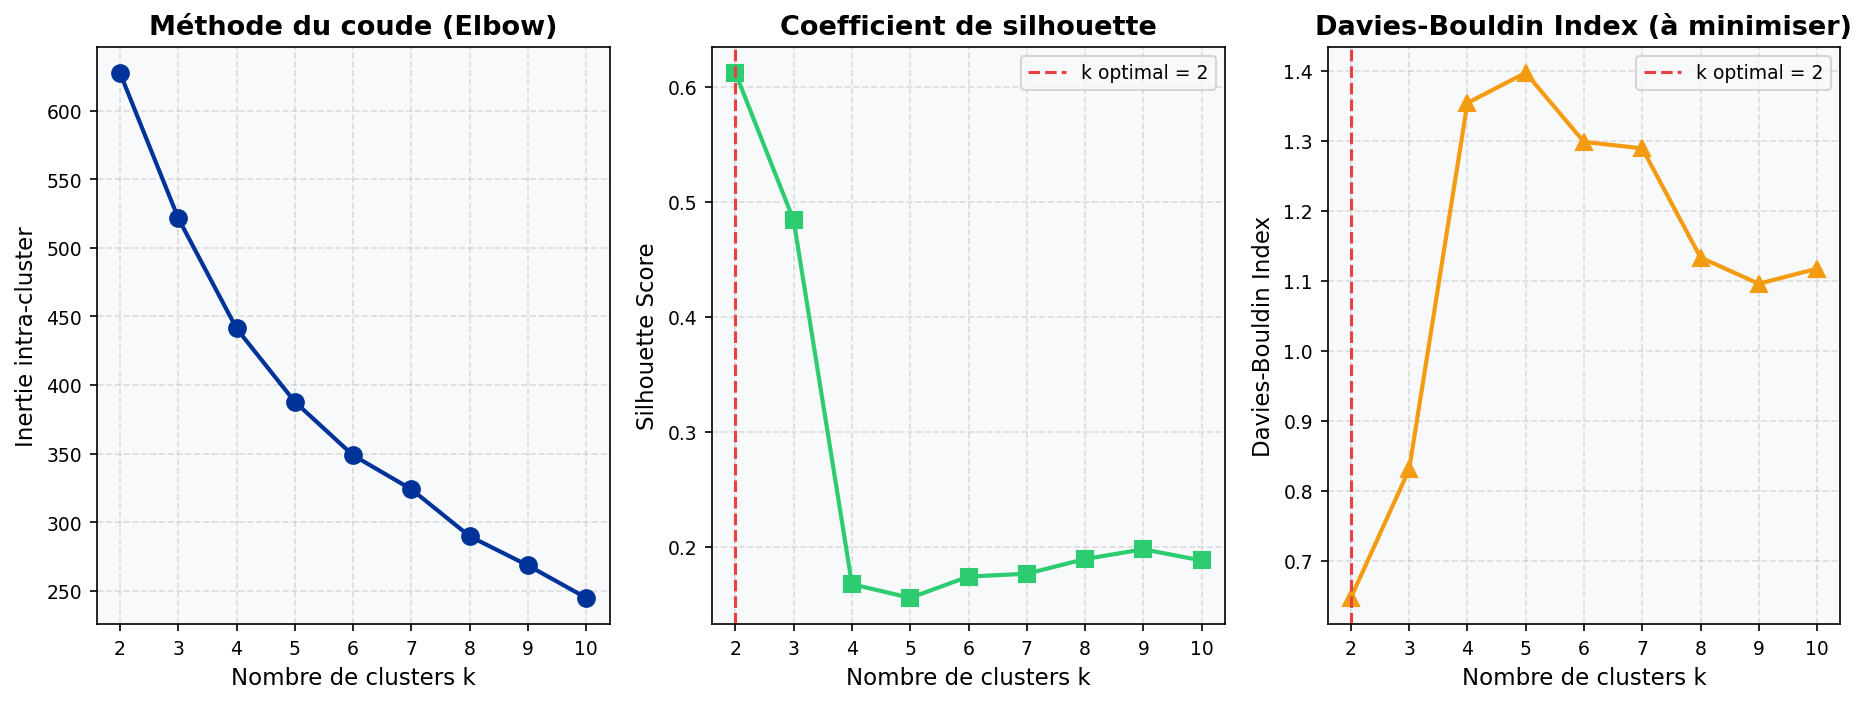

In [ ]:
fig, axes = plt.subplots(1, 3, figsize=(15, 5))

# Elbow
axes[0].plot(list(K_RANGE), inertias, 'o-', color=PALETTE['primary'],
             linewidth=2, markersize=8)
axes[0].set_xlabel('Nombre de clusters k')
axes[0].set_ylabel('Inertie intra-cluster')
axes[0].set_title('Méthode du coude (Elbow)') # On cherche le changement brutal de pente.

# Silhouette
best_k_sil = list(K_RANGE)[np.argmax(sil_scores)] # Choix automatique du meilleur k : argmax cherche la position du maximum.
axes[1].plot(list(K_RANGE), sil_scores, 's-', color=PALETTE['accent2'],
             linewidth=2, markersize=8)
axes[1].axvline(best_k_sil, color=PALETTE['accent1'], linestyle='--',
                linewidth=1.5, label=f'k optimal = {best_k_sil}')
axes[1].set_xlabel('Nombre de clusters k')
axes[1].set_ylabel('Silhouette Score')
axes[1].set_title('Coefficient de silhouette')
axes[1].legend()

# Davies-Bouldin (minimiser)
best_k_db = list(K_RANGE)[np.argmin(db_scores)]
axes[2].plot(list(K_RANGE), db_scores, '^-', color=PALETTE['accent3'],
             linewidth=2, markersize=8)
axes[2].axvline(best_k_db, color=PALETTE['accent1'], linestyle='--',
                linewidth=1.5, label=f'k optimal = {best_k_db}')
axes[2].set_xlabel('Nombre de clusters k')
axes[2].set_ylabel('Davies-Bouldin Index')
axes[2].set_title('Davies-Bouldin Index (à minimiser)')
axes[2].legend()

Davies-Bouldin : minimum à k=2.

Elbow : le gain devient plus faible après 2-3 clusters.

Donc choisir k=2

In [ ]:
plt.suptitle('Sélection du nombre optimal de clusters k',
             fontsize=13, fontweight='bold')
plt.tight_layout()
plt.show()

print(f"\n   k optimal (Silhouette) : {best_k_sil}  [score = {max(sil_scores):.3f}]")
print(f"   k optimal (Davies-Bouldin) : {best_k_db}  [score = {min(db_scores):.3f}]")

#K_OPTIMAL = best_k_sil  # Choix final
K_OPTIMAL = 2
print(f"\n k retenu : {K_OPTIMAL}")

<Figure size 960x720 with 0 Axes>


   k optimal (Silhouette) : 2  [score = 0.612]
   k optimal (Davies-Bouldin) : 2  [score = 0.647]

 k retenu : 2


Remarque : Forcer k=4 ou k=5 pour avoir des clusters interprétables comme dans Napierala & Mikulec (2017) ?

In [ ]:
# 4.4 K-MEANS FINAL + SILHOUETTE PLOT DÉTAILLÉ

# Entraîner le modèle définitif, évaluer sa qualité et le visualiser

# Entraînement du K-Means final
# Nombre de groupes obtenu dans la partie précédente grâce aux critères : Elbow, Silhouette, Davies-Bouldin
km_final = KMeans(n_clusters=K_OPTIMAL, init='k-means++', # Les centroïdes initiaux sont choisis intelligemment
                  n_init=50, max_iter=1000, random_state=42) # Pour rendre les résultats reproductibles. À chaque exécution tu retrouveras les mêmes clusters.
                  # lancer l'algorithme 50 fois
                  # K-Means s'arrête lorsque : les centroïdes ne bougent presque plus ou lorsqu'il atteint 1000 itérations

cluster_labels = km_final.fit_predict(X_scaled) # apprend les centroïdes et  attribue chaque nationalité à un cluster
df_feat_clust['cluster'] = cluster_labels

sil_vals = silhouette_samples(X_scaled, cluster_labels) # Chaque nationalité reçoit son propre score. Il mesure si un point est bien placé dans son cluster.
df_feat_clust['silhouette'] = sil_vals


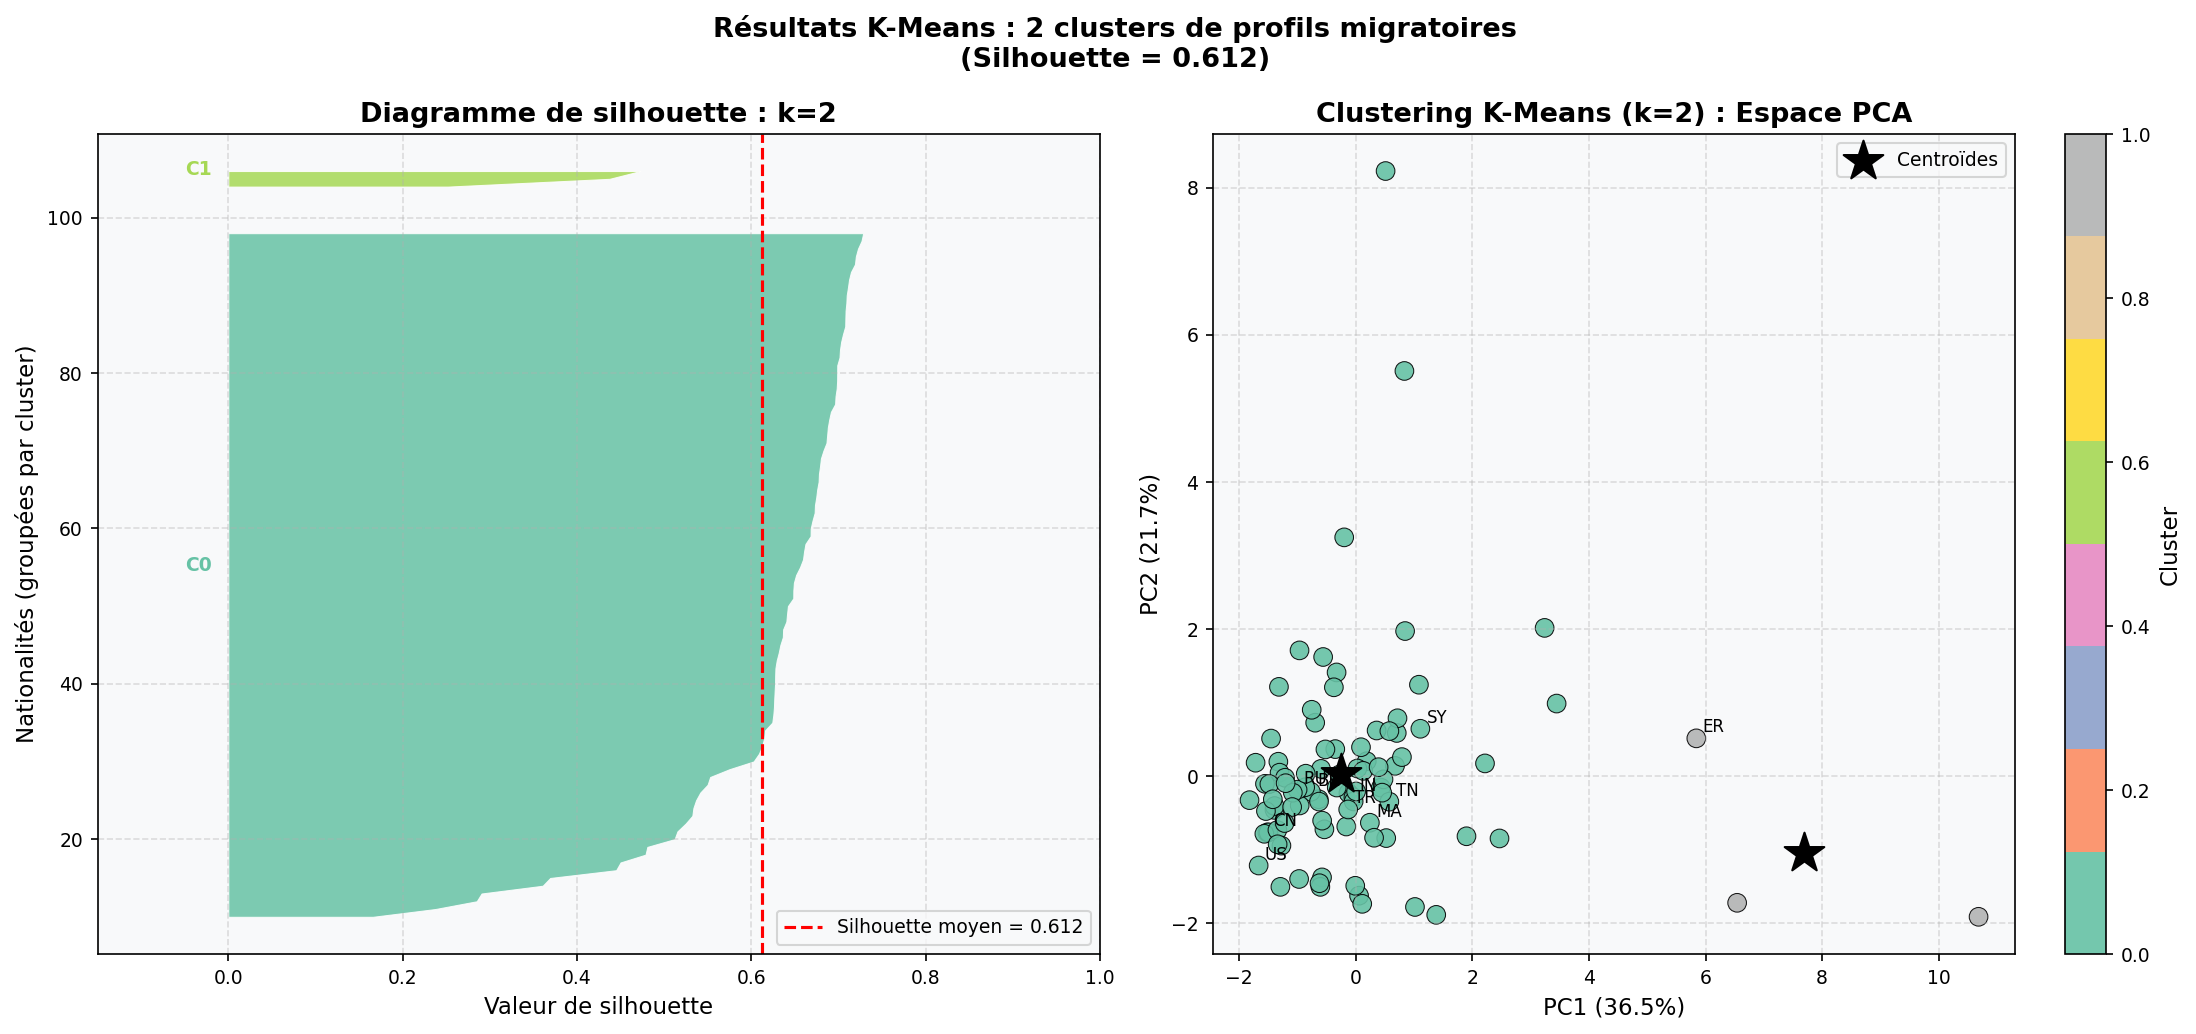


   Silhouette global : 0.612
   Inertie finale    : 628

   Distribution des clusters :
cluster
0    89
1     3
Name: count, dtype: int64


In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(15, 7))

# Silhouette plot par cluster
y_lower = 10 # petit espace entre les clusters
cluster_colors = [plt.cm.Set2(i / K_OPTIMAL) for i in range(K_OPTIMAL)]

for i in range(K_OPTIMAL):
    cluster_sil = np.sort(sil_vals[cluster_labels == i]) # On récupère uniquement les silhouettes du cluster.
    size = len(cluster_sil) # Nombre de nationalités dans ce cluster.
    y_upper = y_lower + size

    axes[0].fill_betweenx(np.arange(y_lower, y_upper), # Dessine la "barre" du cluster. Chaque ligne représente une nationalité.
                          0, cluster_sil,
                          facecolor=cluster_colors[i], alpha=0.85,
                          edgecolor='white', linewidth=0.5)
    axes[0].text(-0.05, y_lower + size/2, f'C{i}',
                 fontsize=9, color=cluster_colors[i], fontweight='bold')
    y_lower = y_upper + 5

mean_sil = silhouette_score(X_scaled, cluster_labels) # métrique globale.
axes[0].axvline(mean_sil, color='red', linestyle='--', linewidth=1.5,
                label=f'Silhouette moyen = {mean_sil:.3f}')
axes[0].set_xlabel('Valeur de silhouette')
axes[0].set_ylabel('Nationalités (groupées par cluster)')
axes[0].set_title(f'Diagramme de silhouette : k={K_OPTIMAL}')
axes[0].legend(loc='lower right')
axes[0].set_xlim([-0.15, 1.0])

# Projection PCA avec clusters
scatter = axes[1].scatter(X_pca[:, 0], X_pca[:, 1],
                          c=cluster_labels, cmap='Set2',
                          s=80, alpha=0.9, edgecolors='black', linewidths=0.5)

# Centroïdes dans l'espace PCA
centroids_pca = pca.transform(km_final.cluster_centers_)
axes[1].scatter(centroids_pca[:, 0], centroids_pca[:, 1],
                marker='*', s=400, c='black', zorder=10, label='Centroïdes')
                # * : représente le "centre" du cluster

for nat in df_feat_clust['volume_total'].nlargest(10).index:
    idx = df_feat_clust.index.get_loc(nat)
    axes[1].annotate(nat, (X_pca[idx, 0], X_pca[idx, 1]),
                     fontsize=8, xytext=(3, 3), textcoords='offset points')

axes[1].set_xlabel(f'PC1 ({pca.explained_variance_ratio_[0]*100:.1f}%)')
axes[1].set_ylabel(f'PC2 ({pca.explained_variance_ratio_[1]*100:.1f}%)')
axes[1].set_title(f'Clustering K-Means (k={K_OPTIMAL}) : Espace PCA')
plt.colorbar(scatter, ax=axes[1], label='Cluster')
axes[1].legend()

plt.suptitle(f'Résultats K-Means : {K_OPTIMAL} clusters de profils migratoires\n'
             f'(Silhouette = {mean_sil:.3f})',
             fontsize=13, fontweight='bold')
plt.tight_layout()

plt.show()

print(f"\n   Silhouette global : {mean_sil:.3f}") # Plus il est élevé, meilleure est la séparation entre les clusters.
print(f"   Inertie finale    : {km_final.inertia_:,.0f}")
print(f"\n   Distribution des clusters :")
print(df_feat_clust['cluster'].value_counts().sort_index())

- PC1 est dominé par

accélération

croissance

- PC2

covid_resilience

- Le cluster 1 contient seulement trois nationalités. Bien qu'il soit bien séparé du reste des données, sa faible taille conduit à l'interpréter comme un groupe atypique plutôt que comme un profil migratoire généralisable.


In [ ]:
# Loadings PCA : quelles features expliquent chaque axe
loadings = pd.DataFrame(
    pca.components_[:6].T,
    index=feat_cols,
    columns=['PC1', 'PC2','PC3','PC4','PC5', 'PC6']
).round(3)

print("Loadings PCA :")
print(loadings.sort_values('PC1', ascending=False))

Loadings PCA :
                    PC1    PC2    PC3    PC4    PC5    PC6
acceleration      0.858 -0.155  0.189  0.073 -0.039 -0.441
cagr              0.333 -0.016 -0.174 -0.479  0.205  0.476
cv_temporal       0.284 -0.026 -0.023  0.533 -0.050  0.605
covid_resilience  0.157  0.979 -0.052 -0.010  0.069 -0.069
is_crisis         0.080  0.016  0.023 -0.130 -0.013  0.119
share_educ       -0.018  0.010 -0.552  0.038 -0.645 -0.248
log_volume       -0.026 -0.084 -0.035 -0.500  0.275 -0.202
share_work       -0.091 -0.044 -0.296  0.454  0.661 -0.293
share_fami       -0.176  0.090  0.733  0.076 -0.144 -0.078


In [ ]:
profile = df_feat_clust.groupby('cluster')[feat_cols].mean().round(3)
print(profile.T)

# Qui est dans C1 (les outliers) ?
print("\n NATIONALITÉS CLUSTER 1 \n")
print(df_feat_clust[df_feat_clust['cluster']==1].index.tolist())

# Stats comparatives
for col in ['share_work', 'share_fami', 'share_educ', 'acceleration', 'covid_resilience', 'is_crisis']:
    c0 = df_feat_clust[df_feat_clust['cluster']==0][col].mean()
    c1 = df_feat_clust[df_feat_clust['cluster']==1][col].mean()
    print(f"{col:<20} C0={c0:.3f}  C1={c1:.3f}")

cluster               0       1
log_volume        7.032   7.124
cagr              0.096   0.440
share_work        0.191   0.027
share_fami        0.678   0.549
share_educ        0.068   0.009
covid_resilience  0.940   1.027
cv_temporal       0.614   0.964
acceleration      2.500  17.094
is_crisis         0.090   1.000

 NATIONALITÉS CLUSTER 1 

['ER', 'SD', 'YE']
share_work           C0=0.191  C1=0.027
share_fami           C0=0.678  C1=0.549
share_educ           C0=0.068  C1=0.009
acceleration         C0=2.500  C1=17.094
covid_resilience     C0=0.940  C1=1.027
is_crisis            C0=0.090  C1=1.000


C1 = 100% pays en crise (ER, SD, YE).

Interprétation :

- C0 "Migration structurelle" : 89 pays, Motif dominant (Familial) 67.8%, Part travail 19.1%, Accélération×2.5, CAGR 9.6%/an, Résilience COVID 0.94, is_crisis 9%                                                                                    
                                                               
- C1 "Migration de crise" : ER, SD, YE, Motif dominant (Familial) 54.9%, Part travail 2.7%, Accélération ×17, CAGR 44%/an, Résilience COVID 1.03, is_crisis 100%

C0 = flux migratoires portés par des dynamiques économiques et familiales stables, majorité des nationalités présentes au Luxembourg.

C1 = Les caractéristiques du cluster sont compatibles avec des flux associés à des contextes de crise humanitaire.


L'algorithme K-Means converge vers k=2 (Silhouette=0.612). Les critères de silhouette et de Davies-Bouldin identifient clairement k=2, tandis que la méthode du coude suggère une rupture de pente compatible avec cette solution.. Le Cluster 0 (89 nationalités) représente la migration structurelle luxembourgeoise, caractérisée par une dominance familiale (67.8%), une part professionnelle significative (19.1%) et une croissance soutenue (CAGR=9.6%). Le Cluster 1 (Érythrée, Soudan, Yémen) identifie une migration de crise humanitaire, distinguée par une accélération des flux (×17 sur 2013–2025), un CAGR de 44% et une absence de permis professionnels (2.7%). La résilience COVID supérieure à 1.0 de ce cluster confirme que ces flux sont insensibles aux cycles économiques, étant motivés par des facteurs géopolitiques exogènes.

Ce résultat est cohérent avec les travaux de Carling & Talleraas (2016) qui distinguent les migrations économiques des migrations forcées dans les données européennes.



---



Validation et interprétation des clusters obtenus avec K-Means. On utilise une Classification Hiérarchique Ascendante (CAH) pour voir si les groupes trouvés par K-Means sont cohérents, puis on résume les caractéristiques moyennes de chaque cluster.

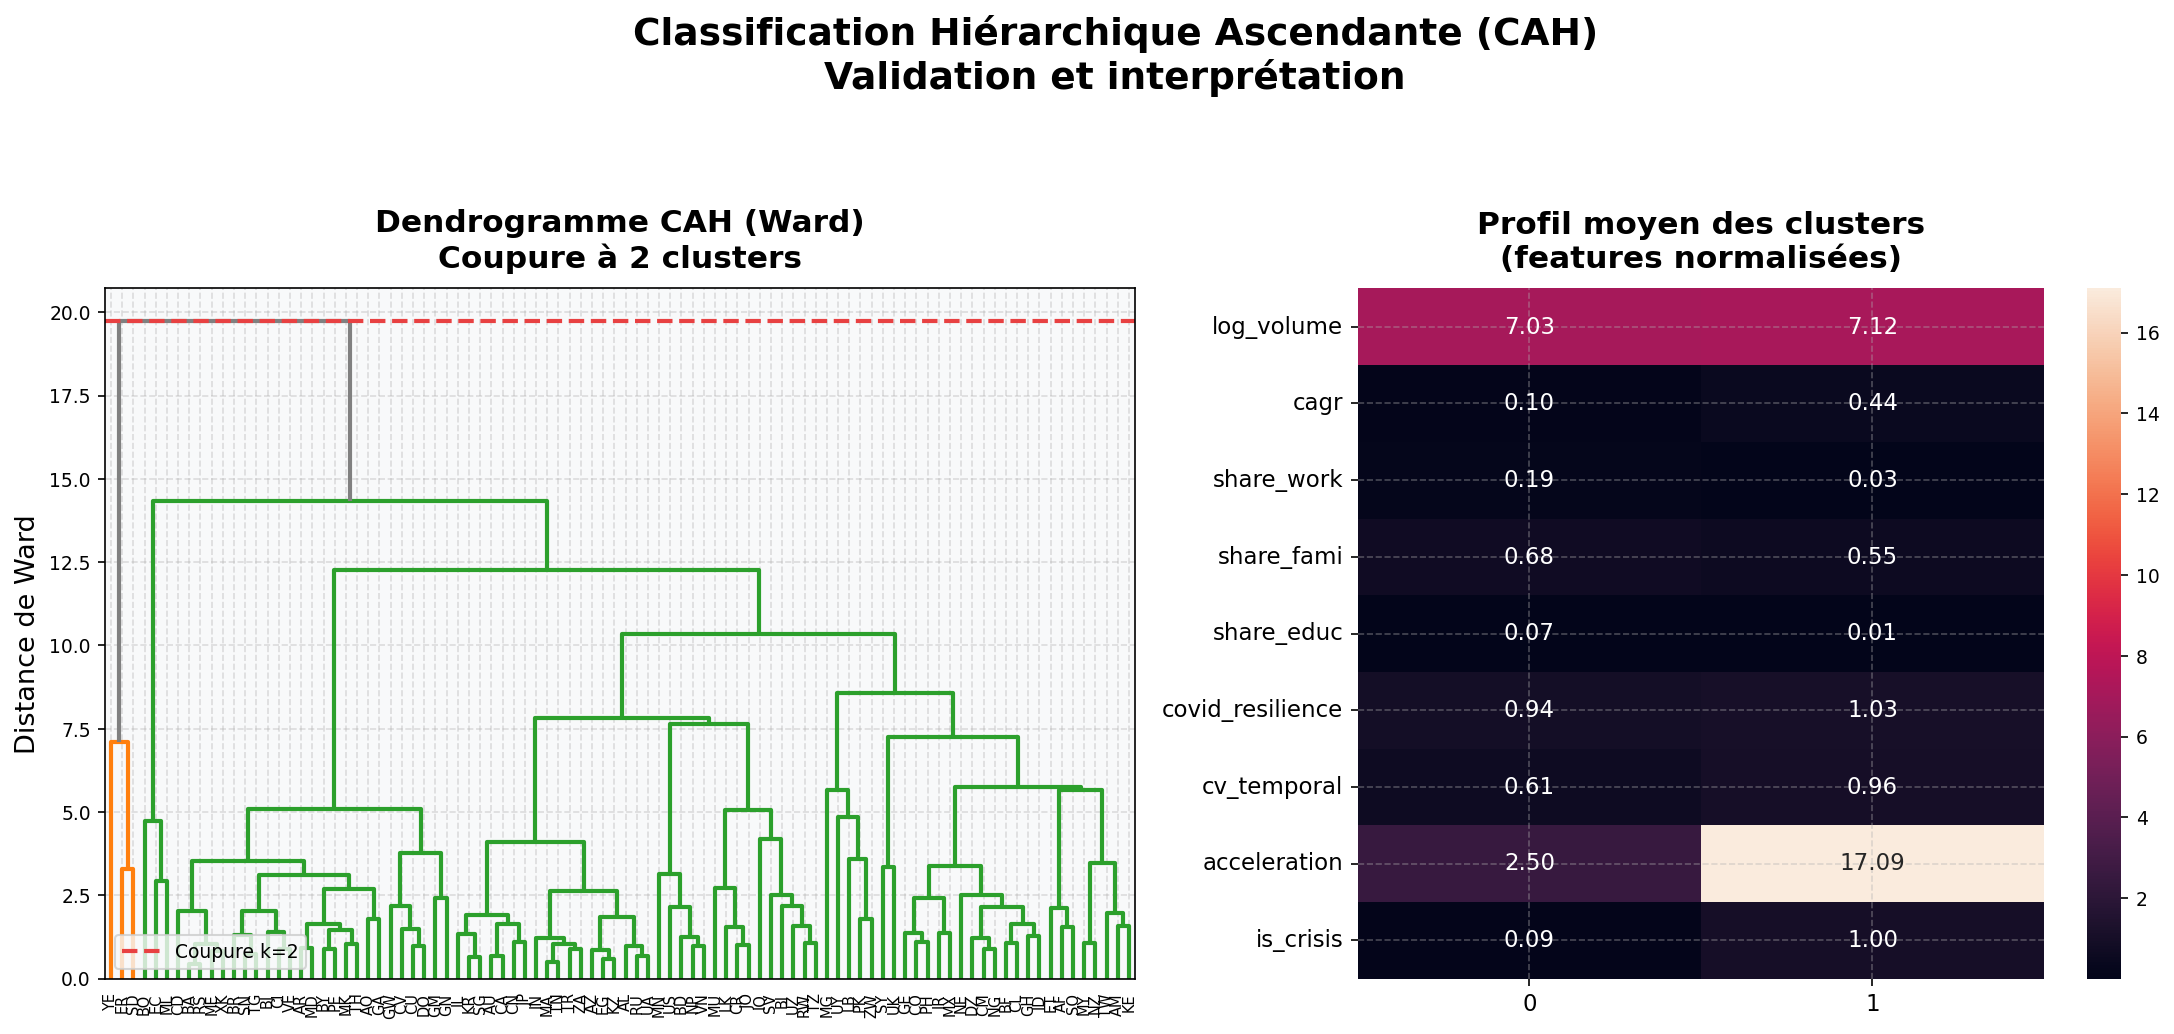

In [ ]:
# CAH : Validation et interprétation

# 4.5 CLASSIFICATION HIÉRARCHIQUE ASCENDANTE (CAH) / La CAH regarde les données d'abord, fusionne progressivement les nationalités les plus similaires, et montre le résultat sous forme d'arbre : le dendrogramme.
# Méthode de Ward (minimise la variance intra-cluster)
# Validation croisée avec K-Means

# Construction de la CAH, Contrairement à K-Means, la CAH ne fixe pas le nombre de clusters au départ.
linkage_matrix = linkage(X_scaled,
                         method='ward', # Ward est la méthode la plus utilisée pour des variables quantitatives. Elle cherche toujours à fusionner les groupes qui se ressemblent le plus.
                         metric='euclidean') # Comme on a normalisé les variables avec RobustScaler
# Figure
fig, axes = plt.subplots(
    1, 2,
    figsize=(15, 7),
    gridspec_kw={"width_ratios": [1.2, 1]})

# Dendrogramme complet pour représenter toutes les fusions réalisées.
threshold = linkage_matrix[-(K_OPTIMAL-1), 2]
dendrogram(
    linkage_matrix,
    labels=df_feat_clust.index.tolist(), # Feuilles du dendrogramme portent le code des nationalités.
    ax=axes[0],
    color_threshold=threshold,
    above_threshold_color="gray",
    leaf_rotation=90,
    leaf_font_size=7)

axes[0].axhline(
    threshold,
    color=PALETTE["accent1"],
    linestyle="--",
    linewidth=2,
    label=f"Coupure k={K_OPTIMAL}")

axes[0].set_title(
    f"Dendrogramme CAH (Ward)\nCoupure à {K_OPTIMAL} clusters",
    fontsize=15,
    fontweight="bold",
    pad=10)

axes[0].set_ylabel("Distance de Ward", fontsize=13)
axes[0].tick_params(axis='x', labelsize=7)
axes[0].legend()

# Heatmap des features par cluster (radar simplifié)
cluster_profiles = (
    df_feat_clust
    .groupby("cluster")[feat_cols]
    .mean())

# cluster_norm = (
#     (cluster_profiles - cluster_profiles.min()) /
#     (cluster_profiles.max() - cluster_profiles.min() + 1e-9))

# sns.heatmap(
#     cluster_norm.T,
#     ax=axes[1],
#     cmap="RdYlGn",
#     annot=True,
#     fmt=".2f",
#     annot_kws={"size":11},
#     linewidths=0.5,
#     xticklabels=[f"Cluster {i}" for i in cluster_profiles.index],
#     yticklabels=[c.replace("_"," ").title() for c in feat_cols],
#     cbar_kws={"label":"Valeur normalisée [0,1]"})

sns.heatmap(cluster_profiles.T,
            annot=True,
            fmt=".2f")

axes[1].set_title(
    "Profil moyen des clusters\n(features normalisées)",
    fontsize=15,
    fontweight="bold",
    pad=10)

axes[1].set_xlabel("")
axes[1].set_ylabel("")
axes[1].tick_params(axis='both', labelsize=11)

# TITRE GENERAL
fig.suptitle(
    "Classification Hiérarchique Ascendante (CAH)\nValidation et interprétation",
    fontsize=18,
    fontweight="bold",
    y=0.98
)
# Réserve de l'espace pour le titre général
fig.tight_layout(rect=[0, 0, 1, 0.92])
plt.show()

Tout en bas : chaque nationalité est seule

Les premières fusions (hauteur 0–2.5) : nationalités très similaires se regroupent
La grande coupure grise à gauche (hauteur ~20) : ER, SD, YE se séparent du reste, ils sont tellement différents que la CAH les fusionne en dernier
La ligne rouge pointillée représente le k=2.

Les analyses convergent vers une partition en deux groupes. Le premier rassemble l'immense majorité des nationalités (89 sur 92) et correspond à des profils migratoires relativement stables, dominés par le regroupement familial et une part non négligeable de migration de travail. Le second groupe est constitué de trois nationalités (Érythrée, Soudan et Yémen) présentant une forte accélération récente des flux, une croissance plus rapide et une très faible proportion de permis liés au travail. Compte tenu de sa faible taille, ce second cluster doit être interprété comme un groupe atypique plutôt que comme un profil migratoire représentatif. Ses caractéristiques sont néanmoins compatibles avec des flux associés à des contextes de crise humanitaire.

  INTERPRÉTATION DES CLUSTERS DE PROFILS MIGRATOIRES

  CLUSTER 0  :  89 nationalités

  Nationalités : AF, AL, AM, AO, AR, AU, AZ, BA, BD, BF, BI, BJ, BO, BR, BY, CA, CD, CI, CL, CM, CN, CO, CR, CU, CV, DO, DZ, EC, EG, ET, GA, GE, GH, GM, GN, GW, ID, IL, IN, IQ, IR, JO, JP, KE, KR, KZ, LB, LK, MA, MD, ME, MG, MK, ML, MN, MU, MX, MY, NE, NG, NP, NZ, PE, PH, PK, RS, RU, RW, SG, SN, SO, SV, SY, TG, TH, TN, TR, TW, TZ, UA, UK, US, UY, UZ, VE, VN, XK, ZA, ZW
  Volume moyen total   : 2,788 permis
  CAGR moyen           : 9.6%/an
  Part travail         : 19.1%
  Part famille         : 67.8%
  Part éducation       : 6.8%
  Résilience COVID     : 0.94
  Silhouette moyen     : 0.620
  CLUSTER 1  :  3 nationalités

  Nationalités : ER, SD, YE
  Volume moyen total   : 3,999 permis
  CAGR moyen           : 44.0%/an
  Part travail         : 2.7%
  Part famille         : 54.9%
  Part éducation       : 0.9%
  Résilience COVID     : 1.03
  Silhouette moyen     : 0.387


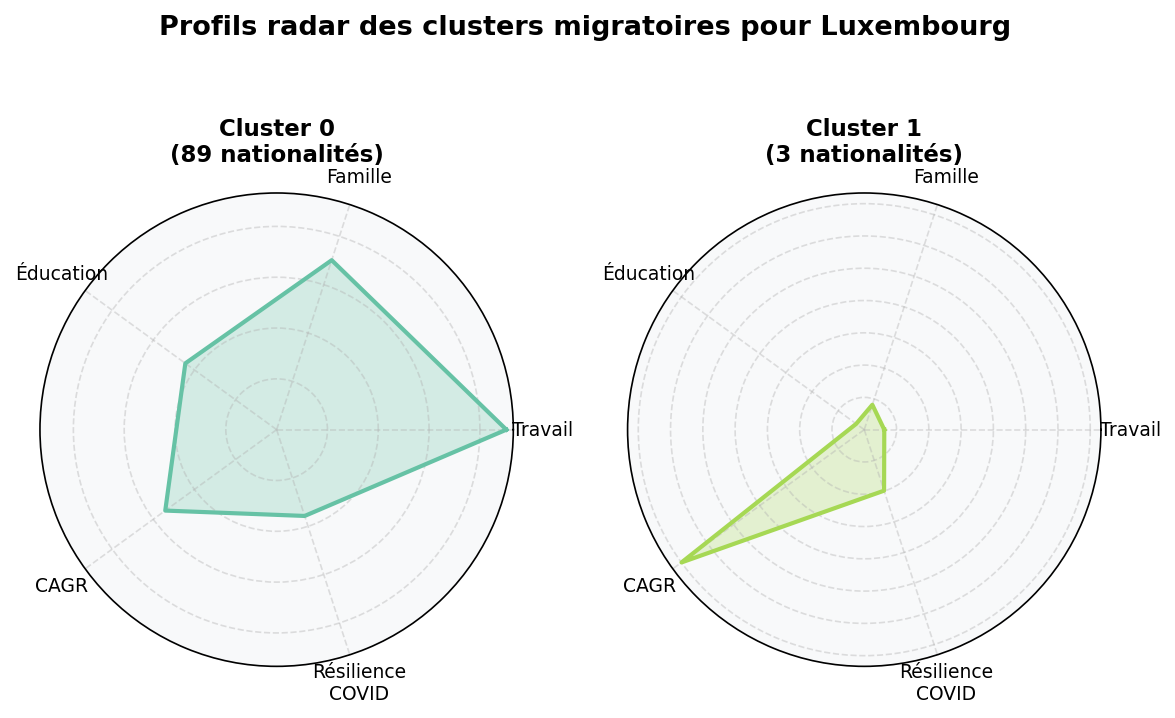

In [ ]:
# 4.6 INTERPRÉTATION DES CLUSTERS

print("  INTERPRÉTATION DES CLUSTERS DE PROFILS MIGRATOIRES\n")

for c in sorted(df_feat_clust['cluster'].unique()): # contient le numéro du cluster attribué par K-Means.
  grp = df_feat_clust[df_feat_clust['cluster'] == c]
  print(f"  CLUSTER {c}  :  {len(grp)} nationalités\n") # Sélection des nationalités du cluster
  print(f"  Nationalités : {', '.join(grp.index.tolist())}") # Liste des nationalités
  print(f"  Volume moyen total   : {grp['volume_total'].mean():,.0f} permis")
  print(f"  CAGR moyen           : {grp['cagr'].mean()*100:.1f}%/an")
  print(f"  Part travail         : {grp['share_work'].mean()*100:.1f}%")
  print(f"  Part famille         : {grp['share_fami'].mean()*100:.1f}%")
  print(f"  Part éducation       : {grp['share_educ'].mean()*100:.1f}%")
  print(f"  Résilience COVID     : {grp['covid_resilience'].mean():.2f}")
  print(f"  Silhouette moyen     : {grp['silhouette'].mean():.3f}")


# Visualisation radar des profils (dessiner le profil moyen de chaque cluster)
from matplotlib.patches import FancyArrowPatch

radar_features = ['share_work', 'share_fami', 'share_educ', 'cagr', 'covid_resilience'] # Chaque rayon du radar représente une caractéristique.
radar_labels   = ['Travail', 'Famille', 'Éducation', 'CAGR', 'Résilience\nCOVID']

cluster_profiles_radar = df_feat_clust.groupby('cluster')[radar_features].mean() # Calcul du profil moyen
N = len(radar_features)
angles = np.linspace(0, 2*np.pi, N, endpoint=False).tolist() # découper le cercle.
angles += angles[:1]  # fermer le polygone

fig, axes = plt.subplots(1, K_OPTIMAL, figsize=(4*K_OPTIMAL, 5),
                         subplot_kw=dict(polar=True))
if K_OPTIMAL == 1:
    axes = [axes]

for idx, (c, row) in enumerate(cluster_profiles_radar.iterrows()):
    values = []
    for feat in radar_features:
        vmin = df_feat_clust[feat].min()
        vmax = df_feat_clust[feat].max()
        values.append((row[feat] - vmin) / (vmax - vmin + 1e-9)) # cette formule ramène toutes les variables entre 0 et 1, ce qui les rend comparables sur un même radar.
    values += values[:1]

    ax = axes[idx]
    ax.fill(angles, values, alpha=0.25, color=plt.cm.Set2(idx / K_OPTIMAL))
    ax.plot(angles, values, linewidth=2, color=plt.cm.Set2(idx / K_OPTIMAL))
    ax.set_xticks(angles[:-1])
    ax.set_xticklabels(radar_labels, size=9)
    ax.set_yticklabels([])
    n_members = (df_feat_clust['cluster'] == c).sum()
    ax.set_title(f'Cluster {c}\n({n_members} nationalités)', size=11, fontweight='bold', pad=15)

plt.suptitle('Profils radar des clusters migratoires pour Luxembourg', fontsize=13, fontweight='bold', y=1.02) # un graphique où chaque cluster est représenté par une forme différente, permettant de comparer visuellement leurs profils migratoires.
plt.tight_layout()
plt.show()


# Contribution originale  

- un indice de stabilité migratoire,

- un modèle de prévision par cluster,

- une prévision hiérarchique,

- une détection automatique des ruptures,
